# Abi Farraj et al.- WQT Markets - Figs. 3 and 4

In [40]:
file = 'Figures/'

# import data

import pandas as pd
import os
import numpy as np

if not os.path.exists(file):
    os.makedirs(file)
if not os.path.exists(file + '/SI'):
    os.makedirs(file + '/SI')

# function that creates dataframe from list of files in a path
def create_dataframe_sensitivity(path, tag):
# get all files in the path
    files = os.listdir(path)

    # create a dictionary to store all dataframes
    dfs = {}

    for file in files:
        if file.endswith('.csv'):
            # read the csv file
            df = pd.read_csv(path+file)

            # if file includes tag in name
            if tag in file:
                # create string with only the characters before "_summary.csv"
                mult = file.split('_summary.csv')[0]
                mult = mult.split(tag)[1]
                # save the dataframe in the dictionary
                try: 
                    mult = float(mult)
                    dfs[mult] = df
                except:
                    pass
    
    # sort the dictionary by key
    keys = {float(key):key for key in dfs.keys()}
    sorted_dfs = {}
    for key in sorted(keys.keys()):
        sorted_dfs[keys[key]] = dfs[keys[key]]
    return sorted_dfs


# function that creates dataframe for a single WWTP in a path
def read_csv(path, tag, w):
    path_tag = path + f'results_{tag}_{w}.csv'
    df_tag = pd.read_csv(path_tag)
    df_tag.rename(columns={df_tag.columns[0]: 'Datetime'}, inplace=True)
    df_tag.Datetime = pd.to_datetime(df_tag.Datetime)
    return df_tag


# function that creates dataframe from list of files in a path
def create_dataframe(path, tag, WWTPs):
# get all files in the path
    files = os.listdir(path)

    # create a dictionary to store all dataframes
    dfs = {}

    for file in files:
        if file.endswith('.csv'):
            # read the csv file
            df = pd.read_csv(path+file)

            if tag == 'results_finance':
                if 'results_finance' not in file:
                    continue
                WWTP= file.split(tag + '_')[1]
                WWTP = WWTP.split('.csv')[0]
                dfs[WWTP] = df

            elif tag == 'results':
                if 'results' not in file:
                    continue
                WWTP = file.split('results_')[1]
                WWTP = WWTP.split('.csv')[0]
                #print(WWTP)
                if WWTP not in WWTPs:
                    continue
                if 'econ' not in WWTP:
                    dfs[WWTP] = df
            
            # if file includes tag in name
            elif tag in file:
                # create string with only the characters after "results_econ_"
                WWTP= file.split('results_' + tag + '_')[1]
                WWTP = WWTP.split('.csv')[0]
                dfs[WWTP] = df
                
    return dfs
                    

def create_df(WWTP, dfs):
    df = dfs[WWTP]
    df.rename(columns={df.columns[0]: 'Datetime'}, inplace=True)
    df.Datetime = pd.to_datetime(df.Datetime)
    df['Year'] = df.Datetime.dt.year
    
    return df


def create_df_finance_econ(path, WWTPs):
    df_all_WWTPs = pd.DataFrame()
    for WWTP in WWTPs:
        path_finance = path + f'results_finance_{WWTP}.csv'
        path_econ = path + f'results_econ_{WWTP}.csv'
        path_nondiscounted = path + f'results_nondiscounted_finance_{WWTP}.csv'
        
        df_finance = pd.read_csv(path_finance, index_col=0)
        df_finance = df_finance.reset_index().rename(columns={"index": "Datetime"})
        df_econ = pd.read_csv(path_econ, index_col=0)
        df_econ = df_econ.reset_index().rename(columns={"index": "Datetime"})
        df_nondisc = pd.read_csv(path_nondiscounted, index_col=0)
        df_nondisc = df_nondisc.reset_index().rename(columns={"index": "Datetime"})
        
        # merge but only keep duplicate data from left
        df_finance = pd.merge(df_finance, df_nondisc[['Datetime', 'Opex_treated_for_trade', 'Total_capex_lumpsum']], on="Datetime", how="left")
        df_w = pd.merge(df_econ, df_finance, on="Datetime", how="left", suffixes=('_NPV', '_finance'))
        df_w['WWTP'] = WWTP
        df_all_WWTPs = pd.concat([df_all_WWTPs, df_w], axis=0)
        df_all_WWTPs.Datetime = pd.to_datetime(df_all_WWTPs.Datetime)
        df_all_WWTPs['Year'] = df_all_WWTPs.Datetime.dt.year

    return df_all_WWTPs

def change_dict_to_df(data_dict, column):
    df_credit = pd.DataFrame.from_dict(data_dict, orient='index', columns=column)
    df_credit = df_credit.reset_index()
    df_credit[['WWTP', 'Year']] = pd.DataFrame(df_credit['index'].tolist(), index=df_credit.index)
    df_credit = df_credit.drop(columns=['index'])
    # only show years from 10 to 30
    df_credit = df_credit[df_credit['Year'] >= 10]
    df_credit = df_credit[df_credit['Year'] <= 29]
    return df_credit

## Functions to calculate market performance for buyer

In [41]:
def simulate_EM_market(df, df_NC, WWTPs, percent_saving = {'Palo Alto': 0.5, 'SJSC': 0.5, 'Sunnyvale': 0.5}):
    # uniform-price double-auction exchange with an average-cost reserve  
    bid_purchase = {}; market_clearing_price = {}; market_credit_cost = {}; unit_cost_avoided_cost = {};
    
    units_bought_target_buyer = {}; willingness_to_pay = {}; avoided_cost = {}; unit_cost_bid = {}; units_sold_target = {}; WWTP_unit_cost = {}; units_sold_target_seller = {}

    opex_treated_for_trade = {}; total_capex_lumpsum = {}

    total_CoC= {}; EM_rev = {}; EM_payment = {}; CH_rev = {}; CH_payment = {}; BT_rev = {}; BT_payment = {}; average_bilat_price = {}; seller_unit_cost = {}
    
    annual_CoC_NC = {}; required_removal = {}; compliance_yr = {}; annual_capex_NC = {}

    avoided_buyer = {}; avoided_seller = {}

    seller_reserve = {}

    eps = 0.01
    
    df['Bought_credits'] = (df['Bought_credits_finance']* 0 + 1).where(df['Total_units_bought'] > eps, 0)
    df['Avoided_CoC'] = (df_NC['Annual_CoC'] - df['Annual_capex'] - df['Annual_opex'])* df.Compliance_yr
    
    years = df['Year'].unique()
    exchange_market_rows = []

    for year in years:
        
        for w in WWTPs:
            df_w_year = df[(df['WWTP'] == w) & (df['Year'] == year)]
            df_NC_w_year = df_NC[(df_NC['WWTP'] == w) & (df_NC['Year'] == year)]
            required_removal[w,year] = df_w_year.Required_removal.values[0]
            compliance_yr[w,year] = df_w_year.Compliance_yr.values[0]
            total_CoC[w,year] = df_w_year.Annual_capex.values[0] + df_w_year.Annual_opex.values[0]
            total_capex_lumpsum[w,year] = df_w_year.Total_capex_lumpsum.values[0]
            opex_treated_for_trade[w,year] = df_w_year.Opex_treated_for_trade.values[0]
            units_bought_target_buyer[w, year] = df_w_year.Total_units_bought.values[0]
            units_sold_target_seller[w, year] = df_w_year.Total_units_sold.values[0]
            annual_CoC_NC[w,year] = df_NC_w_year.Annual_CoC.values[0]
            annual_capex_NC[w,year] = df_NC_w_year.Annual_capex.values[0]
            avoided_cost[w, year] = df_w_year.Avoided_CoC.values[0]
            willingness_to_pay[w, year] = avoided_cost[w, year] * (1- percent_saving[w])
            unit_cost_avoided_cost[w, year] = avoided_cost[w, year] / units_bought_target_buyer[w, year] * (10**6/30) if units_bought_target_buyer[w, year] > 0 else 0
            unit_cost_bid[w, year] = willingness_to_pay[w, year] / units_bought_target_buyer[w, year] * (10**6/30) if units_bought_target_buyer[w, year] > 0 else 0
            seller_unit_cost[w, year] = (df_w_year.Annual_capex.values[0] + df_w_year.Annual_opex.values[0])/(df_w_year.Annual_treated.values[0]) * (10**6/30) if units_sold_target_seller[w,year] > 0 else 0  # $/lb
        
        # Buyers active this year. (unit_cost_bid = BUYER bids, per your mapping.)
        # Select on quantity, not bid (your convention zeros the bid for non-buyers).
        buyer_bids = [
            unit_cost_bid[w, year]
            for w in WWTPs
            if units_bought_target_buyer[w, year] > 0
        ]

        # No demand -> no market this year.
        if not buyer_bids:
            market_clearing_price[year] = 0.0
            seller_reserve[year] = 0.0

        else:
            # Sellers active this year. seller_unit_cost = each seller's AVERAGE COST.
            seller_avg_costs = [
                seller_unit_cost[w, year]
                for w in WWTPs
                if units_sold_target_seller[w, year] > 0
            ]

            # Per-seller average-cost reserve. Because every unit clears (captive buyers),
            # every seller sells, so the binding reserve is the most expensive seller's
            # average cost -- the floor that keeps even the marginal plant whole.
            seller_reserve[year] = max(seller_avg_costs) if seller_avg_costs else 0.0

            # Last-accepted bid ABOVE the reserve. Among buyers bidding at or above the
            # reserve, the marginal (lowest) such bid sets the uniform price. Bids below
            # the reserve are out of the money: captive buyers still pay the clearing
            # price, but those low bids no longer drag it down.
            bids_above_reserve = [b for b in buyer_bids if b >= seller_reserve[year]]

            if bids_above_reserve:
                market_clearing_price[year] = min(bids_above_reserve)
            else:
                # No buyer clears the reserve -> price drops to the reserve (cost-recovery floor).
                market_clearing_price[year] = seller_reserve[year]

        for w in WWTPs:
            EM_payment[w, year] = market_clearing_price[year] * units_bought_target_buyer[w, year] / (10**6/30)
            EM_rev[w,year] = market_clearing_price[year] * units_sold_target_seller[w, year] / (10**6/30)

                
        # Assess if avoided_costs is from being a buyer or seller in the market:
        for w in WWTPs:
            ## First compare built capacity in market vs no market
            df_market_w_year = df[(df['WWTP'] == w) & (df['Year'] == year)]
            df_NC_w_year = df_NC[(df_NC['WWTP'] == w) & (df_NC['Year'] == year)] 
            
            capex_market = df_market_w_year.Annual_capex.values[0]
            capex_NC = df_NC_w_year.Annual_capex.values[0]
            opex_market = df_market_w_year.Annual_opex.values[0]

            opex_NC = df_NC_w_year.Annual_opex.values[0]
            avoided_buyer[w, year] = 0; avoided_seller[w, year] = 0;
            
            # if capacity is smaller than NC
            if capex_market < capex_NC and df_market_w_year.Compliance_yr.values[0] == 1:
                #print(f'     WWTP: {w} with capex_market {round(capex_market,1)} < capex_NC {round(capex_NC,1)}')
                # then if you buy credits, then all avoided costs is for being a buyer
                if units_bought_target_buyer[w, year] > eps:
                    avoided_buyer[w, year] = (capex_NC - capex_market) + (opex_NC - opex_market)    #positive
                    avoided_seller[w, year] = 0
                
                # if you sell credits, then avoided capex and opex is from being a buyer and the additional opex to sell credits is from being a seller in the market
                elif units_sold_target_seller[w, year] > eps:
                    avoided_seller[w, year] = -opex_treated_for_trade[w, year]
                    avoided_buyer[w, year] = (capex_NC - capex_market) + (opex_NC - opex_market + opex_treated_for_trade[w, year])
                
                # if you don't sell or buy credits, then avoided capex and opex is from being a buyer
                else:
                    avoided_buyer[w, year] = (capex_NC - capex_market) + (opex_NC - opex_market)
                    avoided_seller[w, year] = 0
            
            elif df_market_w_year.Compliance_yr.values[0] == 1:
                # Build larger to sell credits
                # if you sell credits, then avoided capex and opex is from being a seller
                if units_sold_target_seller[w, year] > eps:
                    avoided_seller[w, year] = (capex_NC - capex_market) + (opex_NC - opex_market)
                    avoided_buyer[w, year] = 0
                
                # if you buy credits, then difference is capex is due to being a seller, and difference in opex is for being a buyer
                elif units_bought_target_buyer[w, year] > eps:
                    avoided_seller[w, year] = (capex_NC - capex_market)
                    avoided_buyer[w, year] = (opex_NC - opex_market)
                
                # if you don't buy or sell credits then difference in capex and opex is from being a seller
                else:
                    avoided_seller[w, year] = (capex_NC - capex_market) + (opex_NC - opex_market)
                    avoided_buyer[w, year] = 0
                #print(f'     WWTP: {w} with capex_market {round(capex_market,1)} >= capex_NC {round(capex_NC,1)}')
            #print(f'     WWTP {w}:  Avoided_Cost: {round(avoided_cost[w, year],2)}, Avoided_buyer: {round(avoided_buyer[w, year],2)}, Avoided_seller: {round(avoided_seller[w, year],2)}')
            
        
        
        exchange_market_rows.append({
            'Year': year,
            'Market_clearing_price': market_clearing_price[year],
            'Seller_reserve': seller_reserve[year],
            **{f'{w}_required_removal': required_removal[w, year] for w in WWTPs},
            **{f'{w}_compliance_yr': compliance_yr[w, year] for w in WWTPs},
            **{f'{w}_bid': unit_cost_bid[w, year] for w in WWTPs},
            **{f'{w}_units_bought': units_bought_target_buyer[w, year] for w in WWTPs},
            **{f'{w}_units_sold': units_sold_target_seller[w, year] for w in WWTPs},
            **{f'{w}_unit_cost_avoided': unit_cost_avoided_cost[w, year] for w in WWTPs},
            **{f'{w}_avoided_cost': avoided_cost[w, year] for w in WWTPs},
            **{f'{w}_avoided_cost_buyer': avoided_buyer[w, year] for w in WWTPs},
            **{f'{w}_avoided_cost_seller': avoided_seller[w, year] for w in WWTPs},
            **{f'{w}_payment': EM_payment[w, year] for w in WWTPs},
            **{f'{w}_revenue': EM_rev[w, year] for w in WWTPs},
            **{f'{w}_opex_treated_for_trade': opex_treated_for_trade[w, year] for w in WWTPs},
            **{f'{w}_total_capex_lumpsum': total_capex_lumpsum[w, year] for w in WWTPs},
            **{f'{w}_total_CoC': total_CoC[w, year] for w in WWTPs},
            **{f'{w}_market_CoC': total_CoC[w,year] - EM_rev[w, year] + EM_payment[w, year] for w in WWTPs},
            **{f'{w}_annual_CoC_NC': annual_CoC_NC[w,year] for w in WWTPs},
            **{f'{w}_annual_capex_NC': annual_capex_NC[w,year] for w in WWTPs}
        })

    exchange_market = pd.DataFrame(exchange_market_rows)    
    
    return exchange_market



def simulate_CH_market(df, df_NC, WWTPs, capex_weight = 1.0, opex_weight = 1.0):
    market_credit_cost = {}; unit_cost_avoided_cost = {};
    
    units_bought_target_buyer = {}; avoided_cost = {}; unit_cost_bid = {}; units_sold_target = {}; WWTP_unit_cost = {}; units_sold_target_seller = {}

    opex_treated_for_trade = {}; total_capex_lumpsum = {}

    total_CoC= {}; CH_rev = {}; CH_payment = {}; 
    
    annual_CoC_NC = {}; required_removal = {}; compliance_yr = {}; annual_capex_NC = {}

    avoided_buyer = {}; avoided_seller = {}


    #df['Avoided_CoC'] = (df.Annual_CoC_NC - df.Annual_capex - df.Annual_opex)*df.Bought_credits_finance
    eps = 0.01
    df['Bought_credits'] = (df['Bought_credits_finance']* 0 + 1).where(df['Total_units_bought'] > eps, 0)
    df['Avoided_CoC'] = (df_NC['Annual_CoC'] - df['Annual_capex'] - df['Annual_opex'])* df.Compliance_yr
    
    years = df['Year'].unique()
    exchange_market_rows = []
    bilat_trade_rows = []
    
    

    
    for year in years:
        market_credit_cost[year] = 0
        
        for w in WWTPs:
            df_w_year = df[(df['WWTP'] == w) & (df['Year'] == year)]
            df_NC_w_year = df_NC[(df_NC['WWTP'] == w) & (df_NC['Year'] == year)]
            required_removal[w,year] = df_w_year.Required_removal.values[0]
            compliance_yr[w,year] = df_w_year.Compliance_yr.values[0]
            total_CoC[w,year] = df_w_year.Annual_capex.values[0] + df_w_year.Annual_opex.values[0]
            total_capex_lumpsum[w,year] = df_w_year.Total_capex_lumpsum.values[0]
            opex_treated_for_trade[w,year] = df_w_year.Opex_treated_for_trade.values[0]
            units_bought_target_buyer[w, year] = df_w_year.Total_units_bought.values[0]
            units_sold_target_seller[w, year] = df_w_year.Total_units_sold.values[0]
            annual_CoC_NC[w,year] = df_NC_w_year.Annual_CoC.values[0]
            annual_capex_NC[w,year] = df_NC_w_year.Annual_capex.values[0]
            avoided_cost[w, year] = df_w_year.Avoided_CoC.values[0]
            unit_cost_avoided_cost[w, year] = avoided_cost[w, year] / units_bought_target_buyer[w, year] * (10**6/30) if units_bought_target_buyer[w, year] > 0 else 0
            WWTP_unit_cost[w, year] = (df_w_year.Annual_capex.values[0]*capex_weight + df_w_year.Annual_opex.values[0]*opex_weight)/(df_w_year.Annual_treated.values[0]) * (10**6/30) if units_sold_target_seller[w,year] > 0 else 0  # $/lb

        
        # Calculate market_clearing costs
        average_clearinghouse_price = sum(WWTP_unit_cost[w, year]* units_sold_target_seller[w, year] for w in WWTPs)/ sum(units_sold_target_seller[w, year] for w in WWTPs) if sum(units_sold_target_seller[w, year] for w in WWTPs) > 0 else 0


        for w in WWTPs:            
            CH_payment[w, year] = average_clearinghouse_price * units_bought_target_buyer[w, year] / (10**6/30)
            CH_rev[w,year] = WWTP_unit_cost[w, year] * units_sold_target_seller[w, year] / (10**6/30)

        
        
        # Assess if avoided_costs is from being a buyer or seller in the market:
        #print(f'Year: {year}')
        for w in WWTPs:
            ## First compare built capacity in market vs no market
            df_market_w_year = df[(df['WWTP'] == w) & (df['Year'] == year)]
            df_NC_w_year = df_NC[(df_NC['WWTP'] == w) & (df_NC['Year'] == year)] 
            
            capex_market = df_market_w_year.Annual_capex.values[0]
            capex_NC = df_NC_w_year.Annual_capex.values[0]
            opex_market = df_market_w_year.Annual_opex.values[0]

            opex_NC = df_NC_w_year.Annual_opex.values[0]
            avoided_buyer[w, year] = 0; avoided_seller[w, year] = 0;
            
            # if capacity is smaller than NC
            if capex_market < capex_NC and df_market_w_year.Compliance_yr.values[0] == 1:
                #print(f'     WWTP: {w} with capex_market {round(capex_market,1)} < capex_NC {round(capex_NC,1)}')
                # then if you buy credits, then all avoided costs is for being a buyer
                if units_bought_target_buyer[w, year] > eps:
                    avoided_buyer[w, year] = (capex_NC - capex_market) + (opex_NC - opex_market)    #positive
                    avoided_seller[w, year] = 0
                
                # if you sell credits, then avoided capex and opex is from being a buyer and the additional opex to sell credits is from being a seller in the market
                elif units_sold_target_seller[w, year] > eps:
                    avoided_seller[w, year] = -opex_treated_for_trade[w, year]
                    avoided_buyer[w, year] = (capex_NC - capex_market) + (opex_NC - opex_market + opex_treated_for_trade[w, year])
                
                # if you don't sell or buy credits, then avoided capex and opex is from being a buyer
                else:
                    avoided_buyer[w, year] = (capex_NC - capex_market) + (opex_NC - opex_market)
                    avoided_seller[w, year] = 0
            
            elif df_market_w_year.Compliance_yr.values[0] == 1:
                # Build larger to sell credits
                # if you sell credits, then avoided capex and opex is from being a seller
                if units_sold_target_seller[w, year] > eps:
                    avoided_seller[w, year] = (capex_NC - capex_market) + (opex_NC - opex_market)
                    avoided_buyer[w, year] = 0
                
                # if you buy credits, then difference is capex is due to being a seller, and difference in opex is for being a buyer
                elif units_bought_target_buyer[w, year] > eps:
                    avoided_seller[w, year] = (capex_NC - capex_market)
                    avoided_buyer[w, year] = (opex_NC - opex_market)
                
                # if you don't buy or sell credits then difference in capex and opex is from being a seller
                else:
                    avoided_seller[w, year] = (capex_NC - capex_market) + (opex_NC - opex_market)
                    avoided_buyer[w, year] = 0
                #print(f'     WWTP: {w} with capex_market {round(capex_market,1)} >= capex_NC {round(capex_NC,1)}')
            #print(f'     WWTP {w}:  Avoided_Cost: {round(avoided_cost[w, year],2)}, Avoided_buyer: {round(avoided_buyer[w, year],2)}, Avoided_seller: {round(avoided_seller[w, year],2)}')
            
        
        
        exchange_market_rows.append({
            'Year': year,
            'Clearinghouse_price_avg': average_clearinghouse_price,            
            **{f'{w}_required_removal': required_removal[w, year] for w in WWTPs},
            **{f'{w}_compliance_yr': compliance_yr[w, year] for w in WWTPs},
            **{f'{w}_units_bought': units_bought_target_buyer[w, year] for w in WWTPs},
            **{f'{w}_units_sold': units_sold_target_seller[w, year] for w in WWTPs},
            **{f'{w}_unit_cost_avoided': unit_cost_avoided_cost[w, year] for w in WWTPs},
            **{f'{w}_avoided_cost': avoided_cost[w, year] for w in WWTPs},
            **{f'{w}_avoided_cost_buyer': avoided_buyer[w, year] for w in WWTPs},
            **{f'{w}_avoided_cost_seller': avoided_seller[w, year] for w in WWTPs},
            **{f'{w}_payment': CH_payment[w, year] for w in WWTPs},
            **{f'{w}_revenue': CH_rev[w, year] for w in WWTPs},
            **{f'{w}_clearinghouse_price': WWTP_unit_cost[w, year] for w in WWTPs},
            **{f'{w}_opex_treated_for_trade': opex_treated_for_trade[w, year] for w in WWTPs},
            **{f'{w}_total_capex_lumpsum': total_capex_lumpsum[w, year] for w in WWTPs},
            **{f'{w}_total_CoC': total_CoC[w, year] for w in WWTPs},
            **{f'{w}_market_CoC': total_CoC[w,year] - CH_rev[w, year] + CH_payment[w, year] for w in WWTPs},
            **{f'{w}_annual_CoC_NC': annual_CoC_NC[w,year] for w in WWTPs},
            **{f'{w}_annual_capex_NC': annual_capex_NC[w,year] for w in WWTPs}
        })

    clearinghouse_market = pd.DataFrame(exchange_market_rows)
    
    return clearinghouse_market




def simulate_bilat_trade(df, df_NC, WWTPs, BT_market_bid_tag, percent_saving = {'Palo Alto': 0.5, 'SJSC': 0.5, 'Sunnyvale': 0.5}, capex_weight = 1.0, opex_weight = 1.0):
    bid_purchase = {}; market_clearing_price = {}; market_credit_cost = {}; unit_cost_avoided_cost = {};
    
    units_bought_target_buyer = {}; willingness_to_pay = {}; avoided_cost = {}; unit_cost_bid = {}; WWTP_unit_cost = {}; units_sold_target_seller = {}

    opex_treated_for_trade = {}; total_capex_lumpsum = {}

    total_CoC= {}; EM_rev = {}; EM_payment = {}; CH_rev = {}; CH_payment = {}; BT_rev = {}; BT_payment = {}; average_bilat_price = {};average_bilat_price_buyer_bid = {}; average_bilat_price_seller_bid = {}
    
    annual_CoC_NC = {}; required_removal = {}; compliance_yr = {}; annual_capex_NC = {}

    avoided_buyer = {}; avoided_seller = {}
    


    eps = 0.01
    df['Bought_credits'] = (df['Bought_credits_finance']* 0 + 1).where(df['Total_units_bought'] > eps, 0)
    df['Avoided_CoC'] = (df_NC['Annual_CoC'] - df['Annual_capex'] - df['Annual_opex'])* df.Compliance_yr
    
    years = df['Year'].unique()
    
    for w in WWTPs:
        df_w = df[df['WWTP'] == w]
        if df_w.Total_units_bought.sum() > eps:
            average_bilat_price_buyer_bid[w] = sum(df_w.Avoided_CoC)* (1- percent_saving[w]) / sum(df_w.Total_units_bought) * (10**6/30)
            WWTP_bilat_buyer = [w]
        else:
            average_bilat_price_buyer_bid[w] = 0
        
        if df_w.Total_units_sold.sum() > eps:
            WWTP_bilat_seller = [w]
            average_bilat_price_seller_bid[w] = (sum(df_w.Annual_capex * df_w.Compliance_yr)*capex_weight + sum(df_w.Annual_opex * df_w.Compliance_yr)*opex_weight)/sum(df_w.Annual_treated) * (10**6/30)
        else:
            average_bilat_price_seller_bid[w] = 0
    
    for w in WWTP_bilat_seller:
        average_bilat_price_buyer_bid[w] = sum(average_bilat_price_buyer_bid[w] for w in WWTPs)
    
    for w in WWTP_bilat_buyer:
        average_bilat_price_seller_bid[w] = sum(average_bilat_price_seller_bid[w] for w in WWTPs)
    
    for w in WWTPs:
        if BT_market_bid_tag == 'buyer_bid':
            average_bilat_price[w] = average_bilat_price_buyer_bid[w]
            print(f'WWTP {w} with buyer bid average price: {round(average_bilat_price[w], 2)}')
            
        elif BT_market_bid_tag == 'seller_bid':
            average_bilat_price[w] = average_bilat_price_seller_bid[w]
            print(f'WWTP {w} with seller bid average price: {round(average_bilat_price[w], 2)}')
            
        else:
            raise ValueError('BT_market_bid_tag must be either buyer_bid or seller_bid')

    bilat_trade_rows = []
    for year in years:
        market_clearing_price[year] = 0
        
        for w in WWTPs:
            df_w_year = df[(df['WWTP'] == w) & (df['Year'] == year)]
            df_NC_w_year = df_NC[(df_NC['WWTP'] == w) & (df_NC['Year'] == year)]
            required_removal[w,year] = df_w_year.Required_removal.values[0]
            compliance_yr[w,year] = df_w_year.Compliance_yr.values[0]
            total_CoC[w,year] = df_w_year.Annual_capex.values[0] + df_w_year.Annual_opex.values[0]
            total_capex_lumpsum[w,year] = df_w_year.Total_capex_lumpsum.values[0]
            opex_treated_for_trade[w,year] = df_w_year.Opex_treated_for_trade.values[0]
            units_bought_target_buyer[w, year] = df_w_year.Total_units_bought.values[0]
            units_sold_target_seller[w, year] = df_w_year.Total_units_sold.values[0]
            annual_CoC_NC[w,year] = df_NC_w_year.Annual_CoC.values[0]
            annual_capex_NC[w,year] = df_NC_w_year.Annual_capex.values[0]
            avoided_cost[w, year] = df_w_year.Avoided_CoC.values[0]
            unit_cost_avoided_cost[w, year] = avoided_cost[w, year] / units_bought_target_buyer[w, year] * (10**6/30) if units_bought_target_buyer[w, year] > 0 else 0

        
        
        for w in WWTPs:
            BT_payment[w, year] = average_bilat_price[w] * units_bought_target_buyer[w, year] / (10**6/30)
            BT_rev[w, year] = average_bilat_price[w] * units_sold_target_seller[w, year] / (10**6/30)

        if sum(units_bought_target_buyer[w, year] for w in WWTPs) > eps:
            market_clearing_price[year] = average_bilat_price[WWTP_bilat_buyer[0]]
        
        # Assess if avoided_costs is from being a buyer or seller in the market:
        #print(f'Year: {year}')
        for w in WWTPs:
            ## First compare built capacity in market vs no market
            df_market_w_year = df[(df['WWTP'] == w) & (df['Year'] == year)]
            df_NC_w_year = df_NC[(df_NC['WWTP'] == w) & (df_NC['Year'] == year)] 
            
            capex_market = df_market_w_year.Annual_capex.values[0]
            capex_NC = df_NC_w_year.Annual_capex.values[0]
            opex_market = df_market_w_year.Annual_opex.values[0]

            opex_NC = df_NC_w_year.Annual_opex.values[0]
            avoided_buyer[w, year] = 0; avoided_seller[w, year] = 0;
            
            # if capacity is smaller than NC
            if capex_market < capex_NC and df_market_w_year.Compliance_yr.values[0] == 1:
                #print(f'     WWTP: {w} with capex_market {round(capex_market,1)} < capex_NC {round(capex_NC,1)}')
                # then if you buy credits, then all avoided costs is for being a buyer
                if units_bought_target_buyer[w, year] > eps:
                    avoided_buyer[w, year] = (capex_NC - capex_market) + (opex_NC - opex_market)    #positive
                    avoided_seller[w, year] = 0
                
                # if you sell credits, then avoided capex and opex is from being a buyer and the additional opex to sell credits is from being a seller in the market
                elif units_sold_target_seller[w, year] > eps:
                    avoided_seller[w, year] = -opex_treated_for_trade[w, year]
                    avoided_buyer[w, year] = (capex_NC - capex_market) + (opex_NC - opex_market + opex_treated_for_trade[w, year])
                
                # if you don't sell or buy credits, then avoided capex and opex is from being a buyer
                else:
                    avoided_buyer[w, year] = (capex_NC - capex_market) + (opex_NC - opex_market)
                    avoided_seller[w, year] = 0
            
            elif df_market_w_year.Compliance_yr.values[0] == 1:
                # Build larger to sell credits
                # if you sell credits, then avoided capex and opex is from being a seller
                if units_sold_target_seller[w, year] > eps:
                    avoided_seller[w, year] = (capex_NC - capex_market) + (opex_NC - opex_market)
                    avoided_buyer[w, year] = 0
                
                # if you buy credits, then difference is capex is due to being a seller, and difference in opex is for being a buyer
                elif units_bought_target_buyer[w, year] > eps:
                    avoided_seller[w, year] = (capex_NC - capex_market)
                    avoided_buyer[w, year] = (opex_NC - opex_market)
                
                # if you don't buy or sell credits then difference in capex and opex is from being a seller
                else:
                    avoided_seller[w, year] = (capex_NC - capex_market) + (opex_NC - opex_market)
                    avoided_buyer[w, year] = 0
                #print(f'     WWTP: {w} with capex_market {round(capex_market,1)} >= capex_NC {round(capex_NC,1)}')
            #print(f'     WWTP {w}:  Avoided_Cost: {round(avoided_cost[w, year],2)}, Avoided_buyer: {round(avoided_buyer[w, year],2)}, Avoided_seller: {round(avoided_seller[w, year],2)}')
            
        
        
        bilat_trade_rows.append({
            'Year': year,
            'Market_clearing_price': market_clearing_price[year],
            **{f'Bilat_price_{w}': average_bilat_price[w] for w in WWTPs},
            **{f'{w}_required_removal': required_removal[w, year] for w in WWTPs},
            **{f'{w}_compliance_yr': compliance_yr[w, year] for w in WWTPs},
            **{f'{w}_units_bought': units_bought_target_buyer[w, year] for w in WWTPs},
            **{f'{w}_units_sold': units_sold_target_seller[w, year] for w in WWTPs},
            **{f'{w}_unit_cost_avoided': unit_cost_avoided_cost[w, year] for w in WWTPs},
            **{f'{w}_avoided_cost': avoided_cost[w, year] for w in WWTPs},
            **{f'{w}_avoided_cost_buyer': avoided_buyer[w, year] for w in WWTPs},
            **{f'{w}_avoided_cost_seller': avoided_seller[w, year] for w in WWTPs},
            **{f'{w}_revenue': BT_rev[w, year] for w in WWTPs},
            **{f'{w}_payment': BT_payment[w, year] for w in WWTPs},
            **{f'{w}_opex_treated_for_trade': opex_treated_for_trade[w, year] for w in WWTPs},
            **{f'{w}_total_capex_lumpsum': total_capex_lumpsum[w, year] for w in WWTPs},
            **{f'{w}_total_CoC': total_CoC[w, year] for w in WWTPs},
            **{f'{w}_market_CoC': total_CoC[w,year] - BT_rev[w, year] + BT_payment[w, year] for w in WWTPs},
            **{f'{w}_annual_CoC_NC': annual_CoC_NC[w,year] for w in WWTPs},
            **{f'{w}_annual_capex_NC': annual_capex_NC[w,year] for w in WWTPs}
        })


    bilat_trade = pd.DataFrame(bilat_trade_rows)
    
    return bilat_trade

In [42]:
def calculate_market_clearing_costs(df, df_NC, WWTPs, percent_saving = {'Palo Alto': 0.5, 'SJSC': 0.5, 'Sunnyvale': 0.5}, capex_weight = 1.0, opex_weight = 1.0):
    bid_purchase = {}; market_clearing_price = {}; market_credit_cost = {}; unit_cost_avoided_cost = {};
    
    units_bought_target_buyer = {}; willingness_to_pay = {}; avoided_cost = {}; unit_cost_bid = {}; units_sold_target = {}; WWTP_unit_cost = {}; units_sold_target_seller = {}

    opex_treated_for_trade = {}; total_capex_lumpsum = {}

    total_CoC= {}; EM_rev = {}; EM_payment = {}; CH_rev = {}; CH_payment = {}; BT_rev = {}; BT_payment = {}; average_bilat_price = {}
    
    annual_CoC_NC = {}; required_removal = {}; compliance_yr = {}

    avoided_buyer = {}; avoided_seller = {}


    #df['Avoided_CoC'] = (df.Annual_CoC_NC - df.Annual_capex - df.Annual_opex)*df.Bought_credits_finance
    eps = 0.01
    df['Bought_credits'] = (df['Bought_credits_finance']* 0 + 1).where(
        df['Total_units_bought'] > eps,
        0  # or np.nan if you prefer
    )
    
    '''
    df['Avoided_CoC'] = (df['Annual_CoC_NC'] - df['Annual_capex'] - df['Annual_opex']).where(
        df['Total_units_bought'] > eps,
        0  # or np.nan if you prefer
    )
    '''
    df['Avoided_CoC'] = (df_NC['Annual_CoC'] - df['Annual_capex'] - df['Annual_opex'])* df.Compliance_yr
    
    years = df['Year'].unique()
    exchange_market_rows = []
    bilat_trade_rows = []

    
    for w in WWTPs:
        df_w = df[df['WWTP'] == w]
        if df_w.Total_units_bought.sum() > eps:
            average_bilat_price[w] = sum(df_w.Avoided_CoC)* (1- percent_saving[w]) / sum(df_w.Total_units_bought) * (10**6/30)
        else:
            average_bilat_price[w] = 0
        
        if df_w.Total_units_sold.sum() > eps:
            WWTP_bilat_seller = [w]
    
    for w in WWTP_bilat_seller:
        average_bilat_price[w] = sum(average_bilat_price[w] for w in WWTPs)

        
    

    
    for year in years:
        market_credit_cost[year] = 0
        
        for w in WWTPs:
            df_w_year = df[(df['WWTP'] == w) & (df['Year'] == year)]
            df_NC_w_year = df_NC[(df_NC['WWTP'] == w) & (df_NC['Year'] == year)]
            required_removal[w,year] = df_w_year.Required_removal.values[0]
            compliance_yr[w,year] = df_w_year.Compliance_yr.values[0]
            total_CoC[w,year] = df_w_year.Annual_capex.values[0] + df_w_year.Annual_opex.values[0]
            total_capex_lumpsum[w,year] = df_w_year.Total_capex_lumpsum.values[0]
            opex_treated_for_trade[w,year] = df_w_year.Opex_treated_for_trade.values[0]
            units_bought_target_buyer[w, year] = df_w_year.Total_units_bought.values[0]
            units_sold_target_seller[w, year] = df_w_year.Total_units_sold.values[0]
            annual_CoC_NC[w,year] = df_NC_w_year.Annual_CoC.values[0]
            avoided_cost[w, year] = df_w_year.Avoided_CoC.values[0]
            willingness_to_pay[w, year] = avoided_cost[w, year] * (1- percent_saving[w])
            unit_cost_avoided_cost[w, year] = avoided_cost[w, year] / units_bought_target_buyer[w, year] * (10**6/30) if units_bought_target_buyer[w, year] > 0 else 0
            unit_cost_bid[w, year] = willingness_to_pay[w, year] / units_bought_target_buyer[w, year] * (10**6/30) if units_bought_target_buyer[w, year] > 0 else 0
            #WWTP_unit_cost[w, year] = df_w_year.Unit_cost_finance.values[0]
            WWTP_unit_cost[w, year] = (df_w_year.Annual_capex.values[0]*capex_weight + df_w_year.Annual_opex.values[0]*opex_weight)/(df_w_year.Annual_treated.values[0]) * (10**6/30) if units_sold_target_seller[w,year] > 0 else 0  # $/lb

        
        # Calculate market_clearing costs
        average_clearinghouse_price = sum(WWTP_unit_cost[w, year]* units_sold_target_seller[w, year] for w in WWTPs)/ sum(units_sold_target_seller[w, year] for w in WWTPs) if sum(units_sold_target_seller[w, year] for w in WWTPs) > 0 else 0

        
        if sum(units_bought_target_buyer[w, year] for w in WWTPs) == 0:
            for w in WWTPs:
                bid_purchase[w,year] = 0 
                market_clearing_price[year] = 0
                revenue_with_min_bid = 0
                revenue_with_max_bid = 0

        else:    
            for w in WWTPs:
                if units_bought_target_buyer[w,year] > 0:
                    #print('     Units bought by', w, 'target:', round(units_bought_target_buyer[w,year]))
                    #print('     Avoided cost purchase:', round(avoided_cost[w,year],2))
                    #print('     Optimal unit cost for', w, ':', round(unit_cost_bid[w,year],2))
                    bid_purchase[w,year] = unit_cost_bid[w,year] * units_bought_target_buyer[w,year] / (10**6/30)  # convert to mil $/month
            
            WWTPs_buying = [w for w in WWTPs if df[(df["WWTP"] == w) & (df["Year"] == year)]["Total_units_bought"].values[0] > 0]
            #print(f' WWTPs buying credits: {WWTPs_buying}')
            
            # find market clearing cost
            min_unit_cost = min(unit_cost_bid[w, year] for w in WWTPs_buying)
            
            max_unit_cost = max(unit_cost_bid[w, year] for w in WWTPs_buying)
            WWTP_max_cost = [w for w in WWTPs_buying if unit_cost_bid[w, year] == max_unit_cost]

            revenue_with_min_bid = min_unit_cost * sum(units_bought_target_buyer[w, year] for w in WWTPs_buying) / (10**6/30)
            revenue_with_max_bid = max_unit_cost * sum(units_bought_target_buyer[w, year] for w in WWTP_max_cost) / (10**6/30)
            
        
            if revenue_with_min_bid >= revenue_with_max_bid:
                market_clearing_price[year] = min_unit_cost
                #print('     Market clearing cost set to min unit cost:', round(min_unit_cost,2))
            elif revenue_with_max_bid > revenue_with_min_bid:
                market_clearing_price[year] = max_unit_cost
                #print('     Market clearing cost set to max unit cost:', round(max_unit_cost,2))

        for w in WWTPs:
            EM_payment[w, year] = market_clearing_price[year] * units_bought_target_buyer[w, year] / (10**6/30)
            EM_rev[w,year] = market_clearing_price[year] * units_sold_target_seller[w, year] / (10**6/30)
            
            CH_payment[w, year] = average_clearinghouse_price * units_bought_target_buyer[w, year] / (10**6/30)
            CH_rev[w,year] = WWTP_unit_cost[w, year] * units_sold_target_seller[w, year] / (10**6/30)
            
            BT_payment[w, year] = average_bilat_price[w] * units_bought_target_buyer[w, year] / (10**6/30)
            BT_rev[w, year] = average_bilat_price[w] * units_sold_target_seller[w, year] / (10**6/30)

        
        
        # Assess if avoided_costs is from being a buyer or seller in the market:
        #print(f'Year: {year}')
        for w in WWTPs:
            ## First compare built capacity in market vs no market
            df_market_w_year = df[(df['WWTP'] == w) & (df['Year'] == year)]
            df_NC_w_year = df_NC[(df_NC['WWTP'] == w) & (df_NC['Year'] == year)] 
            
            capex_market = df_market_w_year.Annual_capex.values[0]
            capex_NC = df_NC_w_year.Annual_capex.values[0]
            opex_market = df_market_w_year.Annual_opex.values[0]

            opex_NC = df_NC_w_year.Annual_opex.values[0]
            avoided_buyer[w, year] = 0; avoided_seller[w, year] = 0;
            
            # if capacity is smaller than NC
            if capex_market < capex_NC and df_market_w_year.Compliance_yr.values[0] == 1:
                #print(f'     WWTP: {w} with capex_market {round(capex_market,1)} < capex_NC {round(capex_NC,1)}')
                # then if you buy credits, then all avoided costs is for being a buyer
                if units_bought_target_buyer[w, year] > eps:
                    avoided_buyer[w, year] = (capex_NC - capex_market) + (opex_NC - opex_market)    #positive
                    avoided_seller[w, year] = 0
                
                # if you sell credits, then avoided capex and opex is from being a buyer and the additional opex to sell credits is from being a seller in the market
                elif units_sold_target_seller[w, year] > eps:
                    avoided_seller[w, year] = -opex_treated_for_trade[w, year]
                    avoided_buyer[w, year] = (capex_NC - capex_market) + (opex_NC - opex_market + opex_treated_for_trade[w, year])
                
                # if you don't sell or buy credits, then avoided capex and opex is from being a buyer
                else:
                    avoided_buyer[w, year] = (capex_NC - capex_market) + (opex_NC - opex_market)
                    avoided_seller[w, year] = 0
            
            elif df_market_w_year.Compliance_yr.values[0] == 1:
                # Build larger to sell credits
                # if you sell credits, then avoided capex and opex is from being a seller
                if units_sold_target_seller[w, year] > eps:
                    avoided_seller[w, year] = (capex_NC - capex_market) + (opex_NC - opex_market)
                    avoided_buyer[w, year] = 0
                
                # if you buy credits, then difference is capex is due to being a seller, and difference in opex is for being a buyer
                elif units_bought_target_buyer[w, year] > eps:
                    avoided_seller[w, year] = (capex_NC - capex_market)
                    avoided_buyer[w, year] = (opex_NC - opex_market)
                
                # if you don't buy or sell credits then difference in capex and opex is from being a seller
                else:
                    avoided_seller[w, year] = (capex_NC - capex_market) + (opex_NC - opex_market)
                    avoided_buyer[w, year] = 0
                #print(f'     WWTP: {w} with capex_market {round(capex_market,1)} >= capex_NC {round(capex_NC,1)}')
            #print(f'     WWTP {w}:  Avoided_Cost: {round(avoided_cost[w, year],2)}, Avoided_buyer: {round(avoided_buyer[w, year],2)}, Avoided_seller: {round(avoided_seller[w, year],2)}')
            
        
        
        exchange_market_rows.append({
            'Year': year,
            'Market_clearing_price': market_clearing_price[year],
            'Clearinghouse_price_avg': average_clearinghouse_price,            
            **{f'{w}_required_removal': required_removal[w, year] for w in WWTPs},
            **{f'{w}_compliance_yr': compliance_yr[w, year] for w in WWTPs},
            **{f'{w}_bid': unit_cost_bid[w, year] for w in WWTPs},
            **{f'{w}_units_bought': units_bought_target_buyer[w, year] for w in WWTPs},
            **{f'{w}_units_sold': units_sold_target_seller[w, year] for w in WWTPs},
            **{f'{w}_unit_cost_avoided': unit_cost_avoided_cost[w, year] for w in WWTPs},
            **{f'{w}_avoided_cost': avoided_cost[w, year] for w in WWTPs},
            **{f'{w}_avoided_cost_buyer': avoided_buyer[w, year] for w in WWTPs},
            **{f'{w}_avoided_cost_seller': avoided_seller[w, year] for w in WWTPs},
            **{f'{w}_centralized_market_payment': EM_payment[w, year] for w in WWTPs},
            **{f'{w}_clearinghouse_payment': CH_payment[w, year] for w in WWTPs},
            **{f'{w}_centralized_market_revenue': EM_rev[w, year] for w in WWTPs},
            **{f'{w}_clearinghouse_revenue': CH_rev[w, year] for w in WWTPs},
            **{f'{w}_bilat_trade_revenue': BT_rev[w, year] for w in WWTPs},
            **{f'{w}_bilat_trade_payment': BT_payment[w, year] for w in WWTPs},
            'Market_revenue_with_min_bid': revenue_with_min_bid,
            'Market_revenue_with_max_bid': revenue_with_max_bid,
            **{f'Bilat_price_{w}': average_bilat_price[w] for w in WWTPs},
            **{f'{w}_clearinghouse_price': WWTP_unit_cost[w, year] for w in WWTPs},
            **{f'{w}_opex_treated_for_trade': opex_treated_for_trade[w, year] for w in WWTPs},
            **{f'{w}_total_capex_lumpsum': total_capex_lumpsum[w, year] for w in WWTPs},
            **{f'{w}_total_CoC': total_CoC[w, year] for w in WWTPs},
            **{f'{w}_EM_CoC': total_CoC[w,year] - EM_rev[w, year] + EM_payment[w, year] for w in WWTPs},
            **{f'{w}_CH_CoC': total_CoC[w,year] - CH_rev[w, year] + CH_payment[w, year] for w in WWTPs},
            **{f'{w}_BT_CoC': total_CoC[w,year] - BT_rev[w, year] + BT_payment[w, year] for w in WWTPs},
            **{f'{w}_annual_CoC_NC': annual_CoC_NC[w,year] for w in WWTPs}
        })

        if w == 'Sunnyvale':
            bilat_trade_rows.append({
                'Year': year,
                'Annual_CoC_NC': annual_CoC_NC[w,year],
                'Avoided_CoC': avoided_cost[w, year],
                'Willingness_to_pay': willingness_to_pay[w, year],
                'EM_CoC': total_CoC[w,year] - EM_rev[w, year] + EM_payment[w, year],
                'Total_CoC': total_CoC[w, year],
                'Exchange_market_payment': EM_payment[w, year],
                'Unit_cost_bid': unit_cost_bid[w, year],
                'Market_clearing_price': market_clearing_price[year]
            })




    exchange_market = pd.DataFrame(exchange_market_rows)
    bilat_trade = pd.DataFrame(bilat_trade_rows)
    
    return exchange_market


def buyer_cost_savings(df, market_transactions, WWTPs):
    cost_savings = {}
    market_profit = {}

    for WWTP in WWTPs:
        cost_NC = sum(df[df['WWTP'] == WWTP].Annual_CoC_NC)
        market_profit[WWTP] = sum(market_transactions[f'{WWTP}_avoided_cost'] - market_transactions[f'{WWTP}_payment'])

        cost_savings[WWTP] = (market_profit[WWTP])/cost_NC*100
    
    return cost_savings




def total_cost_savings_function(df_market, market_transactions, df_NC, WWTPs):
    total_cost_savings = {}
    market_total = {}
    eps = 0.01
    for WWTP in WWTPs:
        df_w_market = df_market[df_market['WWTP'] == WWTP]
        df_w_NC = df_NC[df_NC['WWTP'] == WWTP]

        #df_w_FC_market_years = df_w_market[(df_w_market['Total_units_sold'] > eps) | (df_w_market['Total_units_bought'] > eps)]
        df_w_FC_market_years = df_w_market[df_w_market['Compliance_yr'] == 1]

        cost_NC_market_years = sum(df_w_FC_market_years.Annual_CoC_NC)
        cost_NC = sum(df_w_NC.Annual_CoC * df_w_NC.Compliance_yr)
        #print(f'WWTP {WWTP} with cost_NC: {round(cost_NC,2)}')
        #print(f'WWTP {WWTP} with cost_NC_market_years: {round(cost_NC_market_years,2)}')
        cost_FC_base = sum((df_w_market.Annual_capex + df_w_market.Annual_opex) * df_w_market.Compliance_yr)
        
        market_total[WWTP] = sum(market_transactions[f'{WWTP}_revenue']) - sum(market_transactions[f'{WWTP}_payment'])

        total_cost_savings[WWTP] = (cost_NC - (cost_FC_base - market_total[WWTP]))/cost_NC_market_years*100
    
    return total_cost_savings


def cost_savings_market(df, df_NC, WWTPs):
    per_saving_buyer = {}; per_saving_seller = {}
    eps = 0.01
    
    for WWTP in WWTPs:
        df_w_NC = df_NC[df_NC['WWTP'] == WWTP]
        #df_market_years = df[(df[f'{WWTP}_units_sold'] > eps) | (df[f'{WWTP}_units_bought'] > eps)]
        df_market_years = df[(df[f'{WWTP}_compliance_yr'] == 1)]
        
        total_CoC_NC = sum(df_w_NC.Annual_CoC * df_w_NC.Compliance_yr)
        total_CoC_NC_market_years = sum(df_market_years[f'{WWTP}_annual_CoC_NC'])
        
        df[f'{WWTP}_total_cost_saving'] = df[f'{WWTP}_avoided_cost'] - df[f'{WWTP}_payment'] + df[f'{WWTP}_revenue']
        
        df[f'{WWTP}_buyer_cost_saving'] = df[f'{WWTP}_avoided_cost_buyer'] - df[f'{WWTP}_payment']

        df[f'{WWTP}_seller_cost_saving'] = df[f'{WWTP}_avoided_cost_seller'] + df[f'{WWTP}_revenue']
        
        total_CoC = df[f'{WWTP}_market_CoC'].sum()
        total_cost_savings = df[f'{WWTP}_total_cost_saving'].sum()
        buyer_cost_savings = df[f'{WWTP}_buyer_cost_saving'].sum()
        seller_cost_savings = df[f'{WWTP}_seller_cost_saving'].sum()


        per_saving = total_cost_savings/(total_CoC_NC_market_years)*100
        per_saving_buyer[WWTP] = buyer_cost_savings/(total_CoC_NC_market_years)*100
        per_saving_seller[WWTP] = seller_cost_savings/(total_CoC_NC_market_years)*100

        #print(f'WWTP {WWTP}, total cost savings: {round(per_saving, 2)}%')
        #print(f'    buyer cost savings: {round(per_saving_buyer[WWTP], 2)}%')
        #print(f'    seller cost savings: {round(per_saving_seller[WWTP], 2)}%')

    return per_saving_buyer, per_saving_seller
            


In [43]:
import matplotlib.pyplot as plt
WWTPs = ['Palo Alto', 'SJSC', 'Sunnyvale']
colors_WWTP = {'Sunnyvale': '#B79BB8', 'SJSC': '#D57A6E', 'Palo Alto': '#A3B89C'}
Ls = ['SS', 'L2', 'L2upg3', 'L3']
custom_colors = {'L3': '#726DA8', 'L2': '#484538', 'SS': '#CAD49D', 'L2upg3': '#EB5E28'}
hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
fontsize_lab = 6
leg_size = 6
lab_size = 6
line_wid = 0.75
bord_wid = 2

## Plot Unit cost for clearinghouse and market exchange

In [44]:
path_centralized_market = 'Results/Sensitivity_maxCredit_centralized_market_TR_1.0/Full_coordination_hotspot_0_yr_constrain_credits_bought/300/'
path_bilateral_market = 'Results/Sensitivity_maxCredit_bilat_contract_30yrs_TR_1.0/Full_coordination_hotspot_0_yr_constrain_credits_bought/300/'
path_NC = 'Results/Sensitivity_maxCredit_bilat_contract_30yrs_TR_1.0/No_coordination/'

WWTPs = ['Palo Alto', 'SJSC', 'Sunnyvale']
percent_savings_w = {'Palo Alto': 0.5, 'SJSC': 0.5, 'Sunnyvale': 0.5}

df_centralized_market = create_df_finance_econ(path_centralized_market, WWTPs)
df_bilat_market = create_df_finance_econ(path_bilateral_market, WWTPs)
df_NC = create_df_finance_econ(path_NC, WWTPs)

dfs_NC_nondisc_finance = {w: read_csv(path_NC, 'nondiscounted_finance', w) for w in WWTPs}
dfs_FC_nondisc_finance = {w: read_csv(path_centralized_market, 'nondiscounted_finance', w) for w in WWTPs}
dfs_bilat_nondisc_finance = {w: read_csv(path_bilateral_market, 'nondiscounted_finance', w) for w in WWTPs}

years = df_centralized_market.Year.unique()

In [45]:
CH_market = simulate_CH_market(df = df_centralized_market, df_NC=df_NC, WWTPs=WWTPs, capex_weight = 1.0, opex_weight = 1.0)
cs_CH = total_cost_savings_function(df_centralized_market, CH_market, df_NC, WWTPs)
per_saving_CH_buyer, per_saving_CH_seller = cost_savings_market(CH_market, df_NC, WWTPs)
print('Cost savings from exchange market:', cs_CH)

Cost savings from exchange market: {'Palo Alto': 14.461088448534282, 'SJSC': 21.74269713224777, 'Sunnyvale': 69.8625442514206}


In [46]:
per_sav = 0.5

exchange_market = simulate_EM_market(df = df_centralized_market, df_NC = df_NC, WWTPs=WWTPs, percent_saving= percent_savings_w)
clearinghouse_market = simulate_CH_market(df = df_centralized_market, df_NC = df_NC, WWTPs=WWTPs, capex_weight=1.0, opex_weight=1.0)
bilat_trade_buyer = simulate_bilat_trade(df = df_bilat_market, df_NC = df_NC, WWTPs=WWTPs, BT_market_bid_tag= 'buyer_bid', percent_saving= {'Palo Alto': per_sav, 'SJSC': per_sav, 'Sunnyvale': per_sav})
bilat_trade_seller = simulate_bilat_trade(df = df_bilat_market, df_NC = df_NC, WWTPs=WWTPs, BT_market_bid_tag= 'seller_bid', capex_weight=1.0, opex_weight=1.0)

WWTP Palo Alto with buyer bid average price: 15.76
WWTP SJSC with buyer bid average price: 0
WWTP Sunnyvale with buyer bid average price: 15.76
WWTP Palo Alto with seller bid average price: 18.41
WWTP SJSC with seller bid average price: 0
WWTP Sunnyvale with seller bid average price: 18.41


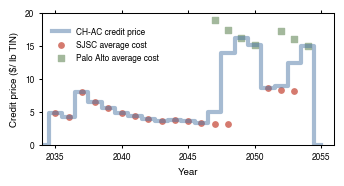

In [47]:
fig, axs = plt.subplots(1, 1, figsize=(90/25.4, 50/25.4))    
markers = {'SJSC':'o', 'Sunnyvale':'^', 'Palo Alto':'s'}
df = clearinghouse_market    
WWTP_CH = ['SJSC', 'Sunnyvale', 'Palo Alto']

#axs.bar(df.Year, df.Clearinghouse_price_avg, label='Average clearinghouse price', alpha = 0.3, color = '#4E79A7')
axs.step(df.Year, df.Clearinghouse_price_avg, label='CH-AC credit price', alpha = 0.5, color = '#4E79A7', linewidth=3, linestyle='-', where='mid')
for i, WWTP in enumerate(WWTP_CH):
    #axs.bar(df.Year, df[f'{WWTP}_avoided_cost'], label=f'{WWTP} avoided cost', alpha=0.5)
    #ignore zero values
    if df[df[f'{WWTP}_clearinghouse_price']>0][f'{WWTP}_clearinghouse_price'].empty:
        continue
    axs.scatter(df[df[f'{WWTP}_clearinghouse_price']>0].Year, df[df[f'{WWTP}_clearinghouse_price']>0][f'{WWTP}_clearinghouse_price'], label=f'{WWTP} average cost', color = colors_WWTP[WWTP], marker = markers[WWTP], s=15)
#axs.plot(df.Year, df.Clearinghouse_price_avg, label='Average clearinghouse price', linestyle = '--', alpha = 0.5)


    
axs.legend(loc='upper left', frameon=False, prop={'family':'Helvetica', 'size':lab_size}, bbox_to_anchor=(0.01, 0.95))
axs.set_ylabel('Credit price ($/ lb TIN)', **hfont)

axs.tick_params(axis='both', which='major', labelsize=leg_size, labelfontfamily= 'Helvetica')

axs.set_xlim(years[9],years[30]+1)
axs.set_xticks(np.arange(years[10], years[30]+1, 5))
axs.set_xticklabels(np.arange(years[10], years[30]+1, 5), **hfont_ticks)

axs.set_ylim(0, 20)
axs.set_yticks(np.arange(0, 21, 5))
axs.set_yticklabels([int(y) for y in np.arange(0, 21, 5)], **hfont_ticks)
axs.set_xlabel('Year', **hfont)

axs.xaxis.set_ticks_position('both')
axs.tick_params(axis="both", width=line_wid, length=bord_wid, labelsize=lab_size)
for spine in axs.spines.values():
    spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)

fig.tight_layout()    
plt.savefig(file + '/Fig3ai.svg', format='svg', dpi=300)    


Bid in year = 2049
 Sunnyvale's bid in 2049: 4.64
 SJSC's bid in 2049: 109.54


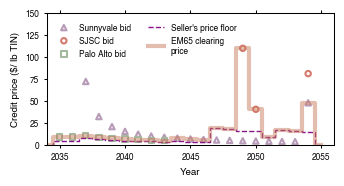

In [48]:
# create plot with three subfigures for each WWTP

ciel = -(len(WWTPs)//-2)-1
fig, axs = plt.subplots(1, 1, figsize=(90/25.4, 50/25.4))    
#markers = {'SJSC':'*', 'Sunnyvale':'^', 'Palo Alto':'D'}
markers = {'SJSC':'o', 'Sunnyvale':'^', 'Palo Alto':'s'}
markers_size = {'SJSC':15, 'Sunnyvale':15, 'Palo Alto':15}
per_savings = 65
percent_savings_w = {'Palo Alto': 0.7, 'SJSC': 0.7, 'Sunnyvale': 0.7}

exchange_market = simulate_EM_market(df = df_centralized_market, df_NC = df_NC, WWTPs=WWTPs, percent_saving= {WWTP: per_savings/100 for WWTP in WWTPs})
df = exchange_market    

#axs.bar(df.Year, df.Market_clearing_price, label='Market clearing price', alpha = 0.3, color = '#C97C5D')

for i, WWTP in enumerate(reversed(WWTPs)):
    #axs.bar(df.Year, df[f'{WWTP}_avoided_cost'], label=f'{WWTP} avoided cost', alpha=0.5)
    #ignore zero values
    bid_w = df[df[f'{WWTP}_bid']>0][f'{WWTP}_bid']
    years_bid = df[df[f'{WWTP}_bid']>0].Year
    if bid_w.empty:
        continue
    axs.scatter(years_bid, bid_w, label=f'{WWTP} bid', color = colors_WWTP[WWTP], marker = markers[WWTP], s=markers_size[WWTP], facecolors='none', edgecolors=colors_WWTP[WWTP], linewidth=1.5)

axs.step(df.Year, df.Seller_reserve, label='Seller\'s price floor', alpha = 1, color = "#89138B", linewidth=1, linestyle='--', where='mid')
axs.step(df.Year, df.Market_clearing_price, label=f'EM{per_savings} clearing\nprice', alpha = 0.5, color = '#C97C5D', linewidth=3, linestyle='-', where='mid')


axs.legend(loc='upper left', frameon=False, prop={'family':'Helvetica', 'size':lab_size}, bbox_to_anchor=(0.005, 0.98), ncol = 2)
axs.set_ylabel('Credit price ($/ lb TIN)', **hfont)

axs.tick_params(axis='both', which='major', labelsize=leg_size, labelfontfamily= 'Helvetica')

axs.set_xlim(years[9],years[30]+1)
axs.set_xticks(np.arange(years[10], years[30]+1, 5))
axs.set_xticklabels(np.arange(years[10], years[30]+1, 5), **hfont_ticks)

axs.set_ylim(0, 150)
axs.set_yticks(np.arange(0, 151, 25))
axs.set_yticklabels(np.arange(0, 151, 25), **hfont_ticks)
axs.set_xlabel('Year', **hfont)

axs.xaxis.set_ticks_position('both')
axs.tick_params(axis="both", width=line_wid, length=bord_wid, labelsize=lab_size)
for spine in axs.spines.values():
    spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)
# add a scond legenf with just the market clearing price and seller's reserve

# get layout parameters
axs.get_xaxis()


fig.tight_layout()
plt.savefig(file + '/Fig3aii.svg', format='svg', dpi=300)    

bid_year = 2049
print('Bid in year =', bid_year)
print(f' Sunnyvale\'s bid in {bid_year}:', round(exchange_market[exchange_market.Year == bid_year][f'Sunnyvale_bid'].values[0],2))
print(f' SJSC\'s bid in {bid_year}:', round(exchange_market[exchange_market.Year == bid_year][f'SJSC_bid'].values[0],2))

WWTP Palo Alto has 9 years our of 9 years where avoided cost prices are greater than clearinghouse price: [2035 2036 2037 2038 2039 2040 2041 2042 2043]
WWTP SJSC has 3 years our of 3 years where avoided cost prices are greater than clearinghouse price: [2049 2050 2054]
WWTP Sunnyvale has 15 years our of 18 years where avoided cost prices are greater than clearinghouse price: [2037 2038 2039 2040 2041 2042 2043 2044 2045 2046 2047 2048 2051 2052
 2054]


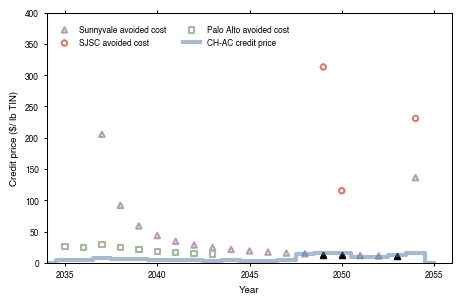

In [49]:
# create plot with three subfigures for each WWTP

ciel = -(len(WWTPs)//-2)-1
fig, axs = plt.subplots(1, 1, figsize=(120/25.4, 80/25.4))    
#markers = {'SJSC':'*', 'Sunnyvale':'^', 'Palo Alto':'D'}
markers = {'SJSC':'o', 'Sunnyvale':'^', 'Palo Alto':'s'}
markers_size = {'SJSC':15, 'Sunnyvale':15, 'Palo Alto':15}
per_savings = 0
percent_savings_w = {'Palo Alto': 0.7, 'SJSC': 0.7, 'Sunnyvale': 0.7}

#exchange_market = simulate_EM_market(df = df_centralized_market, df_NC = df_NC, WWTPs=WWTPs, percent_saving= {WWTP: per_savings/100 for WWTP in WWTPs})
#df = exchange_market    
df = clearinghouse_market
#axs.bar(df.Year, df.Market_clearing_price, label='Market clearing price', alpha = 0.3, color = '#C97C5D')

for i, WWTP in enumerate(reversed(WWTPs)):
    #axs.bar(df.Year, df[f'{WWTP}_avoided_cost'], label=f'{WWTP} avoided cost', alpha=0.5)
    #ignore zero values
    bid_w = df[df[f'{WWTP}_unit_cost_avoided']>0][f'{WWTP}_unit_cost_avoided']
    years_bid = df[df[f'{WWTP}_unit_cost_avoided']>0].Year
    avg_cost = df[df[f'{WWTP}_unit_cost_avoided']>0][f'Clearinghouse_price_avg']
    if bid_w.empty:
        continue
    bid_w_greater_than_clearinghouse = bid_w[bid_w >= avg_cost]
    bid_w_less_than_clearinghouse = bid_w[bid_w < avg_cost]
    
    axs.scatter(years_bid[bid_w >= avg_cost], bid_w_greater_than_clearinghouse, label=f'{WWTP} avoided cost', color = colors_WWTP[WWTP], marker = markers[WWTP], s=markers_size[WWTP], facecolors='none', edgecolors=colors_WWTP[WWTP], linewidth=1.5)
    axs.scatter(years_bid[bid_w < avg_cost], bid_w_less_than_clearinghouse, label='', color = colors_WWTP[WWTP], marker = markers[WWTP], s=markers_size[WWTP], facecolors='black', edgecolors='black', linewidth=1.5)

axs.step(df.Year, df.Clearinghouse_price_avg, label='CH-AC credit price', alpha = 0.5, color = '#4E79A7', linewidth=3, linestyle='-', where='mid')
#axs.step(df.Year, df.Seller_reserve, label='Seller\'s price floor', alpha = 1, color = "#89138B", linewidth=1, linestyle='--', where='mid')
#axs.step(df.Year, df.Market_clearing_price, label=f'EM{per_savings} clearing\nprice', alpha = 0.5, color = '#C97C5D', linewidth=3, linestyle='-', where='mid')


axs.legend(loc='upper left', frameon=False, prop={'family':'Helvetica', 'size':lab_size}, bbox_to_anchor=(0.005, 0.98), ncol = 2)
axs.set_ylabel('Credit price ($/ lb TIN)', **hfont)

axs.tick_params(axis='both', which='major', labelsize=leg_size, labelfontfamily= 'Helvetica')

axs.set_xlim(years[9],years[30]+1)
axs.set_xticks(np.arange(years[10], years[30]+1, 5))
axs.set_xticklabels(np.arange(years[10], years[30]+1, 5), **hfont_ticks)

axs.set_ylim(0, 400)
axs.set_yticks(np.arange(0, 401, 50))
axs.set_yticklabels(np.arange(0, 401, 50), **hfont_ticks)
axs.set_xlabel('Year', **hfont)

axs.xaxis.set_ticks_position('both')
axs.tick_params(axis="both", width=line_wid, length=bord_wid, labelsize=lab_size)
for spine in axs.spines.values():
    spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)
# add a scond legenf with just the market clearing price and seller's reserve

# get layout parameters
axs.get_xaxis()

for WWTP in WWTPs:
    #calculate number of years where avoided cost is greater than clearinghouse price
    #df_w = df[df[f'{WWTP}_avoided_cost'] > 0]
    df_w_clearinghouse = clearinghouse_market[clearinghouse_market[f'{WWTP}_unit_cost_avoided'] > 0]
    years_avoided_cost = df_w_clearinghouse[df_w_clearinghouse[f'{WWTP}_unit_cost_avoided'] > df_w_clearinghouse.Clearinghouse_price_avg].Year
    print(f'WWTP {WWTP} has {len(years_avoided_cost)} years our of {len(df_w_clearinghouse)} years where avoided cost prices are greater than clearinghouse price: {years_avoided_cost.values}')


fig.tight_layout()
#plt.savefig(file + '/SI/CHAC_credit_price_avoided_cost.svg', format='svg', dpi=300, bbox_inches='tight')


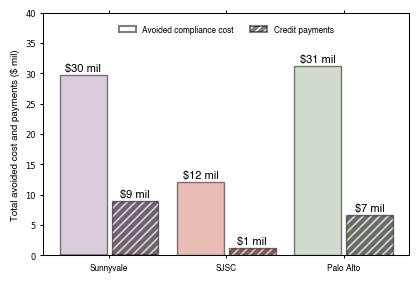

In [50]:
# create plot with three subfigures for each WWTP

ciel = -(len(WWTPs)//-2)-1
fig, axs = plt.subplots(1, 1, figsize=(120/25.4, 80/25.4))    
#markers = {'SJSC':'*', 'Sunnyvale':'^', 'Palo Alto':'D'}
markers = {'SJSC':'o', 'Sunnyvale':'^', 'Palo Alto':'s'}
markers_size = {'SJSC':15, 'Sunnyvale':15, 'Palo Alto':15}
per_savings = 0
percent_savings_w = {'Palo Alto': 0.7, 'SJSC': 0.7, 'Sunnyvale': 0.7}

#exchange_market = simulate_EM_market(df = df_centralized_market, df_NC = df_NC, WWTPs=WWTPs, percent_saving= {WWTP: per_savings/100 for WWTP in WWTPs})
#df = exchange_market    
df = clearinghouse_market
#axs.bar(df.Year, df.Market_clearing_price, label='Market clearing price', alpha = 0.3, color = '#C97C5D')

x_space= [1, 2, 3]
for i, WWTP in enumerate(reversed(WWTPs)):
    #axs.bar(df.Year, df[f'{WWTP}_avoided_cost'], label=f'{WWTP} avoided cost', alpha=0.5)
    #ignore zero values
    Total_avoided_cost = df[f'{WWTP}_avoided_cost'].sum()
    Total_credit_payments = df[f'{WWTP}_payment'].sum()
    
    # bar graph for total avoided cost and total credit payments
    if i == 0:
        label_avoided_cost = f'Avoided compliance cost'
        label_credit_payments = f'Credit payments'
        axs.bar(x_space[i]-0.22, 0, width=0.4, label=label_avoided_cost, color = 'white', alpha=0.5, linewidth=1.5, edgecolor='black')
        axs.bar(x_space[i]+0.22, 0, width=0.4, label=label_credit_payments, color = 'white', alpha=0.5, hatch='////', linewidth=1.5, edgecolor='black')
    else:
        label_avoided_cost = None
        label_credit_payments = None
    
    axs.bar(x_space[i]-0.22, Total_avoided_cost, width=0.4, label=None, color = colors_WWTP[WWTP], alpha=0.5, linewidth=1, edgecolor='black')
    axs.bar(x_space[i]+0.22, Total_credit_payments, width=0.4, label=None, color = colors_WWTP[WWTP], alpha=0.5, hatch='////', linewidth=1, edgecolor='black')
    axs.text(x_space[i]-0.22, Total_avoided_cost + 0.22, f'${round(Total_avoided_cost)} mil', ha='center', va='bottom', fontsize=lab_size+2, fontname='Helvetica')
    axs.text(x_space[i]+0.22, Total_credit_payments + 0.22, f'${round(Total_credit_payments)} mil', ha='center', va='bottom', fontsize=lab_size+2, fontname='Helvetica')
    #axs.scatter(years_bid[bid_w >= avg_cost], bid_w_greater_than_clearinghouse, label=f'{WWTP} avoided cost', color = colors_WWTP[WWTP], marker = markers[WWTP], s=markers_size[WWTP], facecolors='none', edgecolors=colors_WWTP[WWTP], linewidth=1.5)
    #axs.scatter(years_bid[bid_w < avg_cost], bid_w_less_than_clearinghouse, label='', color = colors_WWTP[WWTP], marker = markers[WWTP], s=markers_size[WWTP], facecolors='black', edgecolors='black', linewidth=1.5)

#axs.step(df.Year, df.Clearinghouse_price_avg, label='CH-AC credit price', alpha = 0.5, color = '#4E79A7', linewidth=3, linestyle='-', where='mid')
#axs.step(df.Year, df.Seller_reserve, label='Seller\'s price floor', alpha = 1, color = "#89138B", linewidth=1, linestyle='--', where='mid')
#axs.step(df.Year, df.Market_clearing_price, label=f'EM{per_savings} clearing\nprice', alpha = 0.5, color = '#C97C5D', linewidth=3, linestyle='-', where='mid')

axs.set_ylim(0, 40)

axs.set_xticks(x_space)
axs.set_xticklabels([f'{WWTP}' for WWTP in reversed(WWTPs)], **hfont)

axs.set_ylabel('Total avoided cost and payments ($ mil)', **hfont)
axs.legend(loc='upper center', frameon=False, prop={'family':'Helvetica', 'size':lab_size}, bbox_to_anchor=(0.5, 0.98), ncol = 2)

axs.xaxis.set_ticks_position('both')
axs.tick_params(axis="both", width=line_wid, length=bord_wid, labelsize=lab_size)
for spine in axs.spines.values():
    spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)
plt.savefig(file + '/SI/CHAC_credit_price_avoided_cost_2.svg', format='svg', dpi=300, bbox_inches='tight')

In [51]:
# Print bid and clearing price for each year
per_savings = 65
exchange_market = simulate_EM_market(df = df_centralized_market, df_NC = df_NC, WWTPs=WWTPs, percent_saving= {WWTP: per_savings/100 for WWTP in WWTPs})
for year in years:
    credits_sold = sum(exchange_market[exchange_market.Year == year][f'{WWTP}_units_sold'].values[0] for WWTP in WWTPs)
    if credits_sold > 0:
        print(f'Year: {year}')
    for WWTP in WWTPs:
        bid = exchange_market[exchange_market.Year == year][f'{WWTP}_bid'].values[0]
        if bid > 0:
            print(f' {WWTP} bid: {round(bid,1)}')
    clearing_price = exchange_market[exchange_market.Year == year]['Market_clearing_price'].values[0]
    seller_reserve = exchange_market[exchange_market.Year == year]['Seller_reserve'].values[0]
    if clearing_price > 0:
        print(f' Market reserve price: {round(seller_reserve,1)}')
        print(f' Market clearing price: {round(clearing_price,1)}\n')

Year: 2035
 Palo Alto bid: 9.0
 Market reserve price: 4.7
 Market clearing price: 9.0

Year: 2036
 Palo Alto bid: 8.7
 Market reserve price: 4.3
 Market clearing price: 8.7

Year: 2037
 Palo Alto bid: 10.4
 Sunnyvale bid: 71.9
 Market reserve price: 8.0
 Market clearing price: 10.4

Year: 2038
 Palo Alto bid: 8.6
 Sunnyvale bid: 32.1
 Market reserve price: 6.5
 Market clearing price: 8.6

Year: 2039
 Palo Alto bid: 7.4
 Sunnyvale bid: 20.6
 Market reserve price: 5.6
 Market clearing price: 7.4

Year: 2040
 Palo Alto bid: 6.4
 Sunnyvale bid: 15.2
 Market reserve price: 4.9
 Market clearing price: 6.4

Year: 2041
 Palo Alto bid: 5.7
 Sunnyvale bid: 12.1
 Market reserve price: 4.3
 Market clearing price: 5.7

Year: 2042
 Palo Alto bid: 5.2
 Sunnyvale bid: 10.0
 Market reserve price: 3.9
 Market clearing price: 5.2

Year: 2043
 Palo Alto bid: 4.8
 Sunnyvale bid: 8.5
 Market reserve price: 3.6
 Market clearing price: 4.8

Year: 2044
 Sunnyvale bid: 7.5
 Market reserve price: 3.8
 Market cle

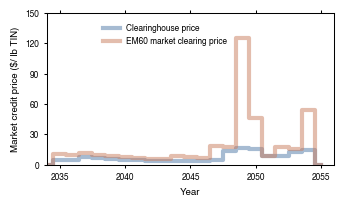

In [52]:
# create plot with three subfigures for each WWTP

ciel = -(len(WWTPs)//-2)-1
fig, axs = plt.subplots(1, 1, figsize=(90/25.4, 55/25.4))    
markers = {'SJSC':'o', 'Sunnyvale':'^', 'Palo Alto':'s'}
percent_savings_w = {'Palo Alto': 0.6, 'SJSC': 0.6, 'Sunnyvale': 0.6}

exchange_market = simulate_EM_market(df = df_centralized_market, df_NC = df_NC, WWTPs=WWTPs, percent_saving= percent_savings_w)
df_EM = exchange_market    
df_CH = clearinghouse_market    

axs.step(df_CH.Year, df_CH.Clearinghouse_price_avg, label='Clearinghouse price', alpha = 0.5, color = '#4E79A7', linewidth=3, linestyle='-', where='mid')
axs.step(df_EM.Year, df_EM.Market_clearing_price, label='EM60 market clearing price', alpha = 0.5, color = '#C97C5D', linewidth=3, linestyle='-', where='mid')


axs.legend(loc='upper left', frameon=False, prop={'family':'Helvetica', 'size':lab_size}, bbox_to_anchor=(0.17, 0.98), ncol = 1)
axs.set_ylabel('Market credit price ($/ lb TIN)', **hfont)

axs.tick_params(axis='both', which='major', labelsize=leg_size, labelfontfamily= 'Helvetica')

axs.set_xlim(years[9],years[30]+1)
axs.set_xticks(np.arange(years[10], years[30]+1, 5))
axs.set_xticklabels(np.arange(years[10], years[30]+1, 5), **hfont_ticks)

axs.set_ylim(0, 150)
axs.set_yticks(np.arange(0, 151, 30))
axs.set_yticklabels([int(y) for y in np.arange(0, 151, 30)], **hfont_ticks)
axs.set_xlabel('Year', **hfont)

axs.xaxis.set_ticks_position('both')
axs.tick_params(axis="both", width=line_wid, length=bord_wid, labelsize=lab_size)
for spine in axs.spines.values():
    spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)

# get layout parameters
axs.get_xaxis()


fig.tight_layout()
#plt.savefig(file + '/Fig3aii_comparison.svg', format='svg', dpi=300)    


WWTP Palo Alto with buyer bid average price: 12.6
WWTP SJSC with buyer bid average price: 0
WWTP Sunnyvale with buyer bid average price: 12.6
WWTP Palo Alto with seller bid average price: 18.41
WWTP SJSC with seller bid average price: 0
WWTP Sunnyvale with seller bid average price: 18.41
WWTP Palo Alto with buyer bid average price: 18.91
WWTP SJSC with buyer bid average price: 0
WWTP Sunnyvale with buyer bid average price: 18.91
WWTP Palo Alto with buyer bid average price: 15.76
WWTP SJSC with buyer bid average price: 0
WWTP Sunnyvale with buyer bid average price: 15.76
WWTP Palo Alto with buyer bid average price: 12.6
WWTP SJSC with buyer bid average price: 0
WWTP Sunnyvale with buyer bid average price: 12.6


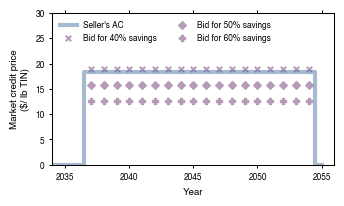

In [53]:
# create plot with three subfigures for each WWTP

ciel = -(len(WWTPs)//-2)-1
fig, axs = plt.subplots(1, 1, figsize=(90/25.4, 55/25.4))    
markers = {'SJSC':'o', 'Sunnyvale':'^', 'Palo Alto':'s'}
markers_bids = ['x', 'D', 'P']
per_sav = 0.6

bilat_trade_buyer = simulate_bilat_trade(df = df_bilat_market, df_NC = df_NC, WWTPs=WWTPs, BT_market_bid_tag= 'buyer_bid', percent_saving= {'Palo Alto': per_sav, 'SJSC': per_sav, 'Sunnyvale': per_sav})
bilat_trade_seller = simulate_bilat_trade(df = df_bilat_market, df_NC = df_NC, WWTPs=WWTPs, BT_market_bid_tag= 'seller_bid', capex_weight=1.0, opex_weight=1.0)
df = bilat_trade_buyer    

#axs.bar(df.Year, df.Market_clearing_price, label='Market clearing price', alpha = 0.3, color = '#C97C5D')
axs.step(bilat_trade_seller.Year, bilat_trade_seller.Market_clearing_price, label=f'Seller\'s AC', alpha = 0.5, color = '#4E79A7', linewidth=3, linestyle='-', where='mid')

WWTP = 'Sunnyvale'
per_savings = [0.4, 0.5, 0.6]
for i, per in enumerate(per_savings):
    df = simulate_bilat_trade(df = df_bilat_market, df_NC = df_NC, WWTPs=WWTPs, BT_market_bid_tag= 'buyer_bid', percent_saving= {'Palo Alto': per, 'SJSC': per, 'Sunnyvale': per})
    bid_w = df[df[f'{WWTP}_units_bought']>0][f'Bilat_price_{WWTP}']
    years_bid = df[df[f'{WWTP}_units_bought']>0].Year
    if bid_w.empty:
        continue
    axs.scatter(years_bid, bid_w, label=f'Bid for {int(per*100)}% savings', color = colors_WWTP[WWTP], marker = markers_bids[i], s=15)


axs.legend(loc='upper left', frameon=False, prop={'family':'Helvetica', 'size':lab_size}, ncol = 2)
axs.set_ylabel('Market credit price\n($/ lb TIN)', **hfont)

axs.tick_params(axis='both', which='major', labelsize=leg_size, labelfontfamily= 'Helvetica')

axs.set_xlim(years[9],years[30]+1)
axs.set_xticks(np.arange(years[10], years[30]+1, 5))
axs.set_xticklabels(np.arange(years[10], years[30]+1, 5), **hfont_ticks)

axs.set_ylim(0, 30)
axs.set_yticks(np.arange(0, 31, 5))
axs.set_xlabel('Year', **hfont)

axs.xaxis.set_ticks_position('both')
axs.tick_params(axis="both", width=line_wid, length=bord_wid, labelsize=lab_size)
for spine in axs.spines.values():
    spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)

# get layout parameters
axs.get_xaxis


fig.tight_layout()
#plt.savefig(file + '/Fig3_bilat.svg', format='svg', dpi=300)    


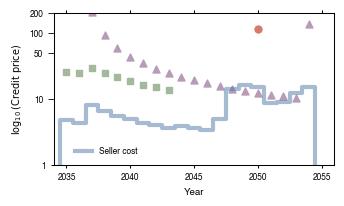

In [54]:
# create plot with three subfigures for each WWTP
from matplotlib.ticker import LogLocator, NullFormatter


ciel = -(len(WWTPs)//-2)-1
fig, axs = plt.subplots(1, 1, figsize=(90/25.4, 55/25.4))    
markers = {'SJSC':'o', 'Sunnyvale':'^', 'Palo Alto':'s'}
per = 0
percent_savings_w = {'Palo Alto': per, 'SJSC': per, 'Sunnyvale': per}

exchange_market = simulate_EM_market(df = df_centralized_market, df_NC = df_NC, WWTPs=WWTPs, percent_saving= percent_savings_w)
df_EM = exchange_market    
df_CH = clearinghouse_market    

axs.step(df_CH.Year, df_CH.Clearinghouse_price_avg, label='Seller cost', alpha = 0.5, color = '#4E79A7', linewidth=3, linestyle='-', where='mid')
#axs.step(df_EM.Year, df_EM.Market_clearing_price, label='Buyer price to save 60%', alpha = 0.5, color = '#C97C5D', linewidth=3, linestyle='-', where='mid')

#axs.bar(df_EM.Year, df_EM.Market_clearing_price, label='Market clearing price', alpha = 0.3, color = '#C97C5D')
#axs.step(df_EM.Year, df_EM.Market_clearing_price, label='Market clearing price', alpha = 0.5, color = '#C97C5D', linewidth=3, linestyle='-', where='mid')
"""
axs.step(df_EM.Year, df_EM.Market_clearing_price/df_CH.Clearinghouse_price_avg, label='Ratio of no market costs\nto average credit price', 
         alpha = 0.3, color = '#C97C5D', linewidth=3, linestyle='-', where='mid')
"""
for i, WWTP in enumerate(reversed(WWTPs)):
    #axs.bar(df_EM.Year, df_EM[f'{WWTP}_avoided_cost'], label=f'{WWTP} avoided cost', alpha=0.5)
    #ignore zero values
    bid_w = df_EM[df_EM[f'{WWTP}_bid']>0][f'{WWTP}_bid']
    years_bid = df_EM[df_EM[f'{WWTP}_bid']>0].Year
    if bid_w.empty:
        continue
    axs.scatter(years_bid, bid_w, label='', color = colors_WWTP[WWTP], marker = markers[WWTP], s=25)
    #axs.step(years_bid, bid_w, label='', color = colors_WWTP[WWTP], marker = markers[WWTP], linewidth=2, linestyle='-', where='mid')
#"""

axs.legend(loc='lower left', frameon=False, prop={'family':'Helvetica', 'size':lab_size}, bbox_to_anchor=(0.05, 0.01))

axs.tick_params(axis='both', which='major', labelsize=leg_size, labelfontfamily= 'Helvetica')

axs.set_xlim(years[9],years[30]+1)
axs.set_xticks(np.arange(years[10], years[30]+1, 5))
axs.set_xticklabels(np.arange(years[10], years[30]+1, 5), **hfont_ticks)

#axs.axhline(y=1, color='gray', linestyle='--', linewidth=1)

#set log scale for y axis
#axs.set_ylim(0, 8)
#axs.set_yticks(np.arange(0, 9, 1))

axs.set_yscale('log')
axs.set_yticks([1])
axs.set_yticklabels(['1'], **hfont_ticks)
axs.set_ylim(bottom= 1, top=200)
#axs.set_yticks([0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 2, 3, 4, 5, 6, 7, 8], minor=True)
#axs.set_yticklabels(['0.3', '0.4', '0.5', '0.6', '0.7', '0.8', '0.9', '2', '3', '4', '5', '6', '7', '8'], minor=True, **hfont_ticks)
axs.set_yticks([1, 10, 50, 100, 200], minor=True)
axs.set_yticklabels(['1', '10', '50', '100', '200'], minor=True, **hfont_ticks)

axs.tick_params(axis='y', which='minor', length=4)
axs.tick_params(axis='y', which='major', length=6)

#axs.set_ylabel(r'$\log_{10}(\mathrm{Credit\ price\ ratio})$', **hfont)
#axs.set_ylabel('Log Scale', **hfont)
axs.set_ylabel(r'$\log_{10}(\mathrm{Credit\ price})$', **hfont)


axs.set_xlabel('Year', **hfont)

axs.xaxis.set_ticks_position('both')
axs.tick_params(axis="both", width=line_wid, length=bord_wid, labelsize=lab_size)
for spine in axs.spines.values():
    spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)

fig.tight_layout()
#plt.savefig(file + '/Fig3aii_log.svg', format='svg', dpi=300)    


In [55]:
exchange_market = simulate_EM_market(df = df_centralized_market, df_NC=df_NC, WWTPs=WWTPs, percent_saving= percent_savings_w)
cost_savings_ExchangeMarket = buyer_cost_savings(df_centralized_market, exchange_market, WWTPs)
total_cost_savings_ExchangeMarket = total_cost_savings_function(df_centralized_market, exchange_market, df_NC, WWTPs)
df = exchange_market

WWTP: Palo Alto (Clearinghouse)
    Total cost savings: 623.64 mil $ (76.95 % of total CoC)
    Percent of cost savings as buyer: 81.62 %
    Percent of cost savings as seller: 18.38 %
WWTP: Sunnyvale (Clearinghouse)
    Total cost savings: 1451.15 mil $ (99.38 % of total CoC)
    Percent of cost savings as buyer: 100.0 %
    Percent of cost savings as seller: 0.0 %
WWTP: Palo Alto (Exchange Market), total cumulative savings: 19.45 %
    Total cost savings: 544.33 mil $ (75.58 % of total CoC)
    Percent of cost savings as buyer: 49.74 %
    Percent of cost savings as seller: 50.26 %
WWTP: Sunnyvale (Exchange Market), total cumulative savings: 19.98 %
    Total cost savings: 966.19 mil $ (97.59 % of total CoC)
    Percent of cost savings as buyer: 100.0 %
    Percent of cost savings as seller: 0.0 %


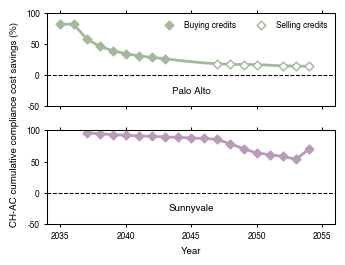

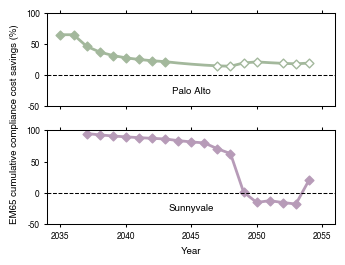

In [56]:
# create plot with three subfigures for each WWTP
red_cb   = "#CC6677"
green_cb = "#44AA99"

red_cb   = "#D55E00"   # vermillion
green_cb = "#009E73"   # bluish green
WWTPs = ['Palo Alto', 'SJSC', 'Sunnyvale']
per_savings = 0.65
df_EM = simulate_EM_market(df = df_centralized_market, df_NC = df_NC, WWTPs=WWTPs, percent_saving= {WWTP: per_savings for WWTP in WWTPs})
df_CH = simulate_CH_market(df = df_centralized_market, df_NC = df_NC, WWTPs=WWTPs, capex_weight=1.0, opex_weight=1.0)


for df in [df_EM, df_CH]:
    for WWTP in WWTPs:
        df[f'{WWTP}_total_cost_saving'] = df[f'{WWTP}_avoided_cost'] - df[f'{WWTP}_payment'] + df[f'{WWTP}_revenue']
        df[f'{WWTP}_buyer_cost_saving'] = df[f'{WWTP}_avoided_cost_buyer'] - df[f'{WWTP}_payment']
        df[f'{WWTP}_seller_cost_saving'] = df[f'{WWTP}_avoided_cost_seller'] + df[f'{WWTP}_revenue']
        # calculate sum of cost savings by adding the total cost savings from previous years at each year
        df[f'{WWTP}_total_cost_saving_cumsum'] = df[f'{WWTP}_total_cost_saving'].cumsum()
        df[f'{WWTP}_annual_CoC_NC_cumsum'] = df[f'{WWTP}_annual_CoC_NC'].cumsum()
        df[f'{WWTP}_CoC_saving_percent'] = df[f'{WWTP}_total_cost_saving_cumsum'] / df[f'{WWTP}_annual_CoC_NC_cumsum'] * 100
        
        

WWTPs_plot = ['Palo Alto', 'Sunnyvale']

ciel = -(len(WWTPs_plot)//-2)-1

for plot_tag in ['CH', 'EM']:
    fig, axs = plt.subplots(len(WWTPs_plot), 1, figsize=(90/25.4, 70/25.4), sharex=True)

    if plot_tag == 'CH':
        df = df_CH
    elif plot_tag == 'EM':
        df = df_EM
    #markers = ['o', 's', 'v', 'D', '^', 'P', '*', 'X', '<', '>']
    for i, WWTP in enumerate(WWTPs_plot):
        
        
        # lollipop plot
        market_profit_pos = df[df[f'{WWTP}_CoC_saving_percent']>0]
        market_profit_neg = df[df[f'{WWTP}_CoC_saving_percent']<0]
        df = df[df[f'{WWTP}_required_removal']>0]
        market_seller = df[df[f'{WWTP}_units_sold']>0]
        market_buyer = df[df[f'{WWTP}_units_bought']>0]
        
        #axs[i].stem(market_profit_pos.Year, market_profit_pos[f'{WWTP}_CoC_saving_percent'], linefmt=green_cb, markerfmt=green_cb, basefmt=" ", label='Market savings')
        #axs[i].stem(market_profit_neg.Year, market_profit_neg[f'{WWTP}_CoC_saving_percent'], linefmt=red_cb, markerfmt=red_cb, basefmt=" ", label='Cost increase')
        
        axs[i].scatter(market_buyer.Year, market_buyer[f'{WWTP}_CoC_saving_percent'], color = colors_WWTP[WWTP], marker = 'D', s=20, label='Buying credits', edgecolors=colors_WWTP[WWTP], linewidth=1)
        axs[i].scatter(market_seller.Year, market_seller[f'{WWTP}_CoC_saving_percent'], color = 'white', marker = 'D', s=20, label='Selling credits', edgecolors=colors_WWTP[WWTP], linewidth=1)
        axs[i].plot(df.Year, df[f'{WWTP}_CoC_saving_percent'], color = colors_WWTP[WWTP], linewidth=2, label='', zorder=0)
        
        market_sale_profit = df[f'{WWTP}_revenue'].sum()
        total_CoC = df[f'{WWTP}_market_CoC'].sum()
        total_cost_savings = df[f'{WWTP}_CoC_saving_percent'].sum()
        
        if plot_tag == 'CH':
            y_label_text = 'CH-AC cumulative compliance cost savings (%)'
            if i == 0:
                axs[i].legend(loc='upper right', frameon=False, prop={'family':'Helvetica', 'size':lab_size}, ncol=2)
            
            max_saving_CH = max(df[f'{WWTP}_CoC_saving_percent'])
            min_saving_CH = min(df[f'{WWTP}_CoC_saving_percent'])
            print(f'WWTP: {WWTP} (Clearinghouse)')
            
        elif plot_tag == 'EM':
            #y_label_text = f'Exchange market (EM{per_savings*100:.0f}) cumulative cost savings (%)'
            y_label_text = f'EM{per_savings*100:.0f} cumulative compliance cost savings (%)'
            max_saving_EM = max(df[f'{WWTP}_CoC_saving_percent'])
            min_saving_EM = min(df[f'{WWTP}_CoC_saving_percent'])
            total_savings_percent = df[f'{WWTP}_CoC_saving_percent'].iloc[-1]
            print(f'WWTP: {WWTP} (Exchange Market), total cumulative savings: {total_savings_percent:.2f} %')
        
        
        percent_saving = round(total_cost_savings/(total_CoC + total_cost_savings)*100)
        print(f'    Total cost savings: {round(total_cost_savings,2)} mil $ ({round(total_cost_savings/(total_CoC + total_cost_savings)*100,2)} % of total CoC)')
        print(f'    Percent of cost savings as buyer: {round(df[f"{WWTP}_buyer_cost_saving"].sum()/df[f"{WWTP}_total_cost_saving"].sum()*100,2)} %')
        print(f'    Percent of cost savings as seller: {round(df[f"{WWTP}_seller_cost_saving"].sum()/df[f"{WWTP}_total_cost_saving"].sum()*100,2)} %')
        
        
        axs[i].axhline(0, label='', color='black', linewidth=line_wid, linestyle='--')
        
        
        
        ylims_WWTPs = {'Palo Alto': 100, 'Sunnyvale': 100, 'SJSC': 150}

        axs[i].set_ylim(-50, ylims_WWTPs[WWTP])
        axs[i].set_yticks(np.arange(-50, ylims_WWTPs[WWTP]+1, 50))
        axs[i].set_yticklabels(np.arange(-50, ylims_WWTPs[WWTP]+1, 50), **hfont_ticks)
        
        axs[i].set_xlim(years[9],years[30]+1)
        axs[i].set_xticks(np.arange(years[10], years[30]+1, 5))
        axs[i].set_xticklabels(np.arange(years[10], years[30]+1, 5), **hfont_ticks)
        
        
        
        text_header =  WWTP 
        axs[i].text(years[20], -25, text_header, **hfont, ha = 'center', va = 'center')
        #axs[i].text(years[10], -25, text_header, **hfont, ha = 'left', va = 'center')

        
        if i ==len(WWTPs_plot)-1:
            axs[i].set_xlabel('Year', **hfont)
        else:
            axs[i].set_xticklabels([])
        
        axs[i].tick_params(axis='both', which='major', labelsize=leg_size, labelfontfamily= 'Helvetica')
        axs[i].xaxis.set_ticks_position('both')
        axs[i].tick_params(axis="both", width=line_wid, length=bord_wid, labelsize=lab_size)
        for spine in axs[i].spines.values():
            spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)

    # add common ylabl
    fig.supylabel('', **hfont)
    fig.tight_layout()    
    fig.supylabel(y_label_text, **hfont, x=0.04, y = 0.53)
    plt.savefig(file + f'/Fig3_{plot_tag}.svg', format='svg', dpi=300)



## Cost Saving Figures

In [57]:
percent_savings_w = {'Palo Alto': 0.6, 'SJSC': 0.6, 'Sunnyvale': 0.6}
exchange_market = simulate_EM_market(df = df_centralized_market, df_NC=df_NC, WWTPs=WWTPs, percent_saving= percent_savings_w)
CH_market = simulate_CH_market(df = df_centralized_market, df_NC=df_NC, WWTPs=WWTPs, capex_weight=1.0, opex_weight=1.0)
cost_savings_ExchangeMarket = buyer_cost_savings(df_centralized_market, exchange_market, WWTPs)
cost_savings_Clearinghouse = buyer_cost_savings(df_centralized_market, CH_market, WWTPs)
total_cost_savings_ExchangeMarket = total_cost_savings_function(df_centralized_market, exchange_market, df_NC, WWTPs)
total_cost_savings_Clearinghouse = total_cost_savings_function(df_centralized_market, CH_market, df_NC, WWTPs)

WWTP SJSC with seller bid average price: 0
WWTP Sunnyvale with seller bid average price: 18.41
WWTP Palo Alto with seller bid average price: 18.41
Contract for 50% saving
WWTP SJSC with buyer bid average price: 0
WWTP Sunnyvale with buyer bid average price: 15.76
WWTP Palo Alto with buyer bid average price: 15.76
Contract for 18% saving
WWTP SJSC with buyer bid average price: 0
WWTP Sunnyvale with buyer bid average price: 25.84
WWTP Palo Alto with buyer bid average price: 25.84


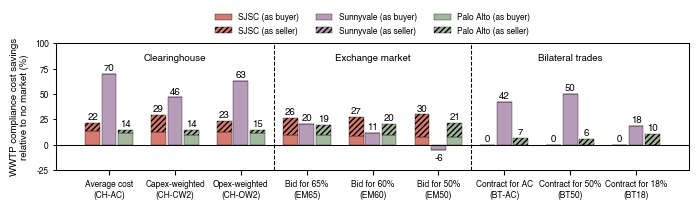

In [58]:
from collections import OrderedDict

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib as mpl


WWTPs = ['SJSC', 'Sunnyvale', 'Palo Alto']
colors_WWTP = {'Sunnyvale': '#B79BB8', 'SJSC': '#D57A6E', 'Palo Alto': '#A3B89C'}


y_base = 1
ciel = -(len(WWTPs)//-2)-1

total_cost_savings = {}
total_cost_savings_buyer = {}
total_cost_savings_seller = {}

CH_market = simulate_CH_market(df = df_centralized_market, df_NC=df_NC, WWTPs=WWTPs, capex_weight = 1.0, opex_weight = 1.0)
cs_CH = total_cost_savings_function(df_centralized_market, CH_market, df_NC, WWTPs)
per_saving_CH_buyer, per_saving_CH_seller = cost_savings_market(CH_market, df_NC, WWTPs)
total_cost_savings['Average cost\n(CH-AC)'] = cs_CH
total_cost_savings_buyer['Average cost\n(CH-AC)'] = per_saving_CH_buyer
total_cost_savings_seller['Average cost\n(CH-AC)'] = per_saving_CH_seller
#total_cost_savings['AC'] = cs_CH

CH_market = simulate_CH_market(df = df_centralized_market, df_NC=df_NC, WWTPs=WWTPs, capex_weight = 2.0, opex_weight = 1.0)
cs_CH = total_cost_savings_function(df_centralized_market, CH_market, df_NC, WWTPs)
per_saving_CH_buyer, per_saving_CH_seller = cost_savings_market(CH_market, df_NC, WWTPs)
total_cost_savings['Capex-weighted\n(CH-CW2)'] = cs_CH
total_cost_savings_buyer['Capex-weighted\n(CH-CW2)'] = per_saving_CH_buyer
total_cost_savings_seller['Capex-weighted\n(CH-CW2)'] = per_saving_CH_seller
#total_cost_savings['CW2'] = cs_CH

CH_market = simulate_CH_market(df = df_centralized_market, df_NC=df_NC, WWTPs=WWTPs, capex_weight = 1.0, opex_weight = 2.0)
cs_CH = total_cost_savings_function(df_centralized_market, CH_market, df_NC, WWTPs)
per_saving_CH_buyer, per_saving_CH_seller = cost_savings_market(CH_market, df_NC, WWTPs)
total_cost_savings['Opex-weighted\n(CH-OW2)'] = cs_CH
total_cost_savings_buyer['Opex-weighted\n(CH-OW2)'] = per_saving_CH_buyer
total_cost_savings_seller['Opex-weighted\n(CH-OW2)'] = per_saving_CH_seller
#total_cost_savings['OW2'] = cs_CH


percent_savings = [0.65, 0.6, 0.5]

for per in percent_savings:
    per_tag = str(round(per*100))
    exchange_market = simulate_EM_market(df = df_centralized_market, df_NC=df_NC, WWTPs=WWTPs, percent_saving= {w:per for w in WWTPs})
    cs_EM = total_cost_savings_function(df_centralized_market, exchange_market, df_NC, WWTPs)
    per_saving_EM_buyer, per_saving_EM_seller = cost_savings_market(exchange_market, df_NC, WWTPs)
    total_cost_savings[f'Bid for {per_tag}%\n(EM{per_tag})'] = cs_EM
    total_cost_savings_buyer[f'Bid for {per_tag}%\n(EM{per_tag})'] = per_saving_EM_buyer
    total_cost_savings_seller[f'Bid for {per_tag}%\n(EM{per_tag})'] = per_saving_EM_seller  
    #total_cost_savings[f'EM{per_tag}'] = cs_EM

bilat_trade_seller = simulate_bilat_trade(df = df_bilat_market, df_NC = df_NC, WWTPs=WWTPs, BT_market_bid_tag= 'seller_bid', capex_weight=1.0, opex_weight=1.0)
cs_EM = total_cost_savings_function(df_bilat_market, bilat_trade_seller, df_NC, WWTPs)
per_saving_bilat_buyer, per_saving_bilat_seller = cost_savings_market(bilat_trade_seller, df_NC, WWTPs)
total_cost_savings_buyer[f'Contract for AC\n(BT-AC)'] = per_saving_bilat_buyer
total_cost_savings_seller[f'Contract for AC\n(BT-AC)'] = per_saving_bilat_seller
total_cost_savings[f'Contract for AC\n(BT-AC)'] = cs_EM


percent_savings = [0.5, 0.18]
for per in percent_savings:
    per_tag = str(round(per*100))
    print('Contract for ' + per_tag + '% saving')
    bilat_trade_buyer = simulate_bilat_trade(df = df_bilat_market, df_NC = df_NC, WWTPs=WWTPs, BT_market_bid_tag= 'buyer_bid', percent_saving= {'Palo Alto': per, 'SJSC': per, 'Sunnyvale': per})
    cs_bilat = total_cost_savings_function(df_bilat_market, bilat_trade_buyer, df_NC, WWTPs)
    per_saving_bilat_buyer, per_saving_bilat_seller = cost_savings_market(bilat_trade_buyer, df_NC, WWTPs)
    total_cost_savings_buyer[f'Contract for {per_tag}%\n(BT{per_tag})'] = per_saving_bilat_buyer
    total_cost_savings_seller[f'Contract for {per_tag}%\n(BT{per_tag})'] = per_saving_bilat_seller
    total_cost_savings[f'Contract for {per_tag}%\n(BT{per_tag})'] = cs_bilat
    #total_cost_savings[f'BT{per_tag}'] = cs_EM


fig, axs = plt.subplots(1, 1, figsize=(180/25.4, 60/25.4))  
mpl.rcParams['hatch.linewidth'] = 1

label_x_2 = total_cost_savings_buyer.keys()
label_x_pos = np.linspace(0, len(label_x_2)-1, len(label_x_2))

ind_x_shift = [-0.25, 0, 0.25]

for i,WWTP in enumerate(WWTPs):

    axs.bar(
        label_x_pos + ind_x_shift[i],
        [total_cost_savings_buyer[market][WWTP] for market in label_x_2],
        color=colors_WWTP[WWTP],
        label=WWTP + ' (as buyer)',
        width=0.225,
        hatch= '',
        edgecolor='black',
        linewidth = 0.25
    )

    axs.bar(
        label_x_pos + ind_x_shift[i],
        [total_cost_savings_seller[market][WWTP] for market in label_x_2],
        color=colors_WWTP[WWTP],
        width=0.225,
        label=WWTP + ' (as seller)',
        hatch = '//////',
        bottom=[total_cost_savings_buyer[market][WWTP] for market in label_x_2],
        edgecolor='black',
        linewidth = 0.25
    )

    for j, market in enumerate(label_x_2):
        total_savings = total_cost_savings_buyer[market][WWTP] + total_cost_savings_seller[market][WWTP]
        
        if total_savings < 0:
            axs.text(
                label_x_pos[j] + ind_x_shift[i], total_savings - 12, f"{total_savings:.0f}",
                ha='center', va='bottom', fontsize=lab_size+1, fontname='Helvetica', color='black')
        elif total_savings > 10:
            axs.text(
                label_x_pos[j] + ind_x_shift[i], total_savings + 6, f"{total_savings:.0f}",
                ha='center', va='center', fontsize=lab_size+1, fontname='Helvetica', color='black')
        else:
            axs.text(
                label_x_pos[j] + ind_x_shift[i], total_savings + 1, f"{total_savings:.0f}",
                ha='center', va='bottom', fontsize=lab_size+ 1, fontname='Helvetica', color='black')

axs.axvline(2.5, color='black', linewidth=line_wid, linestyle='--')
axs.axvline(5.5, color='black', linewidth=line_wid, linestyle='--')
axs.set_ylim(-25, 100)
axs.set_yticks(np.arange(-25, 101, 25))
axs.set_yticklabels(np.arange(-25, 101, 25), **hfont_ticks)
axs.set_ylabel('WWTP compliance cost savings\nrelative to no market (%)', **hfont)

markets = ['Clearinghouse', 'Exchange market', 'Bilateral trades']
xpos = [1, 4.0, 7.0]

for i, market in enumerate(markets):
    axs.text(xpos[i], 90, market, ha='center', va='top', color='black', fontweight='bold', fontsize=fontsize_lab + 1, fontname='Helvetica')

axs.set_xticks(label_x_pos, label_x_2, **hfont_ticks)

axs.axhline(0, color='black', linewidth=line_wid, linestyle='-')
#axs.legend(loc='center', frameon=False, prop={'family':'Helvetica', 'size':lab_size}, ncol=3, bbox_to_anchor=(0.37, 0.75))
#axs.legend(loc='upper right', frameon=False, prop={'family':'Helvetica', 'size':leg_size}, bbox_to_anchor=(0.73, 0.85))

#axs.legend(loc='upper center', frameon=False, prop={'family':'Helvetica', 'size':leg_size}, bbox_to_anchor=(0.5, 1.17), ncol = 6)
handles, labels = axs.get_legend_handles_labels()
uniq = OrderedDict((l, h) for h, l in zip(handles, labels) if l != "_nolegend_")
order = ['SJSC (as buyer)', 'SJSC (as seller)', 'Sunnyvale (as buyer)', 'Sunnyvale (as seller)', 'Palo Alto (as buyer)', 'Palo Alto (as seller)']

axs.legend([uniq[l] for l in order], order, loc='upper center', frameon=False, prop={'family':'Helvetica', 'size':leg_size}, bbox_to_anchor=(0.5, 1.3), ncol = 3)

axs.xaxis.set_ticks_position('bottom')
axs.tick_params(axis="y", width=line_wid, length=bord_wid, labelsize=leg_size)
for spine in axs.spines.values():
    spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)


plt.tight_layout()
plt.savefig(file + '/Fig3e.svg', format='svg', dpi=300, bbox_inches='tight')


In [59]:
# print percent savings for buyers and sellers and total for each market
for market in total_cost_savings.keys():
    print(f'Market: {market}')
    print(f'    Total cost savings: {total_cost_savings[market]} mil $')
    print(f'    Percent of cost savings as buyer: {total_cost_savings_buyer[market]} %')
    print(f'    Percent of cost savings as seller: {total_cost_savings_seller[market]} %')

Market: Average cost
(CH-AC)
    Total cost savings: {'SJSC': 21.74269713224777, 'Sunnyvale': 69.8625442514206, 'Palo Alto': 14.461088448534282} mil $
    Percent of cost savings as buyer: {'SJSC': np.float64(12.940062386663579), 'Sunnyvale': np.float64(69.86254425142059), 'Palo Alto': np.float64(11.803085435166278)} %
    Percent of cost savings as seller: {'SJSC': np.float64(8.802634745584198), 'Sunnyvale': np.float64(0.0), 'Palo Alto': np.float64(2.658003011432325)} %
Market: Capex-weighted
(CH-CW2)
    Total cost savings: {'SJSC': 29.072788175319236, 'Sunnyvale': 46.43137208720453, 'Palo Alto': 14.442882933577044} mil $
    Percent of cost savings as buyer: {'SJSC': np.float64(11.922846511548354), 'Sunnyvale': np.float64(46.43137208720452), 'Palo Alto': np.float64(9.281273247955417)} %
    Percent of cost savings as seller: {'SJSC': np.float64(17.14994166377089), 'Sunnyvale': np.float64(0.0), 'Palo Alto': np.float64(5.161609683688397)} %
Market: Opex-weighted
(CH-OW2)
    Total cos

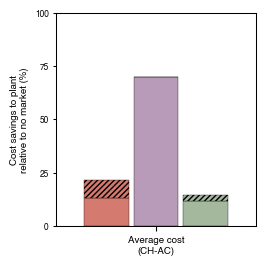

In [60]:
from collections import OrderedDict

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib as mpl


WWTPs = ['SJSC', 'Sunnyvale', 'Palo Alto']
colors_WWTP = {'Sunnyvale': '#B79BB8', 'SJSC': '#D57A6E', 'Palo Alto': '#A3B89C'}

label_x_pos = np.array([1])


y_base = 1
ciel = -(len(WWTPs)//-2)-1

total_cost_savings = {}
total_cost_savings_buyer = {}
total_cost_savings_seller = {}

CH_market = simulate_CH_market(df = df_centralized_market, df_NC=df_NC, WWTPs=WWTPs, capex_weight = 1.0, opex_weight = 1.0)
cs_CH = total_cost_savings_function(df_centralized_market, CH_market, df_NC, WWTPs)
per_saving_CH_buyer, per_saving_CH_seller = cost_savings_market(CH_market, df_NC, WWTPs)
total_cost_savings['Average cost\n(CH-AC)'] = cs_CH
total_cost_savings_buyer['Average cost\n(CH-AC)'] = per_saving_CH_buyer
total_cost_savings_seller['Average cost\n(CH-AC)'] = per_saving_CH_seller
#total_cost_savings['AC'] = cs_CH

fig, axs = plt.subplots(1, 1, figsize=(70/25.4, 70/25.4))  
mpl.rcParams['hatch.linewidth'] = 1

label_x_2 = total_cost_savings_buyer.keys()
label_x_pos = np.linspace(0, len(label_x_2)-1, len(label_x_2))
label_x_pos = np.array([1])

ind_x_shift = [-0.25, 0, 0.25]


for i,WWTP in enumerate(WWTPs):

    axs.bar(
        label_x_pos + ind_x_shift[i],
        [total_cost_savings_buyer[market][WWTP] for market in label_x_2],
        color=colors_WWTP[WWTP],
        label=WWTP + ' (as buyer)',
        width=0.225,
        hatch= '',
        edgecolor='black',
        linewidth = 0.25
    )

    axs.bar(
        label_x_pos + ind_x_shift[i],
        [total_cost_savings_seller[market][WWTP] for market in label_x_2],
        color=colors_WWTP[WWTP],
        width=0.225,
        label=WWTP + ' (as seller)',
        hatch = '//////',
        bottom=[total_cost_savings_buyer[market][WWTP] for market in label_x_2],
        edgecolor='black',
        linewidth = 0.25
    )

axs.set_ylim(0, 100)
axs.set_yticks(np.arange(0, 101, 25))
axs.set_yticklabels(np.arange(0, 101, 25), **hfont)
axs.set_ylabel('Cost savings to plant\nrelative to no market (%)', **hfont)


axs.set_xticks(label_x_pos, label_x_2, **hfont)

axs.axhline(0, color='black', linewidth=line_wid, linestyle='-')
#axs.legend(loc='center', frameon=False, prop={'family':'Helvetica', 'size':lab_size}, ncol=3, bbox_to_anchor=(0.37, 0.75))
#axs.legend(loc='upper right', frameon=False, prop={'family':'Helvetica', 'size':leg_size}, bbox_to_anchor=(0.73, 0.85))

#axs.legend(loc='upper center', frameon=False, prop={'family':'Helvetica', 'size':leg_size}, bbox_to_anchor=(0.5, 1.17), ncol = 6)
handles, labels = axs.get_legend_handles_labels()
uniq = OrderedDict((l, h) for h, l in zip(handles, labels) if l != "_nolegend_")
order = ['SJSC (as buyer)', 'SJSC (as seller)', 'Sunnyvale (as buyer)', 'Sunnyvale (as seller)', 'Palo Alto (as buyer)', 'Palo Alto (as seller)']

#axs.legend([uniq[l] for l in order], order, loc='upper center', frameon=False, prop={'family':'Helvetica', 'size':leg_size+1}, bbox_to_anchor=(0.5, 1.3), ncol = 3)
axs.set_xlim(0.5, 1.5)

axs.xaxis.set_ticks_position('bottom')
axs.tick_params(axis="y", width=line_wid, length=bord_wid, labelsize=leg_size)
for spine in axs.spines.values():
    spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)


plt.tight_layout()
plt.savefig(file + '/cost_savings.svg', format='svg', dpi=300)


## Variation in ratepayer bills

In [61]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


def calculate_cost_savings_markets(df_centralized_market, df_NC, df_bilat_market, show_plot=False, EM_run = 'short'):

    total_cost_savings = {}
    total_cost_savings_buyer = {}
    total_cost_savings_seller = {}
    dfs_markets = {}

    CH_market = simulate_CH_market(df = df_centralized_market, df_NC=df_NC, WWTPs=WWTPs, capex_weight = 1.0, opex_weight = 1.0)
    cs_CH = total_cost_savings_function(df_centralized_market, CH_market, df_NC, WWTPs)
    per_saving_CH_buyer, per_saving_CH_seller = cost_savings_market(CH_market, df_NC, WWTPs)
    total_cost_savings['CH-AC'] = cs_CH
    total_cost_savings_buyer['CH-AC'] = per_saving_CH_buyer
    total_cost_savings_seller['CH-AC'] = per_saving_CH_seller
    dfs_markets['CH-AC'] = CH_market

    
    weights = np.arange(1.5, 5.1, 0.5)

    for i,capex_w in enumerate(weights):
        for i,opex_w in enumerate(weights):
            if opex_w == 1:
                CH_tag = f'CH-CW{str(round(capex_w,2))}'
            elif capex_w == 1:
                CH_tag = f'CH-OW{str(round(opex_w,2))}'
            else:
                CH_tag = f'CH-CW{str(round(capex_w,2))}OW{str(round(opex_w,2))}'
            CH_market = simulate_CH_market(df = df_centralized_market, df_NC=df_NC, WWTPs=WWTPs, capex_weight = capex_w, opex_weight = opex_w)
            cs_CH = total_cost_savings_function(df_centralized_market, CH_market,df_NC, WWTPs)
            per_saving_CH_buyer, per_saving_CH_seller = cost_savings_market(CH_market, df_NC, WWTPs)
            total_cost_savings[CH_tag] = cs_CH
            total_cost_savings_buyer[CH_tag] = per_saving_CH_buyer
            total_cost_savings_seller[CH_tag] = per_saving_CH_seller
            dfs_markets[CH_tag] = CH_market



    if EM_run == 'short':
        percent_savings = np.arange(0.7, 0.49, -0.05)
    elif EM_run == 'long':
        percent_savings = np.arange(0.7, 0.09, -0.05)

    for i, SJSCper1 in enumerate(percent_savings):
        for j, SVper2 in enumerate(percent_savings):
            for k, PAper3 in enumerate(percent_savings):
                per_tag = f'SJ{str(round(SJSCper1*100))}SV{str(round(SVper2*100))}PA{str(round(PAper3*100))}'
                if SJSCper1 == SVper2 == PAper3:
                    per_tag = str(round(SJSCper1*100))
                exchange_market = simulate_EM_market(df = df_centralized_market, df_NC=df_NC, WWTPs=WWTPs, percent_saving= {'SJSC': SJSCper1, 'Sunnyvale': SVper2, 'Palo Alto': PAper3})
                cs_EM = total_cost_savings_function(df_centralized_market, exchange_market, df_NC, WWTPs)
                per_saving_EM_buyer, per_saving_EM_seller = cost_savings_market(exchange_market, df_NC, WWTPs)
                total_cost_savings[f'EM{per_tag}'] = cs_EM
                total_cost_savings_buyer[f'EM{per_tag}'] = per_saving_EM_buyer
                total_cost_savings_seller[f'EM{per_tag}'] = per_saving_EM_seller
                dfs_markets[f'EM{per_tag}'] = exchange_market

    
    percent_savings_bilat = np.arange(0.5, 0.09, -0.01)
    for i, per in enumerate(percent_savings_bilat):
        per_tag = str(round(per*100))
        bilat_trade_buyer = simulate_bilat_trade(df = df_bilat_market, df_NC = df_NC, WWTPs=WWTPs, BT_market_bid_tag= 'buyer_bid', percent_saving= {'Palo Alto': per, 'SJSC': per, 'Sunnyvale': per})
        cs_bilat = total_cost_savings_function(df_bilat_market, bilat_trade_buyer, df_NC, WWTPs)
        per_saving_bilat_buyer, per_saving_bilat_seller = cost_savings_market(bilat_trade_buyer, df_NC, WWTPs)
        total_cost_savings[f'BT{per_tag}'] = cs_bilat
        total_cost_savings_buyer[f'BT{per_tag}'] = per_saving_bilat_buyer
        total_cost_savings_seller[f'BT{per_tag}'] = per_saving_bilat_seller
        dfs_markets[f'BT{per_tag}'] = bilat_trade_buyer
    
    if show_plot:
        fig, axs = plt.subplots(1, 1, figsize=(230/25.4, 50/25.4))  
        markers = {'SJSC': 'o', 'Sunnyvale': '^', 'Palo Alto': 's'}

        label_x_2 = total_cost_savings.keys()
        label_x_pos = np.linspace(0, len(label_x_2) - 1, len(label_x_2))
        ind_x_shift = [-0.05, 0, 0.05]

        #add vertical line to show spread
        # find minimum value for each total_cost_savings index
        min_value = {}
        max_value = {}
        spread = {}
        for i,key in enumerate(total_cost_savings.keys()):
            min_value[key] = min([total_cost_savings[key][WWTP] for WWTP in WWTPs])
            max_value[key] = max([total_cost_savings[key][WWTP] for WWTP in WWTPs])
            axs.vlines(x=label_x_pos[i], ymin=min_value[key], ymax=max_value[key], color='black', linestyle='-', linewidth=1, alpha=0.5)
            spread[key] = max_value[key] - min_value[key]

        for i,WWTP in enumerate(WWTPs):

            axs.scatter(
                #label_x_pos + ind_x_shift[i],
                label_x_pos,
                [total_cost_savings[market][WWTP] for market in label_x_2],
                color=colors_WWTP[WWTP],
                marker=markers[WWTP],
                label=WWTP,
                alpha = 0.7,
                zorder = 3
            )

        pos_CH = len(weights)*2 + 0.5
        pos_EM = pos_CH + len(percent_savings)
        axs.axvline(pos_CH, color='black', linewidth=line_wid, linestyle='--')
        axs.axvline(pos_EM, color='black', linewidth=line_wid, linestyle='--')
        axs.set_xlim(-0.5, len(label_x_2) - 0.5)

        axs.set_ylim(0, 100)
        axs.set_yticks(np.arange(0, 101, 25))
        axs.set_yticklabels(np.arange(0, 101, 25), **hfont_ticks)
        axs.set_ylabel('Cost savings to plant\nrelative to no market (%)', **hfont)

        markets = ['Clearinghouse', 'Exchange Market', 'Bilateral Contract']
        xpos = [pos_CH / 2, (pos_EM + pos_CH)/2, (len(label_x_2) + pos_EM) / 2]

        for i, market in enumerate(markets):
            axs.text(xpos[i], 95, market, ha='center', va='top', color='black', fontweight='bold', fontsize=fontsize_lab + 1, fontname='Helvetica')


        axs.set_xticks(label_x_pos, label_x_2, **hfont_ticks)

        axs.axhline(0, color='black', linewidth=line_wid, linestyle='-')
        #axs.legend(loc='center', frameon=False, prop={'family':'Helvetica', 'size':lab_size}, ncol=1, bbox_to_anchor=(0.71, 0.7))
        axs.legend(loc='center', frameon=False, prop={'family':'Helvetica', 'size':lab_size}, ncol=1, bbox_to_anchor=(0.95, 0.62))
        #axs.legend(loc='upper right', frameon=False, prop={'family':'Helvetica', 'size':leg_size})

        axs.xaxis.set_ticks_position('bottom')
        axs.tick_params(axis="y", width=line_wid, length=bord_wid, labelsize=leg_size)
        for spine in axs.spines.values():
            spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)

        plt.tight_layout()
        #plt.savefig(file + '/Fig4b.svg', format='svg', dpi=300)
    return dfs_markets, total_cost_savings


In [62]:
path_bilat = 'Results/Sensitivity_maxCredit_bilat_contract_30yrs_TR_'
path_centralized = 'Results/Sensitivity_maxCredit_centralized_market_TR_'

WWTPs = ['Palo Alto', 'SJSC', 'Sunnyvale']
TR_HP_tuples = [(1.0, 300), (2.0, 300), (1.0, 0.25)]
#TR_HP_tuples = [(1.0, 300), (2.0, 300), (1.0, 0.25), (2.0, 0.25)]
TR_HP_tuples = [(1.0, 300)]
dfs_bilat_30yrs = {}
dfs_centralized = {}



for TR,HP in TR_HP_tuples:
    path_bilat_TR = f'{path_bilat}{TR}/Full_coordination_hotspot_0_yr_constrain_credits_bought/{HP}/'
    path_centralized_TR = f'{path_centralized}{TR}/Full_coordination_hotspot_0_yr_constrain_credits_bought/{HP}/'
    path_NC = f'{path_centralized}{TR}/No_coordination/'
    
    dfs_bilat_30yrs[(TR, HP)] = create_df_finance_econ(path_bilat_TR, WWTPs)
    dfs_centralized[(TR, HP)] = create_df_finance_econ(path_centralized_TR, WWTPs)
    df_NC = create_df_finance_econ(path_NC, WWTPs)


dfs_markets_PA, total_cost_savings_PA = calculate_cost_savings_markets(dfs_centralized[(TR, HP)], df_NC, dfs_bilat_30yrs[(TR, HP)], show_plot=False, EM_run = 'short')


WWTP Palo Alto with buyer bid average price: 15.76
WWTP SJSC with buyer bid average price: 0
WWTP Sunnyvale with buyer bid average price: 15.76
WWTP Palo Alto with buyer bid average price: 16.07
WWTP SJSC with buyer bid average price: 0
WWTP Sunnyvale with buyer bid average price: 16.07
WWTP Palo Alto with buyer bid average price: 16.39
WWTP SJSC with buyer bid average price: 0
WWTP Sunnyvale with buyer bid average price: 16.39
WWTP Palo Alto with buyer bid average price: 16.7
WWTP SJSC with buyer bid average price: 0
WWTP Sunnyvale with buyer bid average price: 16.7
WWTP Palo Alto with buyer bid average price: 17.02
WWTP SJSC with buyer bid average price: 0
WWTP Sunnyvale with buyer bid average price: 17.02
WWTP Palo Alto with buyer bid average price: 17.33
WWTP SJSC with buyer bid average price: 0
WWTP Sunnyvale with buyer bid average price: 17.33
WWTP Palo Alto with buyer bid average price: 17.65
WWTP SJSC with buyer bid average price: 0
WWTP Sunnyvale with buyer bid average price: 

In [63]:
def calculate_reserve_size(reserve_balance_tag, net_flow, market_type, CoC_avg_NC, CoC_avg_market, df_volatility, WWTP, verbose=False):
     
    balance  = np.concatenate([[0.0], np.cumsum(net_flow)])   # padded only for the cumulative sum
    real_balance = balance[1:]                                 # realized end-of-year balances
    df_volatility[reserve_balance_tag] = real_balance 
    
    # stats on the SAME array you plot (no pre-period 0, no offset)
    max_balance   = float(real_balance.max())
    min_balance   = float(real_balance.min())
    reserve_range = max_balance - min_balance
    reserve_range_months_NC = reserve_range / CoC_avg_NC * 12
    reserve_range_months_M = reserve_range / CoC_avg_market * 12

    years      = df_volatility['Year'].to_numpy()

    # binding moment = year of largest-magnitude balance (deficit or surplus), robust to cycle shape
    extreme_idx  = int(np.argmax(np.abs(real_balance)))
    extreme_year = years[extreme_idx]
    rev_at_extreme = float(df_volatility['Ratepayer_rev_collected'].to_numpy()[extreme_idx])
    expense_at_extreme = float(df_volatility[f'{WWTP}_market_CoC'].to_numpy()[extreme_idx])

    # single reserve metric
    
    reserve_months_expense = reserve_range / expense_at_extreme * 12
    reserve_months_revenue = reserve_range / rev_at_extreme * 12
    reserve_months = reserve_months_revenue

    if verbose:
        print(f"Market type {market_type} for {reserve_balance_tag}:")
        print(f"    Reserve range: {reserve_range:.2f} mil $ "
                f"({reserve_months_revenue:.1f} mo) with revenue {reserve_months_revenue:.2f} mil $/yr.  "
                f" ({reserve_months_expense:.1f} mo  for extreme year {extreme_year} with expense {expense_at_extreme:.2f} mil $/yr)."
              #f"peak +{max_balance:.2f} (yr {peak_year}), "
              #f"low {min_balance:.2f} (yr {trough_year})."
        )

    results = {
        'WWTP': WWTP, 'market_type': market_type,
        'max_balance': max_balance,               # mil $ — peak surplus (collect-ahead burden)
        'min_balance': min_balance,               # mil $ — lowest balance (deficit if negative)
        'reserve_range': reserve_range,           # mil $ — total fund size (peak-to-trough)
        'reserve_range_months_NC': reserve_range_months_NC,   # months of no-market bill
        'reserve_range_months': reserve_range_months_M,   # months of no-market bill
        'CoC_avg_NC': CoC_avg_NC,
        'CoC_avg_market': CoC_avg_market,
        'final_balance': float(balance[-1]),
        'billing_cycle': int(df_volatility['billing_cycle'].max()),
        'reserve_months': reserve_months,           # months of the high-cost bill
        'reserve_months_expense': reserve_months_expense, # months of the high-cost bill
        'reserve_monts_revenue': reserve_months_revenue, # months of the high-cost bill
        'rev_at_extreme': rev_at_extreme, # mil $/yr — bill in the most binding year
        'expense_at_extreme': expense_at_extreme, # mil $/yr — bill in the most binding year
        'extreme_year': extreme_year,           # index of the most binding year
    }

    return df_volatility, results



def calculate_ratepayer_bill_maxReserveSize(WWTP, df, df_NC, market_transactions, market_type, verbose=False):
    eps = 0.01

    
    market_transactions = market_transactions[market_transactions[f'{WWTP}_compliance_yr'] > eps].copy()

    if market_type == 'NM':
        df_w = df_NC[df_NC.WWTP == WWTP].copy()
        market_transactions[f'{WWTP}_market_CoC'] = market_transactions[f'{WWTP}_annual_CoC_NC']
        market_transactions[f'{WWTP}_total_CoC'] = market_transactions[f'{WWTP}_annual_CoC_NC']
        market_transactions[f'{WWTP}_payment'] = market_transactions[f'{WWTP}_payment']*0
        market_transactions[f'{WWTP}_revenue'] = market_transactions[f'{WWTP}_revenue']*0
        market_transactions[f'{WWTP}_units_bought'] = market_transactions[f'{WWTP}_units_bought']*0
        market_transactions[f'{WWTP}_units_sold'] = market_transactions[f'{WWTP}_units_sold']*0
        cost_savings = 0.0
    
    else:
        df_w = df[df.WWTP == WWTP].copy()

    df_NC_w = df_NC[df_NC.WWTP == WWTP].copy()
    df_w['Annual_capex'] = df_w['Annual_capex'].round(4)
    df_NC_w['Annual_capex_NC'] = df_NC_w['Annual_capex'].round(4)

    CoC_avg_NC = df_NC_w[df_NC_w['Compliance_yr'] > eps]['Annual_CoC'].mean()
    CoC_max_NC = df_NC_w[df_NC_w['Compliance_yr'] > eps]['Annual_CoC'].max()
    CoC_avg_market = market_transactions[market_transactions[f'{WWTP}_compliance_yr'] > eps][f'{WWTP}_market_CoC'].mean()

    #print(f"    {WWTP} average annual CoC (no market): {CoC_avg_NC:.2f} mil $ over {len(df_NC_w[df_NC_w['Compliance_yr'] > eps])} years")
    #print(f"    {WWTP} maximum annual CoC (no market): {CoC_max_NC:.2f} mil $ over {len(df_NC_w[df_NC_w['Compliance_yr'] > eps])} years")

    df_w = pd.merge(
        df_w, df_NC_w[['Annual_capex_NC']], left_index=True, right_index=True
    )

    df_volatility = pd.merge(
        df_w[['Year', 'Annual_capex', 'Annual_capex_NC']],
        market_transactions[[f'{WWTP}_compliance_yr', f'{WWTP}_market_CoC', f'{WWTP}_annual_CoC_NC', f'{WWTP}_total_CoC', f'{WWTP}_payment', f'{WWTP}_revenue', f'{WWTP}_units_bought', f'{WWTP}_units_sold', f'{WWTP}_opex_treated_for_trade']],
        left_index=True, right_index=True
    )

    # billing cycle increments each time capex changes from the prior year
    df_volatility['billing_cycle'] = (
        df_volatility['Annual_capex'].diff().fillna(1).abs() > 1e-9
    ).cumsum()

    

   
    # Option 5: Charge ratepayers a deterministic amount based on new capital cost, and then apply a fixed market rate for the difference
    
    #**{f'{w}_market_CoC': total_CoC[w,year] - EM_rev[w, year] + EM_payment[w, year] for w in WWTPs},
    
    # market payments as percent of total payments        

    #print(f"    {WWTP} loan payments: {df_volatility[f'{WWTP}_total_CoC'].sum():.2f} mil $, market payments: {df_volatility[f'{WWTP}_payment'].sum():.2f} mil $, market revenue: {df_volatility[f'{WWTP}_revenue'].sum():.2f} mil $")
    
    #df_volatility['status_bought_credits'] = df_volatility[f'{WWTP}_payment'].apply(lambda x: 1 if x > 0 else 0)
    average_credit_payment = df_volatility[f'{WWTP}_payment'].sum()/ df_volatility[f'{WWTP}_units_bought'].sum() if df_volatility[f'{WWTP}_units_bought'].sum() > 0 else 0
    average_credit_sold = df_volatility[f'{WWTP}_revenue'].sum()/ df_volatility[f'{WWTP}_units_sold'].sum() if df_volatility[f'{WWTP}_units_sold'].sum() > 0 else 0
    
    if average_credit_payment > 0:
        print(f"    {WWTP} average credit payment: {average_credit_payment*10**6/30:.2f} $ per unit")
    #print(f"    {WWTP} average credit sold: {average_credit_sold*10**6/30:.2f} $ per unit")


    # smooth scale of revenue over the billing cycle 
    df_volatility['billing_cycle'] = (df_volatility['Annual_capex'].diff().fillna(1).abs() > 1e-9).cumsum()
    #df_volatility['Ratepayer_rev_collected_loan'] = df_volatility.groupby('billing_cycle')[f'{WWTP}_total_CoC'].transform('mean')
    df_volatility['Ratepayer_rev_collected_loan'] = df_volatility[f'{WWTP}_total_CoC'] - df_volatility[f'{WWTP}_opex_treated_for_trade']
    
    if 'BLT' in market_type:
        # since bilateral trade is contractual over the 30-year period, the ratepayer revenue collected is based on the actual market payments and revenue
        #df_volatility['Ratepayer_rev_collected_market_revenue'] = df_volatility[f'{WWTP}_units_sold'] * average_credit_sold
        # since bilateral trade is contractual, then ratepayer revenue can be collected over 5-year cycles over the bilateral contract period
        selling_cycle_years = 5   # length of each rate period, in years
        #df_volatility['selling_cycle'] = np.arange(len(df_volatility)) // selling_cycle_years + 1
        #df_volatility['Ratepayer_rev_collected_market_revenue'] = df_volatility.groupby('selling_cycle')[f'{WWTP}_revenue'].transform('mean')
    else:
        # spread projected market revenue over the billing cycle, so that the reserve fund is not depleted in years with high market revenue
        df_volatility[f'{WWTP}_revenue_after_opex'] = df_volatility[f'{WWTP}_revenue'] - df_volatility[f'{WWTP}_opex_treated_for_trade']
        df_volatility['Ratepayer_rev_collected_market_revenue'] = 0.0

        # spread projected market revenue over 5 year cycles within the billing_cycle
        #selling_cycle_years = 5
        selling_cycle_years = False
        
        if selling_cycle_years:
            for cycle in df_volatility['billing_cycle'].unique():
                mask = df_volatility['billing_cycle'] == cycle          # rows in THIS billing cycle
                sub = df_volatility[mask]
                total_rev = sub[f'{WWTP}_revenue_after_opex'].sum()
                total_cycle_len = len(sub)

                if total_rev <= 0:
                    continue                                            # leave at 0 (no revenue to distribute)

                if total_cycle_len <= selling_cycle_years:
                    # short cycle: one flat levelized value across the whole billing cycle
                    df_volatility.loc[mask, 'Ratepayer_rev_collected_market_revenue'] = \
                        sub[f'{WWTP}_revenue_after_opex'].mean()
                else:
                    # long cycle: break into 5-year sub-cycles WITHIN this billing cycle and levelize each
                    pos = np.arange(total_cycle_len) // selling_cycle_years        # 0,0,0,0,0,1,1,... within the cycle
                    sub_levelized = (
                        sub[f'{WWTP}_revenue_after_opex']
                        .groupby(pos)                                              # group by sub-cycle position
                        .transform('mean')                                        # flat mean within each sub-cycle
                    )
                    df_volatility.loc[mask, 'Ratepayer_rev_collected_market_revenue'] = sub_levelized.to_numpy()
        else:
            # no selling cycle, just use the average revenue across the billing cycle
            df_volatility['Ratepayer_rev_collected_market_revenue'] = df_volatility.groupby('billing_cycle')[f'{WWTP}_revenue_after_opex'].transform('mean')

    for cycle in df_volatility['billing_cycle'].unique():
        total_rev = df_volatility[df_volatility['billing_cycle'] == cycle][f'{WWTP}_revenue_after_opex'].sum()
        total_market_rev = df_volatility[df_volatility['billing_cycle'] == cycle]['Ratepayer_rev_collected_market_revenue'].sum()
        if total_rev > 0:
            print(f"    {WWTP} billing cycle {cycle}: total market revenue after opex: {total_rev:.2f} mil, total market revenue collected: {total_market_rev:.2f} mil")


    #only apply average market payments over the years when credits are bought
    df_volatility['Ratepayer_rev_collected_market'] = df_volatility[f'{WWTP}_units_bought'] * average_credit_payment
    df_volatility['Ratepayer_rev_collected'] = df_volatility['Ratepayer_rev_collected_loan'] + df_volatility['Ratepayer_rev_collected_market'] - df_volatility['Ratepayer_rev_collected_market_revenue']

    
    
    #print('     Total ratepayer revenue collected: ', df_volatility['Ratepayer_rev_collected'].sum())
    #print('     Total utility payments to market: ', df_volatility[f'{WWTP}_market_CoC'].sum())


   # the reserve fund covers MARKET activity only → market-in minus market-out
    df_volatility['Net_flow_buyer'] = (
        df_volatility['Ratepayer_rev_collected_market'] - df_volatility[f'{WWTP}_payment']
    )

    df_volatility['Net_flow_seller'] = (
        #-(df_volatility['Ratepayer_rev_collected_market_revenue'] - df_volatility[f'{WWTP}_revenue'])
        -(df_volatility['Ratepayer_rev_collected_market_revenue'] - df_volatility[f'{WWTP}_revenue_after_opex'])
    )

    df_volatility['Net_flow_total'] = df_volatility['Ratepayer_rev_collected'] - df_volatility[f'{WWTP}_market_CoC']
    
    # Reserve fund to cover all market activity
    df_volatility['Net_flow'] = (
        df_volatility['Ratepayer_rev_collected_market'] - df_volatility[f'{WWTP}_payment']
        #- (df_volatility['Ratepayer_rev_collected_market_revenue'] - df_volatility[f'{WWTP}_revenue'])
        - (df_volatility['Ratepayer_rev_collected_market_revenue'] - df_volatility[f'{WWTP}_revenue_after_opex'])
    )
    # if bilateral trade, then only consider the net flow for buyer, since the credit sale will be considered part of the capital/loan payback
    if 'BT' in market_type:
        df_volatility['Net_flow'] = (
                df_volatility['Ratepayer_rev_collected_market'] - df_volatility[f'{WWTP}_payment']
                #- (df_volatility['Ratepayer_rev_collected_market_revenue'] - df_volatility[f'{WWTP}_revenue'])
            )

    # ---- reserve-fund path ----
    net_flow = df_volatility['Net_flow'].to_numpy(float)
    net_flow_buyer = df_volatility['Net_flow_buyer'].to_numpy(float)
    net_flow_seller = df_volatility['Net_flow_seller'].to_numpy(float)

    df_volatility, results =calculate_reserve_size('reserve_balance', net_flow, market_type, CoC_avg_NC, CoC_avg_market, df_volatility, WWTP, verbose)
    df_volatility, results_buyer = calculate_reserve_size('reserve_balance_buyer', net_flow_buyer, market_type, CoC_avg_NC, CoC_avg_market, df_volatility, WWTP, verbose)
    df_volatility, results_seller = calculate_reserve_size('reserve_balance_seller', net_flow_seller, market_type, CoC_avg_NC, CoC_avg_market, df_volatility, WWTP, verbose)
    


    return market_transactions, df_volatility, results, results_buyer, results_seller

Calculating maximum drawdown for market type: CH-AC
    Palo Alto
    Palo Alto average credit payment: 4.67 $ per unit
    Palo Alto billing cycle 3: total market revenue after opex: 6.06 mil, total market revenue collected: 6.06 mil
Market type CH-AC for reserve_balance:
    Reserve range: 2.24 mil $ (2.6 mo) with revenue 2.57 mil $/yr.   (2.5 mo  for extreme year 2047 with expense 10.87 mil $/yr).
Market type CH-AC for reserve_balance_buyer:
    Reserve range: 0.37 mil $ (0.5 mo) with revenue 0.47 mil $/yr.   (0.5 mo  for extreme year 2040 with expense 9.65 mil $/yr).
Market type CH-AC for reserve_balance_seller:
    Reserve range: 2.22 mil $ (2.5 mo) with revenue 2.55 mil $/yr.   (2.4 mo  for extreme year 2047 with expense 10.87 mil $/yr).
Maximum number of cycles: 3
Total CoC: 187
Total revenue: 187


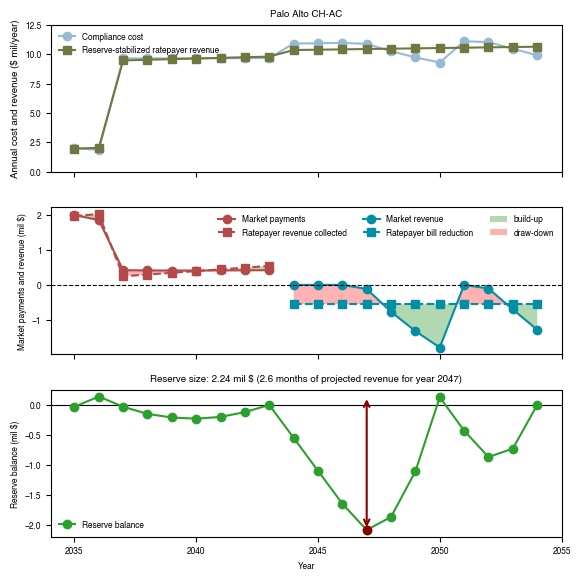

    SJSC
    SJSC average credit payment: 15.43 $ per unit
    SJSC billing cycle 1: total market revenue after opex: 6.96 mil, total market revenue collected: 6.96 mil
    SJSC billing cycle 2: total market revenue after opex: 1.47 mil, total market revenue collected: 1.47 mil
Market type CH-AC for reserve_balance:
    Reserve range: 2.44 mil $ (13.2 mo) with revenue 13.21 mil $/yr.   (13.3 mo  for extreme year 2043 with expense 2.20 mil $/yr).
Market type CH-AC for reserve_balance_buyer:
    Reserve range: 0.02 mil $ (0.1 mo) with revenue 0.07 mil $/yr.   (0.1 mo  for extreme year 2049 with expense 3.23 mil $/yr).
Market type CH-AC for reserve_balance_seller:
    Reserve range: 2.44 mil $ (13.2 mo) with revenue 13.21 mil $/yr.   (13.3 mo  for extreme year 2043 with expense 2.20 mil $/yr).
Maximum number of cycles: 2
Total CoC: 75
Total revenue: 75


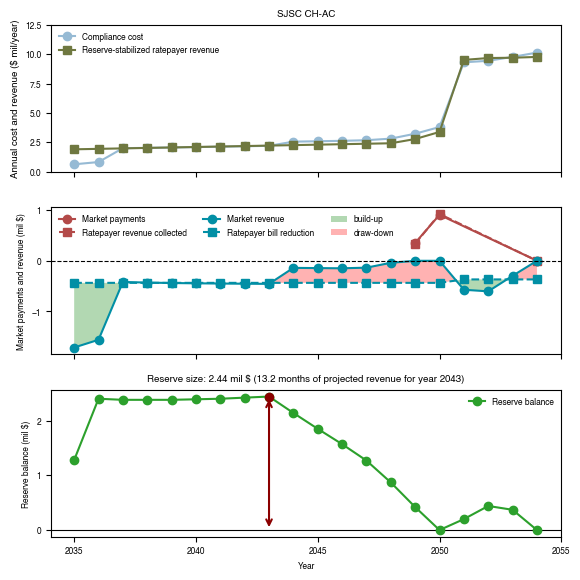

    Sunnyvale
    Sunnyvale average credit payment: 9.50 $ per unit
Market type CH-AC for reserve_balance:
    Reserve range: 1.91 mil $ (39.6 mo) with revenue 39.59 mil $/yr.   (76.3 mo  for extreme year 2047 with expense 0.30 mil $/yr).
Market type CH-AC for reserve_balance_buyer:
    Reserve range: 1.91 mil $ (39.6 mo) with revenue 39.59 mil $/yr.   (76.3 mo  for extreme year 2047 with expense 0.30 mil $/yr).
Market type CH-AC for reserve_balance_seller:
    Reserve range: 0.00 mil $ (0.0 mo) with revenue 0.00 mil $/yr.   (0.0 mo  for extreme year 2037 with expense 0.04 mil $/yr).
Maximum number of cycles: 1
Total CoC: 9
Total revenue: 9


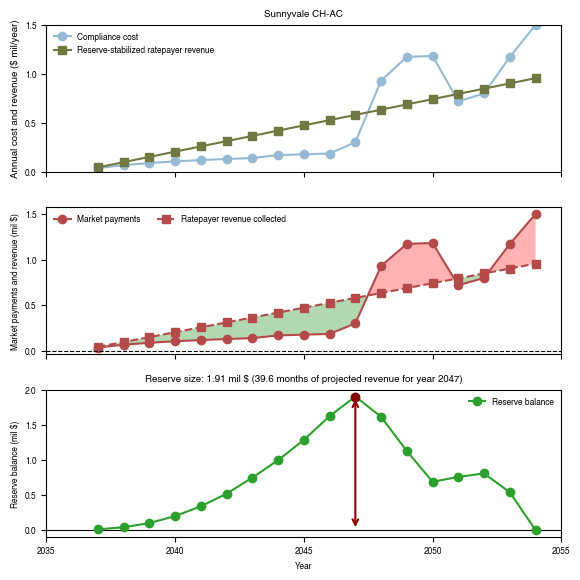

Calculating maximum drawdown for market type: EM65
    Palo Alto
    Palo Alto average credit payment: 7.89 $ per unit
    Palo Alto billing cycle 3: total market revenue after opex: 21.61 mil, total market revenue collected: 21.61 mil
Market type EM65 for reserve_balance:
    Reserve range: 11.42 mil $ (15.1 mo) with revenue 15.15 mil $/yr.   (13.4 mo  for extreme year 2048 with expense 10.25 mil $/yr).
Market type EM65 for reserve_balance_buyer:
    Reserve range: 1.00 mil $ (1.2 mo) with revenue 1.24 mil $/yr.   (1.2 mo  for extreme year 2038 with expense 9.77 mil $/yr).
Market type EM65 for reserve_balance_seller:
    Reserve range: 11.42 mil $ (15.1 mo) with revenue 15.15 mil $/yr.   (13.4 mo  for extreme year 2048 with expense 10.25 mil $/yr).
Maximum number of cycles: 3
Total CoC: 176
Total revenue: 176


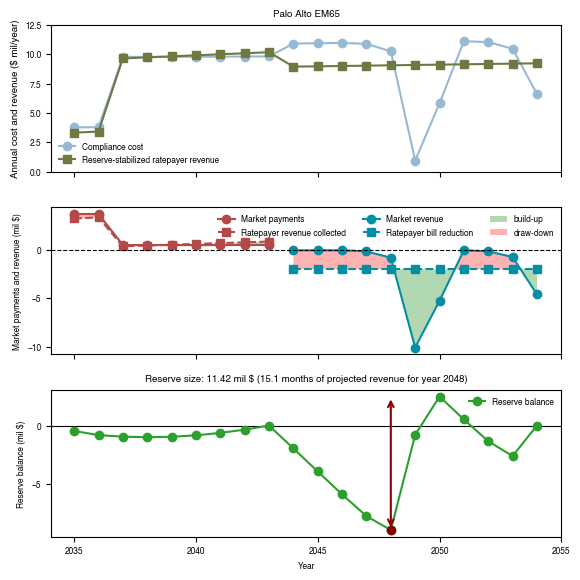

    SJSC
    SJSC average credit payment: 58.79 $ per unit
    SJSC billing cycle 1: total market revenue after opex: 13.38 mil, total market revenue collected: 13.38 mil
    SJSC billing cycle 2: total market revenue after opex: 2.56 mil, total market revenue collected: 2.56 mil
Market type EM65 for reserve_balance:
    Reserve range: 5.58 mil $ (43.5 mo) with revenue 43.51 mil $/yr.   (-60.2 mo  for extreme year 2036 with expense -1.11 mil $/yr).
Market type EM65 for reserve_balance_buyer:
    Reserve range: 1.11 mil $ (4.0 mo) with revenue 4.00 mil $/yr.   (2.5 mo  for extreme year 2049 with expense 5.26 mil $/yr).
Market type EM65 for reserve_balance_seller:
    Reserve range: 5.38 mil $ (42.0 mo) with revenue 41.95 mil $/yr.   (-58.1 mo  for extreme year 2036 with expense -1.11 mil $/yr).
Maximum number of cycles: 2
Total CoC: 71
Total revenue: 71


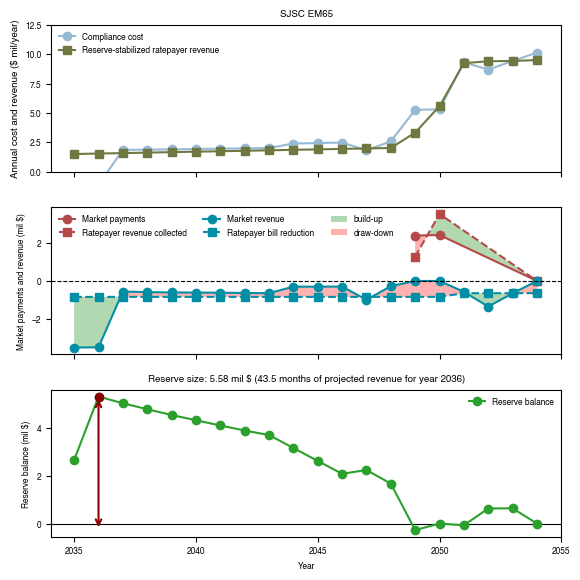

    Sunnyvale
    Sunnyvale average credit payment: 25.22 $ per unit
Market type EM65 for reserve_balance:
    Reserve range: 7.28 mil $ (51.9 mo) with revenue 51.94 mil $/yr.   (75.1 mo  for extreme year 2048 with expense 1.16 mil $/yr).
Market type EM65 for reserve_balance_buyer:
    Reserve range: 7.28 mil $ (51.9 mo) with revenue 51.94 mil $/yr.   (75.1 mo  for extreme year 2048 with expense 1.16 mil $/yr).
Market type EM65 for reserve_balance_seller:
    Reserve range: 0.00 mil $ (0.0 mo) with revenue 0.00 mil $/yr.   (0.0 mo  for extreme year 2037 with expense 0.05 mil $/yr).
Maximum number of cycles: 1
Total CoC: 24
Total revenue: 24


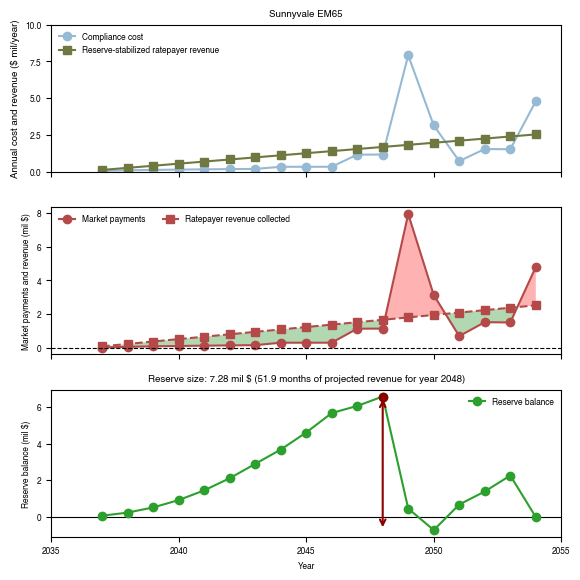

In [64]:
import matplotlib.pyplot as plt
import numpy as np

WWTP = 'Palo Alto'
df = df_centralized_market.copy()
df_NC = df_NC.copy()
market_type = 'CH-AC'

WWTPs = ['Palo Alto']
#WWTPs = ['SJSC']
#WWTPs = ['Sunnyvale']
WWTPs = ['Palo Alto', 'SJSC', 'Sunnyvale']

#market_types = ['CH-AC', 'EM65', 'BT18','NM']
market_types = ['CH-AC', 'EM65']
#market_types = ['BT18']
years_label = [2035, 2040, 2045, 2050, 2055]  # label every 5 years

for market_type in market_types:
    print(f"Calculating maximum drawdown for market type: {market_type}")
    if market_type == 'NM':
        df = df_NC.copy()
        dfs_markets_PA_first_key = list(dfs_markets_PA.keys())[0]
        market_transactions = dfs_markets_PA[dfs_markets_PA_first_key].copy()
    elif 'BT' in market_type:
        df = df_bilat_market
        market_transactions = dfs_markets_PA[market_type].copy()
    else:
        df = df_centralized_market
        market_transactions = dfs_markets_PA[market_type].copy()
    
    
    for WWTP in WWTPs:
        print(f"    {WWTP}")

        market_transactions, df_volatility, results, results_buyer, results_seller = calculate_ratepayer_bill_maxReserveSize(WWTP, df, df_NC, market_transactions, market_type, verbose=True)


        # ---- pull everything from the returned objects ----
        years   = df_volatility['Year'].to_numpy()
        balance = df_volatility['reserve_balance'].to_numpy()          # end-of-year fund balance (mil $)
        market = df_volatility[f'{WWTP}_market_CoC'].to_numpy()          # market payments (mil $)
        cycles  = df_volatility['billing_cycle'].to_numpy()
        print('Maximum number of cycles:', df_volatility['billing_cycle'].max())


        balance = df_volatility['reserve_balance'].to_numpy(float)   # realized end-of-year balances (mil $)
        injection = max(0.0, -results['min_balance'])                # up-front cash so the fund never goes negative
        plot_balance = balance.round(2)

        df_volatility_payments = df_volatility[df_volatility['Ratepayer_rev_collected_market'] > 0].copy()
        df_volatility_revenue = df_volatility[df_volatility['Ratepayer_rev_collected_market_revenue'] > 0].copy()

        fig, axs = plt.subplots(3, 1, figsize=(150/25.4, 150/25.4))

        # ================= Top: compliance cost vs. levelized revenue =================
        axs[0].plot(years, df_volatility[f'{WWTP}_market_CoC'], marker='o', color = "#96bad4",
                    label='Compliance cost')
        axs[0].plot(years, df_volatility['Ratepayer_rev_collected'], marker='s', color = "#6f7840",
                    label='Reserve‑stabilized ratepayer revenue')

        print('Total CoC:', round(df_volatility[f'{WWTP}_market_CoC'].sum()))
        print('Total revenue:', round(df_volatility['Ratepayer_rev_collected'].sum()))
        # shade billing cycles so the levelized steps are visible


        CoC_max = df_volatility[f'{WWTP}_market_CoC'].max()
        if CoC_max < 2.5:
            factor = 0.5
        else:
            factor = 2.5

        CoC_max = (df_volatility[f'{WWTP}_market_CoC'].max()//factor) * factor + factor
        
        axs[0].set_xticks(years_label)
        axs[0].set_xticklabels([], **hfont_ticks)
        axs[0].set_ylim(0, CoC_max - factor)
        axs[0].set_yticks(np.arange(0, CoC_max + 0.1, factor))
        axs[0].set_yticklabels(np.arange(0, CoC_max + 0.1, factor), **hfont_ticks)
        axs[0].set_ylabel(f'Annual cost and revenue ($ mil/year)', **hfont)
        axs[0].set_title(f'{WWTP} {results["market_type"]}', **hfont)
        axs[0].legend(prop={'family':'Helvetica', 'size':lab_size}, loc='best', frameon=False)

        # ================= Middle: market ratepayer bill + reserve fund balance =================
        #"""
        if df_volatility_payments.empty:
            pass
        else:
            payments = df_volatility_payments[f'{WWTP}_payment'].to_numpy(float)
            Rev_collected = df_volatility_payments['Ratepayer_rev_collected_market'].to_numpy(float)
            axs[1].plot(df_volatility_payments.Year,payments, marker='o', color = "#b34a49",
                        label='Market payments')
            axs[1].plot(df_volatility_payments.Year, Rev_collected, marker='s',color = "#b34a49", linestyle='dashed',
                        label='Ratepayer revenue collected')
            axs[1].fill_between(df_volatility_payments.Year, Rev_collected, payments, where=(Rev_collected >= payments),facecolor='green', alpha=0.3, interpolate=True, label='')
            axs[1].fill_between(df_volatility_payments.Year, Rev_collected, payments, where=(Rev_collected < payments), facecolor='red', alpha=0.3, interpolate=True, label='')
        #"""
        if df_volatility_revenue.empty:
            pass
        else:
            revenue = df_volatility_revenue[f'{WWTP}_revenue_after_opex'].to_numpy(float)
            Rev_collected = df_volatility_revenue['Ratepayer_rev_collected_market_revenue'].to_numpy(float)
            
            axs[1].plot(df_volatility_revenue.Year, -revenue, marker='o', color = "#028fa5", 
                        label='Market revenue')
            axs[1].plot(df_volatility_revenue.Year, -Rev_collected, marker='s',color = "#028fa5", linestyle='dashed',
                        label='Ratepayer bill reduction')
            axs[1].fill_between(df_volatility_revenue.Year, -Rev_collected, -revenue, where=(Rev_collected < revenue),facecolor='green', alpha=0.3, interpolate=True, label='build-up')
            axs[1].fill_between(df_volatility_revenue.Year, -Rev_collected, -revenue, where=(Rev_collected >= revenue), facecolor='red', alpha=0.3, interpolate=True, label='draw-down')
        #"""
        axs[1].axhline(0, color='black', lw=0.8, ls='--')
        axs[1].set_xticks(years_label)
        axs[1].set_xticklabels([], **hfont_ticks)
        axs[1].set_ylabel('Market payments and revenue (mil $)', **hfont_ticks)
        axs[1].legend(prop={'family':'Helvetica', 'size':lab_size}, loc='best', frameon=False, ncol=3)
        
        # ================= Bottom: reserve fund balance each year =================
        axs[2].axhline(0, color='black', lw=0.8)
        axs[2].plot(years, plot_balance, marker='o', color='tab:green', label='Reserve balance')
    
        # mark the peak (max surplus) and trough (min balance); their span = the reserve range
        #"""
        ey = results['extreme_year']
        # span the full reserve range (max_balance -> min_balance), drawn at the extreme year
        top = results['max_balance']
        bot = results['min_balance']
        # if the fund is pre-loaded for the plot, shift the endpoints too
        if results['reserve_months'] > 0.001:
            axs[2].annotate('', xy=(ey, bot), xytext=(ey, top),
                            arrowprops=dict(arrowstyle='<->', color='darkred', lw=1.5))
            axs[2].scatter([ey], [plot_balance[years == ey][0]], color='darkred', zorder=5, s=35)


        head = f"Reserve size: {results['reserve_range']:.2f} mil $ ({results['reserve_months']:.1f} months of projected revenue for year {ey})"
        axs[2].set_title(head, **hfont)
        axs[2].set_xticks(years_label)
        axs[2].set_xticklabels(years_label, **hfont_ticks)
        axs[2].set_ylabel('Reserve balance (mil $)', **hfont_ticks)
        axs[2].set_xlabel('Year', **hfont_ticks)
        axs[2].legend(prop={'family':'Helvetica', 'size':lab_size}, loc='best', frameon=False)

        for ax in axs:
            for lbl in ax.get_yticklabels() + ax.get_xticklabels():
                lbl.set(**hfont_ticks)
        
        
        fig.tight_layout()
        plt.show()
        name = f"{file}/SI/ReserveFund_3_{WWTP}_{market_type}.svg"
        fig.savefig(name, format='svg', dpi=300)

In [65]:
WWTP = 'Palo Alto'
market_type = 'CH-AC'
df = df_centralized_market
market_transactions = dfs_markets_PA[market_type].copy()

market_transactions, df_volatility, results, results_buyer, results_seller = calculate_ratepayer_bill_maxReserveSize(WWTP, df, df_NC, market_transactions, market_type, verbose=True)

    Palo Alto average credit payment: 4.67 $ per unit
    Palo Alto billing cycle 3: total market revenue after opex: 6.06 mil, total market revenue collected: 6.06 mil
Market type CH-AC for reserve_balance:
    Reserve range: 2.24 mil $ (2.6 mo) with revenue 2.57 mil $/yr.   (2.5 mo  for extreme year 2047 with expense 10.87 mil $/yr).
Market type CH-AC for reserve_balance_buyer:
    Reserve range: 0.37 mil $ (0.5 mo) with revenue 0.47 mil $/yr.   (0.5 mo  for extreme year 2040 with expense 9.65 mil $/yr).
Market type CH-AC for reserve_balance_seller:
    Reserve range: 2.22 mil $ (2.5 mo) with revenue 2.55 mil $/yr.   (2.4 mo  for extreme year 2047 with expense 10.87 mil $/yr).


Calculating ratepayer revenue for CH-AC
    Palo Alto average credit payment: 4.67 $ per unit
    Palo Alto billing cycle 3: total market revenue after opex: 6.06 mil, total market revenue collected: 6.06 mil
Calculating ratepayer revenue for CH-AC
    Palo Alto average credit payment: 4.67 $ per unit
    Palo Alto billing cycle 3: total market revenue after opex: 6.06 mil, total market revenue collected: 6.06 mil
Calculating ratepayer revenue for CH-AC
    Sunnyvale average credit payment: 9.50 $ per unit
Calculating ratepayer revenue for CH-AC
    Sunnyvale average credit payment: 9.50 $ per unit
Calculating ratepayer revenue for CH-AC
    SJSC average credit payment: 15.43 $ per unit
    SJSC billing cycle 1: total market revenue after opex: 6.96 mil, total market revenue collected: 6.96 mil
    SJSC billing cycle 2: total market revenue after opex: 1.47 mil, total market revenue collected: 1.47 mil
Calculating ratepayer revenue for CH-AC
    SJSC average credit payment: 15.43 $ per

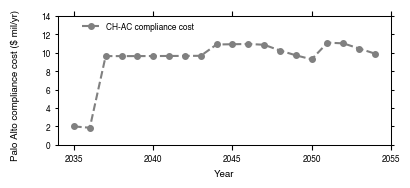

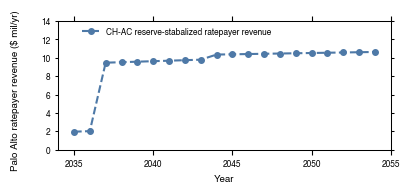

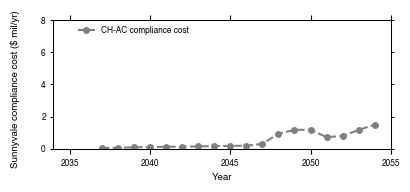

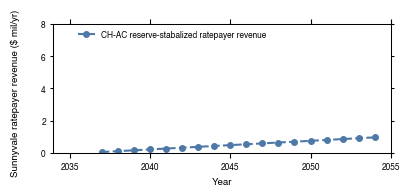

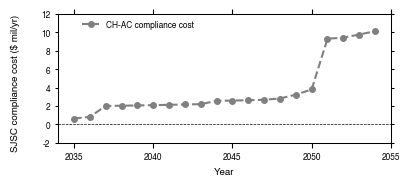

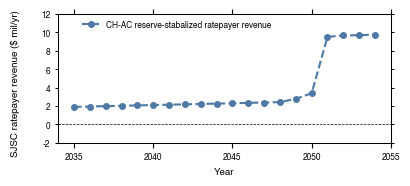

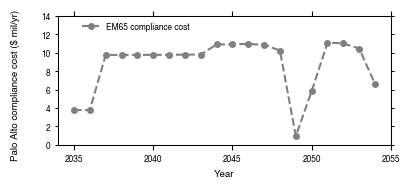

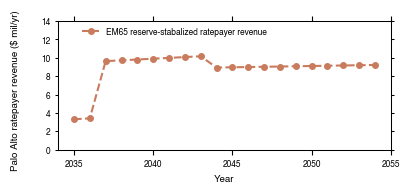

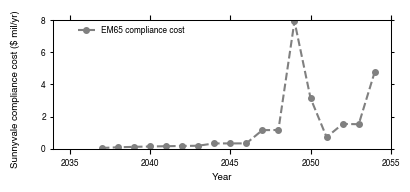

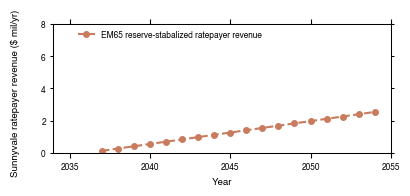

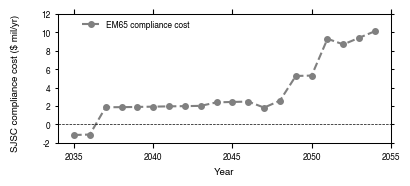

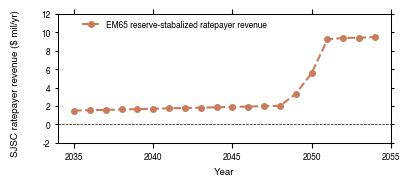

In [66]:
import numpy as np

def stepify(x, y, where='pre'):
    x = np.asarray(x)
    y = np.asarray(y)
    if where == 'pre':
        x_new = np.repeat(x, 2)[:-1]
        y_new = np.repeat(y, 2)[1:]
    elif where == 'post':
        x_new = np.repeat(x, 2)[1:]
        y_new = np.repeat(y, 2)[:-1]
    elif where == 'mid':
        x_mid = (x[:-1] + x[1:]) / 2
        x_new = np.concatenate([[x[0]], np.repeat(x_mid, 2), [x[-1]]])
        y_new = np.repeat(y, 2)
    else:
        raise ValueError("where must be 'pre', 'post', or 'mid'")
    return x_new, y_new


def plot_reserve_fund_market(WWTP, df, df_NC, market_transactions_basecase, total_cost_savings_basecase, market_list, ylim_val, ytick_marks=10, show_plot = True, text_tag = 'both', plot_market = True, name_tag = '', rev_stablized=True):
    markers = ['o', '^', 's', 'D', 'v', 'P', '*', 'X', '<', '>']
    colors_WWTP = {'Sunnyvale': '#B79BB8', 'SJSC': '#D57A6E', 'Palo Alto': '#A3B89C'}
    #plot_tag_type = 'step_function'
    plot_tag_type= 'line'
    
    color_markets = {'CH': '#4E79A7', 'EM': '#C97C5D'}
    if len(market_list) > 3:
        colors = sns.color_palette("husl", len(market_list))
    else:
        colors = ['#e41a1c', '#377eb8', '#4daf4a']
    reserve_months_dict = {}
    market_transactions_dict = {}
    eps = 0.01
    
    if show_plot:
        fig, axs = plt.subplots(len(market_list),1, figsize=(105/25.4, (len(market_list)*30 + 20)/25.4))
    
    market_list_OPERATIONAL = []
    for market in total_cost_savings_basecase.keys():
        if not any(total_cost_savings_basecase[market][WWTP] < 0 for WWTP in WWTPs):
            market_list_OPERATIONAL.append(market)
        elif 'BT' in market:
            market_list_OPERATIONAL.append(market)
    
    for j, market in enumerate(market_list):

            print(f"Calculating ratepayer revenue for {market}")
            market_transactions_dict['NM'], df_volatility_NM, results, results_buyer, results_seller = calculate_ratepayer_bill_maxReserveSize(WWTP, df, df_NC, market_transactions_basecase[market], 'NM', verbose=False)
            reserve_months_dict['NM'] = results['reserve_months']
            market_trasnactions = market_transactions_dict['NM']
            
            if show_plot:
                """
                if j==0:
                    axs[j].plot(df_volatility_NM.Year, df_volatility_NM.Ratepayer_rev_collected, label='No market', color='grey', linestyle='--', linewidth=2)
                else:
                    axs[j].plot(df_volatility_NM.Year, df_volatility_NM.Ratepayer_rev_collected, label='', color='grey', linestyle='--', linewidth=2)
                """
                if len(market_list) > 1:
                    ax = axs[j]
                else:
                    ax = axs

                if plot_market:

                    market_transactions_dict[market], df_volatility_market, results, results_buyer, results_seller = calculate_ratepayer_bill_maxReserveSize(WWTP, df, df_NC, market_transactions_basecase[market], market, verbose=False)
                    
                    
                    Rev_collected = df_volatility_market.Ratepayer_rev_collected
                    CoC_plant = df_volatility_market[f'{WWTP}_market_CoC']
                    market_transactions_base = market_transactions_dict[market]


                    if 'CH' in market:
                        color_tag = color_markets['CH']
                    elif 'EM' in market:
                        color_tag = color_markets['EM']
                    else:
                        color_tag = 'grey'

                    if rev_stablized:

                        line_cost, = ax.plot(market_transactions_base.Year, Rev_collected, 
                                                            color=color_tag, linestyle='--', linewidth=1.5, 
                                                            marker='o', markersize=4,
                                                            label =f'{market_list[j]} reserve-stabalized ratepayer revenue')
                    
                    else: 
                        line_cost, = ax.plot(market_transactions_base.Year, CoC_plant,
                                                                                    color='grey', linestyle='--', linewidth=1.5, 
                                                                                    marker='o', markersize=4,
                                                                                    label =f'{market_list[j]} compliance cost')
                    
                        

            #'''
            years = df.Year.to_numpy()
            if j < 2:
                if text_tag == 'both':
                        print(f'{market_list[j]}')
                        print(f'    Reserve required = {round(reserve_months_dict[market])} months')
                        print(f'    Compliance cost savings =  {round(total_cost_savings_basecase[market][WWTP])}%')
                        #axs[j].text(years[10], ylim_val[1] - (ylim_val[1] - ylim_val[0])* 0.95, f'{market_list[j]}:   Market reserve required = {round(reserve_months_dict[market],1)} months;  Compliance cost savings =  {round(total_cost_savings_basecase[market][WWTP])}%'  , **hfont_ticks, color='#374134', ha = 'left', fontweight= 'bold')
                        ax.text(years[12], ylim_val[1] - (ylim_val[1] - ylim_val[0])* 0.9, 
                                    f'Compliance cost savings =  {round(total_cost_savings_basecase[market][WWTP])}%\nMarket reserve required = {round(reserve_months_dict[market])} months'  , 
                                    **hfont_ticks, color='#374134', ha = 'left', fontweight= 'bold')
                elif text_tag == 'none' or text_tag == False:
                    pass
                else:
                        #axs[j].text(years[10], ylim_val[1] - (ylim_val[1] - ylim_val[0])* 0.93, f'{market_list[0]} (reduction in future demand):   MAD = {round(mad_markets_norm[market])}%;  Cost saving =  {round(total_cost_savings[market][WWTP])}%'  , **hfont_ticks, color='black', ha = 'left', fontweight= 'bold')
                        ax.text(years[10], ylim_val[1] - (ylim_val[1] - ylim_val[0])* 0.95, f'Compliance cost savings with reduced credit demand =  {round(total_cost_savings_basecase[market][WWTP],1)}%'  , **hfont_ticks, color='black', ha = 'left', fontweight= 'bold')
            #'''

            ax.set_ylim(ylim_val[0], ylim_val[1])
            ax.set_yticks(np.arange(ylim_val[0], ylim_val[1]+1, ytick_marks))
            if ylim_val[0] < 0:
                ax.axhline(y=0, color='black', linestyle='--', linewidth=0.5)

            ax.set_xlim(years[9],years[30])
            ax.set_xticks(np.arange(years[10], years[30]+1, 5))
            ax.set_xticklabels(np.arange(years[10], years[30]+1, 5), **hfont_ticks)
            
            ax.xaxis.set_ticks_position('both')
            ax.set_xticklabels(ax.get_xticks(), **hfont_ticks)
            ax.set_yticklabels(ax.get_yticks(), **hfont_ticks)
            if j< len(market_list)-1:
                ax.xaxis.set_ticks_position('bottom')
                ax.set_xticklabels([])
                ax.set_xlabel('')
            else:
                 ax.set_xlabel('Year', **hfont)
            
            #axs[j].legend(loc='upper center', frameon=False, prop={'family':'Helvetica', 'size':lab_size}, ncol=3, bbox_to_anchor=(0.5, 1.01))
            ax.legend(handles=[line_cost], loc='upper left', frameon=False, prop={'family':'Helvetica', 'size':lab_size}, bbox_to_anchor=(0.05, 1.01), ncol=2)
            
            ax.yaxis.set_ticks_position('both')
            

                
            ax.tick_params(axis="y", width=line_wid, length=bord_wid, labelsize=leg_size)
            for spine in ax.spines.values():
                spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)
                
    
    # add ylabel for the entire figure

    #fig.legend(loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.05), frameon=False, prop={'family':'Helvetica', 'size':lab_size})
    
    if rev_stablized:
        fig.supylabel(f'{WWTP} ratepayer revenue ($ mil/yr)', **hfont, x=0.02, y=0.55)
    else:
        fig.supylabel(f'{WWTP} compliance cost ($ mil/yr)', **hfont, x=0.02, y=0.55)
    if show_plot:
        plt.tight_layout()

        name = WWTP + '_' + market+ '_CoC'
        
        if text_tag:
            name += '_' + text_tag
        if name_tag != '':
            name += '_' + name_tag
        if rev_stablized:
            name += '_rev_stablized'
        if not plot_market:
             name += '_no_market'
        plt.savefig(file + f'/SI/{name}.svg', format='svg', dpi=300)
    
    return reserve_months_dict

market_list = [['CH-AC'], ['EM65']]
for market in market_list:
#reserve_months_dict = plot_reserve_fund_palo_alto('Palo Alto', df_centralized_market, df_NC, dfs_markets_PA, total_cost_savings_PA, ['CH-AC','EM65'], [0, 14], ytick_marks=2, show_plot = True, text_tag = 'none', plot_market = True, name_tag = '', rev_stablized=False)
#reserve_months_dict = plot_reserve_fund_palo_alto('Palo Alto', df_centralized_market, df_NC, dfs_markets_PA, total_cost_savings_PA, ['CH-AC','EM65'], [0, 14], ytick_marks=2, show_plot = True, text_tag = 'none', plot_market = True, name_tag = '', rev_stablized=True)
    reserve_months_dict = plot_reserve_fund_market('Palo Alto', df_centralized_market, df_NC, dfs_markets_PA, total_cost_savings_PA, market, [0, 14], ytick_marks=2, show_plot = True, text_tag = False, plot_market = True, name_tag = '', rev_stablized=False)
    reserve_months_dict = plot_reserve_fund_market('Palo Alto', df_centralized_market, df_NC, dfs_markets_PA, total_cost_savings_PA, market, [0, 14], ytick_marks=2, show_plot = True, text_tag = False, plot_market = True, name_tag = '', rev_stablized=True)
    reserve_months_dict = plot_reserve_fund_market('Sunnyvale', df_centralized_market, df_NC, dfs_markets_PA, total_cost_savings_PA, market, [0, 8], ytick_marks=2, show_plot = True, text_tag = False, plot_market = True, name_tag = '', rev_stablized=False)
    reserve_months_dict = plot_reserve_fund_market('Sunnyvale', df_centralized_market, df_NC, dfs_markets_PA, total_cost_savings_PA, market, [0, 8], ytick_marks=2, show_plot = True, text_tag = False, plot_market = True, name_tag = '', rev_stablized=True)
    reserve_months_dict = plot_reserve_fund_market('SJSC', df_centralized_market, df_NC, dfs_markets_PA, total_cost_savings_PA, market, [-2, 12], ytick_marks=2, show_plot = True, text_tag = False, plot_market = True, name_tag = '', rev_stablized=False)
    reserve_months_dict = plot_reserve_fund_market('SJSC', df_centralized_market, df_NC, dfs_markets_PA, total_cost_savings_PA, market, [-2, 12], ytick_marks=2, show_plot = True, text_tag = False, plot_market = True, name_tag = '', rev_stablized=True)

    Palo Alto average credit payment: 4.67 $ per unit
    Palo Alto billing cycle 3: total market revenue after opex: 6.06 mil, total market revenue collected: 6.06 mil
    Palo Alto average credit payment: 7.00 $ per unit
    Palo Alto billing cycle 3: total market revenue after opex: 9.59 mil, total market revenue collected: 9.59 mil
    Palo Alto average credit payment: 7.43 $ per unit
    Palo Alto billing cycle 3: total market revenue after opex: 10.38 mil, total market revenue collected: 10.38 mil
    Palo Alto average credit payment: 7.86 $ per unit
    Palo Alto billing cycle 3: total market revenue after opex: 11.17 mil, total market revenue collected: 11.17 mil
    Palo Alto average credit payment: 8.28 $ per unit
    Palo Alto billing cycle 3: total market revenue after opex: 11.96 mil, total market revenue collected: 11.96 mil
    Palo Alto average credit payment: 8.71 $ per unit
    Palo Alto billing cycle 3: total market revenue after opex: 12.75 mil, total market revenue

/var/folders/c4/xftw48qx1ln6q3hxvkc80tdw0000gn/T/ipykernel_3495/3031489146.py:208: MatplotlibDeprecationWarning: An artist whose label starts with an underscore was passed to legend(); such artists will no longer be ignored in the future.  To suppress this warning, explicitly filter out such artists, e.g. with `[art for art in artists if not art.get_label().startswith('_')]`.
  legend2 = axs[j].legend(handles=[fill_build, fill_draw], loc='upper left', frameon=False,


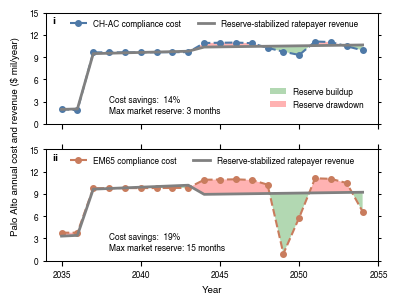

In [67]:
import numpy as np

def stepify(x, y, where='pre'):
    x = np.asarray(x)
    y = np.asarray(y)
    if where == 'pre':
        x_new = np.repeat(x, 2)[:-1]
        y_new = np.repeat(y, 2)[1:]
    elif where == 'post':
        x_new = np.repeat(x, 2)[1:]
        y_new = np.repeat(y, 2)[:-1]
    elif where == 'mid':
        x_mid = (x[:-1] + x[1:]) / 2
        x_new = np.concatenate([[x[0]], np.repeat(x_mid, 2), [x[-1]]])
        y_new = np.repeat(y, 2)
    else:
        raise ValueError("where must be 'pre', 'post', or 'mid'")
    return x_new, y_new


def plot_reserve_fund_palo_alto(WWTP, df, df_NC, market_transactions_basecase, total_cost_savings_basecase, market_list, ylim_val, ytick_marks=10, show_plot = True, text_tag = 'both', plot_market = True, name_tag = ''):
    markers = ['o', '^', 's', 'D', 'v', 'P', '*', 'X', '<', '>']
    colors_WWTP = {'Sunnyvale': '#B79BB8', 'SJSC': '#D57A6E', 'Palo Alto': '#A3B89C'}
    #plot_tag_type = 'step_function'
    plot_tag_type= 'line'
    
    color_markets = {'CH': '#4E79A7', 'EM': '#C97C5D'}
    if len(market_list) > 3:
        colors = sns.color_palette("husl", len(market_list))
    else:
        colors = ['#e41a1c', '#377eb8', '#4daf4a']
    reserve_months_dict = {}
    market_transactions_dict = {}
    eps = 0.01
    
    if show_plot:
        fig, axs = plt.subplots(len(market_list),1, figsize=(105/25.4, 80/25.4))
    
    market_list_OPERATIONAL = []
    for market in total_cost_savings_basecase.keys():
        if not any(total_cost_savings_basecase[market][WWTP] < 0 for WWTP in WWTPs):
            market_list_OPERATIONAL.append(market)
        elif 'BT' in market:
            market_list_OPERATIONAL.append(market)
    
    for j, market in enumerate(market_list):

            market_transactions_dict['NM'], df_volatility_NM, results, results_buyer, results_seller = calculate_ratepayer_bill_maxReserveSize(WWTP, df, df_NC, market_transactions_basecase[market], 'NM', verbose=False)
            reserve_months_dict['NM'] = results['reserve_months']
            market_trasnactions = market_transactions_dict['NM']
            
            if show_plot:
                """
                if j==0:
                    axs[j].plot(df_volatility_NM.Year, df_volatility_NM.Ratepayer_rev_collected, label='No market', color='grey', linestyle='--', linewidth=2)
                else:
                    axs[j].plot(df_volatility_NM.Year, df_volatility_NM.Ratepayer_rev_collected, label='', color='grey', linestyle='--', linewidth=2)
                """
                if plot_market:
                    Ratepayer_rev_collected_markets = {}
                    CoC_plant_markets = {}
                    df_volatility_markets = {}
                    
                    for market_loop in market_list_OPERATIONAL:
                        market_transactions_dict[market_loop], df_volatility_markets[market_loop], results, results_buyer, results_seller = calculate_ratepayer_bill_maxReserveSize(WWTP, df, df_NC, market_transactions_basecase[market_loop], market_loop, verbose=False)
                        reserve_months_dict[market_loop] = results['reserve_months']
                        market_transactions_base = market_transactions_dict[market_loop]
                        Ratepayer_rev_collected_markets[market_loop] = df_volatility_markets[market_loop].Ratepayer_rev_collected
                        CoC_plant_markets[market_loop] = df_volatility_markets[market_loop][f'{WWTP}_market_CoC']
                        """
                        if 'EM' in market and 'EM' in market_loop: 
                            print(f"Calculating ratepayer bill for {market_loop}")
                            market_transactions_dict[market_loop], df_volatility_markets[market_loop], results, results_buyer, results_seller = calculate_ratepayer_bill_maxReserveSize(WWTP, df, df_NC, market_transactions_basecase[market_loop], market_loop, verbose=False)
                            reserve_months_dict[market_loop] = results['reserve_months']
                            market_transactions_base = market_transactions_dict[market_loop]
                            Ratepayer_rev_collected_markets[market_loop] = df_volatility_markets[market_loop].Ratepayer_rev_collected
                            CoC_plant_markets[market_loop] = df_volatility_markets[market_loop][f'{WWTP}_market_CoC']
                            
                        elif 'CH' in market and 'CH' in market_loop:
                            print(f"Calculating ratepayer bill for {market_loop}")
                            market_transactions_dict[market_loop], df_volatility_markets[market_loop], results, results_buyer, results_seller = calculate_ratepayer_bill_maxReserveSize(WWTP, df, df_NC, market_transactions_basecase[market_loop], market_loop, verbose=False)
                            reserve_months_dict[market_loop] = results['reserve_months']
                            market_transactions_base = market_transactions_dict[market_loop]
                            Ratepayer_rev_collected_markets[market_loop] = df_volatility_markets[market_loop].Ratepayer_rev_collected
                            CoC_plant_markets[market_loop] = df_volatility_markets[market_loop][f'{WWTP}_market_CoC']
                            """
                    
                    Rev_collected = df_volatility_markets[market].Ratepayer_rev_collected
                    CoC_plant = df_volatility_markets[market][f'{WWTP}_market_CoC']
                    Y = np.vstack([np.asarray(v) for v in Ratepayer_rev_collected_markets.values()])
                    #Y = np.vstack([np.asarray(v) for v in CoC_plant_markets.values()])
                    ymin, ymax = Y.min(0), Y.max(0)
                    
                    
                    if 'EM' in market:
                        label_tag = 'EM design space'
                        color_tag = color_markets['EM']
                        #axs[j].fill_between(market_transactions_base.Year, ymin, ymax, facecolor='black', alpha=0.5, label = f'{label_tag}')
                        #axs[j].step(market_transactions_base.Year, CoC_plant, color='grey', linestyle='--', linewidth=2, label =f'{market_list[j]} compliance cost', where='pre')
                        
                        
                        #axs[j].plot(market_transactions_base.Year, CoC_plant, linestyle='-', linewidth=2, color = 'black', label =f'{market_list[j]} compliance cost')
                    
                    elif 'CH' in market:
                        label_tag = 'CH design space'
                        color_tag = color_markets['CH']
                        #axs[j].step(market_transactions_base.Year, CoC_plant, linestyle=':', linewidth=1.5, color = 'black', label =f'{market_list[j]} compliance cost', where='pre')
                    
                    
                    if plot_tag_type == 'step':
                        #axs[j].step(market_transactions_base.Year, CoC_plant, color='grey', linestyle='--', linewidth=2, label =f'{market_list[j]} compliance cost', where='pre')
                        #axs[j].step(market_transactions_base.Year, Rev_collected, linestyle='-', linewidth=2, color = color_tag, label =f'Reserve‑stabilized ratepayer revenue', where='pre', alpha = 0.8)
                        axs[j].step(market_transactions_base.Year, CoC_plant, color='grey', linestyle='--', linewidth=1, label =f'{market_list[j]} compliance cost', marker='o', markersize=1.5, where='mid')
                        axs[j].step(market_transactions_base.Year, Rev_collected, linestyle='-', linewidth=2, color = color_tag, label =f'Reserve‑stabilized ratepayer revenue', alpha = 0.8, where='mid')
                        axs[j].fill_between(market_transactions_base.Year, Rev_collected, CoC_plant, where=(Rev_collected >= CoC_plant),facecolor='green', alpha=0.3, label='', step='mid')
                        axs[j].fill_between(market_transactions_base.Year, Rev_collected, CoC_plant, where=(Rev_collected >= CoC_plant),facecolor='green', alpha=0.3, label='', step='mid')
                        axs[j].fill_between(market_transactions_base.Year, Rev_collected, CoC_plant, where=(Rev_collected < CoC_plant), facecolor='red', alpha=0.3, label='', step='mid')
                    elif plot_tag_type == 'step_function':


                        years = market_transactions_base.Year
                        where_tag = 'mid'
                        x_s, CoC_s   = stepify(years, CoC_plant,     where=where_tag)
                        _,   Rev_s   = stepify(years, Rev_collected, where=where_tag)

                        axs[j].step(years, CoC_plant, color='grey', linestyle='-', linewidth=1.5, 
                                    #marker='o', markersize=3,
                                    label =f'{market_list[j]} compliance cost', where=where_tag, alpha=1)
                        axs[j].step(years, Rev_collected, linestyle='-', linewidth=2, color=color_tag,
                                    label='Reserve‑stabilized ratepayer revenue', where=where_tag, alpha=1)

                        axs[j].fill_between(x_s, CoC_s, Rev_s, where=(Rev_s >= CoC_s),
                                            interpolate=True, facecolor='green', alpha=0.3, label='')
                        axs[j].fill_between(x_s, CoC_s, Rev_s, where=(Rev_s < CoC_s),
                                            interpolate=True, facecolor='red', alpha=0.3, label='')

                    else:
                        #rev_label = 'Reserve‑stabilized\nratepayer revenue' if j == 0 else ''
                        rev_label = 'Reserve‑stabilized ratepayer revenue'
                        #rev_label = 'Reserve‑stabilized ratepayer revenue'
                        build_label = 'Reserve buildup' if j == 0 else ''
                        draw_label = 'Reserve drawdown' if j == 0 else ''

                        line_cost, = axs[j].plot(market_transactions_base.Year, CoC_plant, 
                                    #color='grey', linestyle='--', linewidth=1.5, 
                                    color=color_tag, linestyle='--', linewidth=1.5, 
                                    marker='o', markersize=4,
                                    label =f'{market_list[j]} compliance cost')
                        line_rev, = axs[j].plot(market_transactions_base.Year, Rev_collected, linestyle='-', linewidth=2, color = 'grey', label=rev_label, alpha = 1)
                        fill_build = axs[j].fill_between(market_transactions_base.Year, Rev_collected, CoC_plant, where=(Rev_collected >= CoC_plant),facecolor='green', alpha=0.3, interpolate=True, label=build_label)
                        fill_draw= axs[j].fill_between(market_transactions_base.Year, Rev_collected, CoC_plant, where=(Rev_collected < CoC_plant), facecolor='red', alpha=0.3, interpolate=True, label=draw_label)
                    
                        

            #'''
            years = df.Year.to_numpy()
            if j < 2:
                if text_tag == 'both':
                        print(f'{market_list[j]}')
                        print(f'    Reserve required = {round(reserve_months_dict[market])} months')
                        print(f'    Compliance cost savings =  {round(total_cost_savings_basecase[market][WWTP])}%')
                        #axs[j].text(years[10], ylim_val[1] - (ylim_val[1] - ylim_val[0])* 0.95, f'{market_list[j]}:   Market reserve required = {round(reserve_months_dict[market],1)} months;  Compliance cost savings =  {round(total_cost_savings_basecase[market][WWTP])}%'  , **hfont_ticks, color='#374134', ha = 'left', fontweight= 'bold')
                        axs[j].text(years[13], ylim_val[1] - (ylim_val[1] - ylim_val[0])* 0.9, 
                                    #f'Compliance cost savings =  {round(total_cost_savings_basecase[market][WWTP])}%\nMarket reserve required = {round(reserve_months_dict[market])} months'  , 
                                    f'Cost savings:  {round(total_cost_savings_basecase[market][WWTP])}%\nMax market reserve: {round(reserve_months_dict[market])} months', 
                                    #**hfont_ticks, color='#374134', ha = 'left', fontweight= 'bold')
                                    **hfont_ticks, color='black', ha = 'left', fontweight= 'bold')
                else:
                        #axs[j].text(years[10], ylim_val[1] - (ylim_val[1] - ylim_val[0])* 0.93, f'{market_list[0]} (reduction in future demand):   MAD = {round(mad_markets_norm[market])}%;  Cost saving =  {round(total_cost_savings[market][WWTP])}%'  , **hfont_ticks, color='black', ha = 'left', fontweight= 'bold')
                        axs[j].text(years[10], ylim_val[1] - (ylim_val[1] - ylim_val[0])* 0.95, f'Compliance cost savings with reduced credit demand =  {round(total_cost_savings_basecase[market][WWTP],1)}%'  , **hfont_ticks, color='black', ha = 'left', fontweight= 'bold')
                        
            #'''

            axs[j].set_ylim(ylim_val[0], ylim_val[1])
            axs[j].set_yticks(np.arange(ylim_val[0], ylim_val[1]+1, ytick_marks))
            if ylim_val[0] < 0:
                axs[j].axhline(y=0, color='black', linestyle='--', linewidth=0.5)

            axs[j].set_xlim(years[9],years[30])
            axs[j].set_xticks(np.arange(years[10], years[30]+1, 5))
            axs[j].set_xticklabels(np.arange(years[10], years[30]+1, 5), **hfont_ticks)
            
            axs[j].xaxis.set_ticks_position('both')
            axs[j].set_xticklabels(axs[j].get_xticks(), **hfont_ticks)
            axs[j].set_yticklabels(axs[j].get_yticks(), **hfont_ticks)
            if j< len(market_list)-1:
                axs[j].xaxis.set_ticks_position('bottom')
                axs[j].set_xticklabels([])
                axs[j].set_xlabel('')
            else:
                 axs[j].set_xlabel('Year', **hfont)
            
            #axs[j].legend(loc='upper center', frameon=False, prop={'family':'Helvetica', 'size':lab_size}, ncol=3, bbox_to_anchor=(0.5, 1.01))
            shared_handles = [line_cost, line_rev, fill_build, fill_draw]
            shared_labels = ['Reserve‑stabilized\nratepayer revenue', 'Reserve buildup', 'Reserve drawdown']
            
            # First legend
            #legend1 = axs[j].legend(handles=[line_cost], loc='upper left', frameon=False,
            legend1 = axs[j].legend(handles=[line_cost, line_rev], loc='upper left', frameon=False,
                                    prop={'family': 'Helvetica', 'size': lab_size},
                                    bbox_to_anchor=(0.05, 1.01), ncol=2)

            # Re-attach the first legend as a standalone artist so it isn't removed
            axs[j].add_artist(legend1)

            # Second legend — creating this normally would otherwise wipe out legend1
            #legend2 = axs[j].legend(handles=[line_rev,fill_build, fill_draw], loc='upper left', frameon=False,
            legend2 = axs[j].legend(handles=[fill_build, fill_draw], loc='upper left', frameon=False,
                                    prop={'family': 'Helvetica', 'size': lab_size},
                                    bbox_to_anchor=(0.65, 0.4), ncol=1)
                                    #bbox_to_anchor=(0.65, 0.5), ncol=1)
            
            axs[j].yaxis.set_ticks_position('both')
            

                
            axs[j].tick_params(axis="y", width=line_wid, length=bord_wid, labelsize=leg_size)
            for spine in axs[j].spines.values():
                spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)
                
    
    # add ylabel for the entire figure
    shared_handles = [line_rev, fill_build, fill_draw]
    shared_labels = ['Reserve‑stabilized\nratepayer revenue', 'Reserve buildup', 'Reserve drawdown']
    #shared_handles = [fill_build, fill_draw]
    #shared_labels = ['Reserve buildup', 'Reserve drawdown']

    #fig.legend(shared_handles, shared_labels, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.05), frameon=False, prop={'family':'Helvetica', 'size':lab_size})
    
    fig_labels = ['i', 'ii', 'iii', 'iv']
    for i,ax in enumerate(axs):
        ax.text(0.02, 0.97, fig_labels[i], transform=ax.transAxes, fontsize=lab_size, fontweight='bold', va='top', ha='left')

    fig.supylabel(f'{WWTP} annual cost and revenue ($ mil/year)', **hfont, x=0.05, y=0.55)
    #axs[0].set_title(f'No limit on max credits; Trading ratio: 1:1 (Palo Alto)', **hfont)
    if show_plot:
        plt.tight_layout()

        name = WWTP + '_ratepayer_savings_single_market_new'
        
        if text_tag:
            name += '_' + text_tag
        if name_tag != '':
            name += '_' + name_tag
        if not plot_market:
             name += '_no_market'
        plt.savefig(file + f'/Fig_4a.svg', format='svg', dpi=300)
    

    return reserve_months_dict

reserve_months_dict = plot_reserve_fund_palo_alto('Palo Alto', df_centralized_market, df_NC, dfs_markets_PA, total_cost_savings_PA, ['CH-AC','EM65'], [0, 15], ytick_marks=3, show_plot = True, text_tag = 'both', plot_market = True, name_tag = '')

In [68]:
market_list = ['CH-AC', 'EM65']
#market_list = ['NM', 'BT18']
#plot_reserve_fund_palo_alto('Palo Alto', df_centralized_market, df_NC, dfs_markets_PA, total_cost_savings_PA, market_list, [0, 15], ytick_marks=3, show_plot = True, text_tag = 'both', plot_market = True, name_tag = '')
#plot_reserve_fund_palo_alto('Sunnyvale', df_centralized_market, df_NC, dfs_markets_PA, total_cost_savings_PA, market_list, [0,10], ytick_marks=2, show_plot = True, text_tag = 'both', plot_market = True, name_tag = '')
#plot_reserve_fund_palo_alto('SJSC', df_centralized_market, df_NC, dfs_markets_PA, total_cost_savings_PA, market_list, [0,10], ytick_marks=2, show_plot = True, text_tag = 'both', plot_market = True, name_tag = '')

# Plot Cost savings vs MAD with sensitivity 

## Plot cost Saving vs MAD:

### Plot different trading ratios

## Plot Reserve months vs Cost Savings

In [69]:
from copyreg import pickle


WWTPs = ['Palo Alto', 'SJSC', 'Sunnyvale']
TR_HP_tuples = [(1.0, 300), (2.0, 300), (1.0, 0.25), (2.0, 0.25)]
TR_HP_tuples = [(1.0, 300), (2.0, 300), (1.5, 300)]
TR_HP_tuples = [(1.0, 300), (1.5, 300)]
#TR_HP_tuples = [(1.5, 300)]
TR_HP_tuples = [(2.0, 300), (2.5, 300), (1.0, 0.25), (1.5, 0.25), (2.0, 0.25), (2.5, 0.25)]
#TR_HP_tuples = [(1.5, 300)]

TRs = [1.0, 1.5, 2.0, 2.5]
HPs = [0.1, 0.5, 0.25, 300]

TR_HP_tuples = [(TR, HP) for TR in TRs for HP in HPs]
#TR_HP_tuples = [(1.0, 300), (1.0, 0.1)]

try:
    dfs_markets_all
    total_cost_savings_all
    reserve_markets_all
    dfs_bilat_30yrs 
    dfs_centralized
except:
    try:
        del pickle
        import pickle

        with open(f"{file}/dfs_markets_all.pkl", "rb") as f:
            dfs_markets_all = pickle.load(f)
        with open(f"{file}/total_cost_savings_all.pkl", "rb") as f:
            total_cost_savings_all = pickle.load(f)
        with open(f"{file}/reserve_markets_all.pkl", "rb") as f:
            reserve_markets_all = pickle.load(f)
        print("Existing data loaded successfully.")
        replace_files = False
        dfs_bilat_30yrs = {}
        dfs_centralized = {}

    except:
        print("No existing data found. Starting new simulation.")
        dfs_markets_all = {}
        total_cost_savings_all = {}
        reserve_markets_all = {}
        dfs_bilat_30yrs = {}
        dfs_centralized = {}
        replace_files = True

path_bilat = 'Results/Sensitivity_maxCredit_bilat_contract_30yrs_TR_'
path_centralized = 'Results/Sensitivity_maxCredit_centralized_market_TR_'
path_NC = 'Results/Sensitivity_maxCredit_centralized_market_TR_1.0/No_coordination/'

df_NC = create_df_finance_econ(path_NC, WWTPs)


for TR,HP in TR_HP_tuples:
    
    #print(f"Processing TR={TR}, HP={HP}")
    path_bilat_TR = f'{path_bilat}{TR}/Full_coordination_hotspot_0_yr_constrain_credits_bought/{HP}/'
    #print(f"Path for bilateral: {path_bilat_TR}")
    path_centralized_TR = f'{path_centralized}{TR}/Full_coordination_hotspot_0_yr_constrain_credits_bought/{HP}/'
    #print(f"Path for centralized: {path_centralized_TR}")

    dfs_bilat_30yrs[(TR, HP)] = create_df_finance_econ(path_bilat_TR, WWTPs)
    dfs_centralized[(TR, HP)] = create_df_finance_econ(path_centralized_TR, WWTPs)


for i, tuple in enumerate(TR_HP_tuples):
    # check if TR, HP is in dfs_markets_all
    if tuple in dfs_markets_all and len(dfs_markets_all[(tuple[0], tuple[1])].keys()) > 0:
        print(f"Skipping TR={tuple[0]}, HP={tuple[1]}")
        continue
    print(f"Calculating for TR={tuple[0]}, HP={tuple[1]}")
    dfs_markets_all[tuple] = {}
    total_cost_savings_all[tuple] = {}
    reserve_markets_all[tuple] = {}
    
    dfs_markets_all[tuple], total_cost_savings_all[tuple] = calculate_cost_savings_markets(dfs_centralized[(tuple[0], tuple[1])], df_NC, dfs_bilat_30yrs[(tuple[0], tuple[1])], show_plot=False, EM_run = 'long')
    for w in WWTPs:
        reserve_markets_all[tuple][w] = {}
        for market in dfs_markets_all[tuple].keys():
            reserve_markets_all[tuple][w][market] = {}
            if 'BT' in market:
                df = dfs_bilat_30yrs[(tuple[0], tuple[1])]
            else:
                df = dfs_centralized[(tuple[0], tuple[1])]
            market_transactions, df_volatility, results, results_buyer, results_seller = calculate_ratepayer_bill_maxReserveSize(w, df, df_NC, dfs_markets_all[tuple][market], market, verbose=True)
            reserve_markets_all[tuple][w][market] = results['reserve_months']

Skipping TR=1.0, HP=0.1
Skipping TR=1.0, HP=0.5
Skipping TR=1.0, HP=0.25
Skipping TR=1.0, HP=300
Skipping TR=1.5, HP=0.1
Skipping TR=1.5, HP=0.5
Skipping TR=1.5, HP=0.25
Skipping TR=1.5, HP=300
Skipping TR=2.0, HP=0.1
Skipping TR=2.0, HP=0.5
Skipping TR=2.0, HP=0.25
Skipping TR=2.0, HP=300
Skipping TR=2.5, HP=0.1
Skipping TR=2.5, HP=0.5
Skipping TR=2.5, HP=0.25
Skipping TR=2.5, HP=300


In [70]:
print(round(reserve_markets_all[(1.0, 300)]['Palo Alto']['CH-AC'],2))
print(round(reserve_markets_all[(1.0, 0.1)]['Palo Alto']['CH-AC'],2))

print(round(total_cost_savings_all[(1.0, 300)]['CH-AC']['Palo Alto'],2))
print(round(total_cost_savings_all[(1.0, 0.1)]['CH-AC']['Palo Alto'],2))

2.57
4.42
14.46
2.91


In [71]:
import pickle
if replace_files:
    with open(f"{file}/dfs_markets_all.pkl", "wb") as file_dict:
        pickle.dump(dfs_markets_all, file_dict)
    with open(f"{file}/total_cost_savings_all.pkl", "wb") as file_dict:
        pickle.dump(total_cost_savings_all, file_dict)
    with open(f"{file}/reserve_markets_all.pkl", "wb") as file_dict:
        pickle.dump(reserve_markets_all, file_dict)

In [72]:
dfs_markets_all[(1.0, 300)].keys()
CH_count = 0
EM_count = 0
BT_count = 0
for market in dfs_markets_all[(1.0, 300)].keys():
    if 'CH' in market:
        CH_count += 1
    elif 'EM' in market:
        EM_count += 1
    elif 'BT' in market:
        BT_count += 1
print(f'CH markets: {CH_count}, EM markets: {EM_count}, BT markets: {BT_count}')

CH markets: 65, EM markets: 2197, BT markets: 41


In [73]:
TR_HP_tuples = dfs_markets_all.keys()
TRs = [2.5]
HPs = [0.1, 0.5, 0.25, 300]
TR_HP_tuples = [(TR, HP) for TR in TRs for HP in HPs]

for i, tuple in enumerate(TR_HP_tuples):
    #del dfs_markets_all[tuple]
    #del total_cost_savings_all[tuple]
    #del reserve_markets_all[tuple]
    continue

dfs_markets_all.keys()


dict_keys([(1.0, 0.1), (1.0, 0.5), (1.0, 0.25), (1.0, 300), (1.5, 0.1), (1.5, 0.5), (1.5, 0.25), (1.5, 300), (2.0, 0.1), (2.0, 0.5), (2.0, 0.25), (2.0, 300), (2.5, 0.1), (2.5, 0.5), (2.5, 0.25), (2.5, 300)])

In [74]:
TRs = [1.0, 1.5, 2.0, 2.5]
HPs = [0.1, 0.5, 0.25, 300]

TR_HP_tuples = [(TR, HP) for TR in TRs for HP in HPs]
for i, tuple in enumerate(TR_HP_tuples):
    length = len(dfs_markets_all[tuple].keys())
    if length == 0:
        print(f"Calculating for TR={tuple[0]}, HP={tuple[1]}")
        print(f"keys: {dfs_markets_all.keys()}")

Plotting TR: 1.0, HP: 0.1
    WWTP: Palo Alto, Market: Clearinghouse, Market list total: 65, Market list operational: 37, Points: 37
    WWTP: Palo Alto, Market: Exchange Market, Market list total: 2197, Market list operational: 1456, Points: 1456
    WWTP: Palo Alto, Market: Bilateral Contract, Market list total: 41, Market list operational: 41, Points: 41
    WWTP: SJSC, Market: Clearinghouse, Market list total: 65, Market list operational: 37, Points: 37
    WWTP: SJSC, Market: Exchange Market, Market list total: 2197, Market list operational: 1456, Points: 1456
    WWTP: SJSC, Market: Bilateral Contract, Market list total: 41, Market list operational: 41, Points: 41
    WWTP: Sunnyvale, Market: Clearinghouse, Market list total: 65, Market list operational: 37, Points: 37
    WWTP: Sunnyvale, Market: Exchange Market, Market list total: 2197, Market list operational: 1456, Points: 1456
    WWTP: Sunnyvale, Market: Bilateral Contract, Market list total: 41, Market list operational: 41

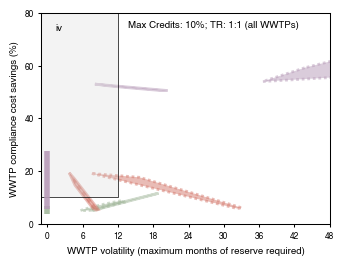

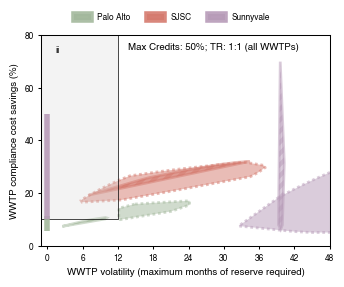

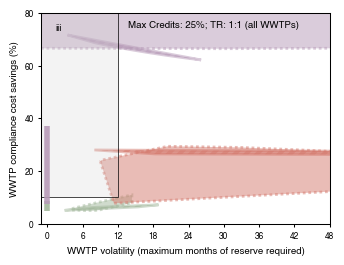

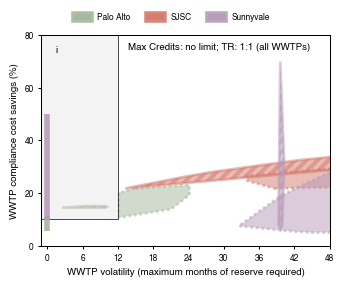

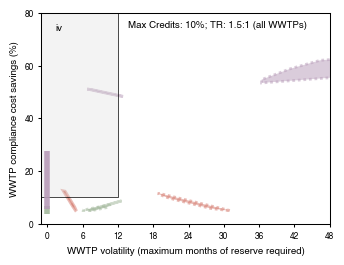

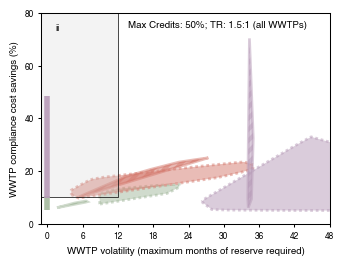

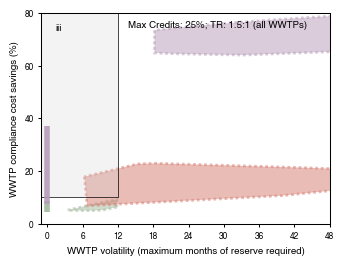

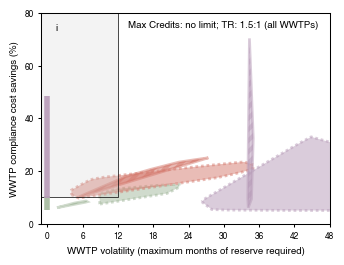

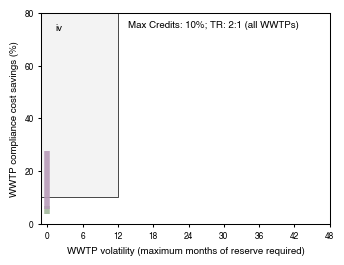

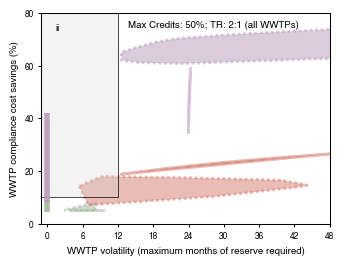

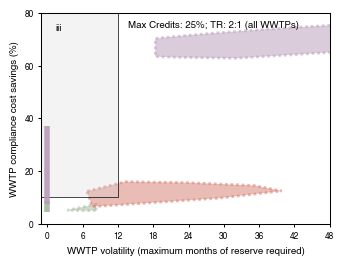

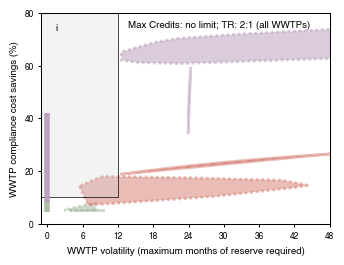

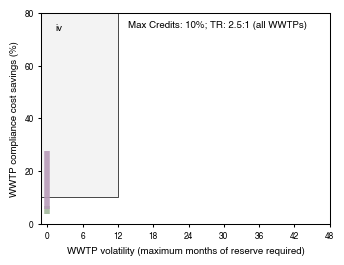

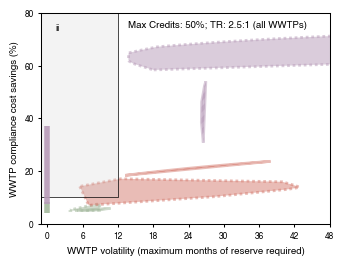

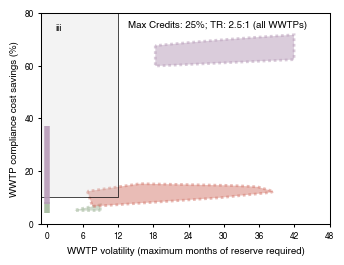

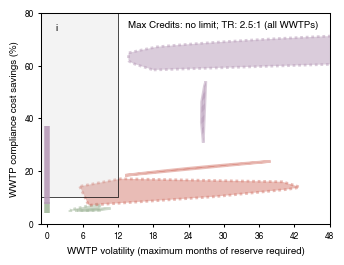

In [75]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull, QhullError
from collections import OrderedDict
import matplotlib.patheffects as pe
from matplotlib.patches import Polygon
import matplotlib as mpl
import matplotlib.colors as mcolors

mpl.rcParams['hatch.linewidth'] = 3  


colors_mad = ['#1b9e77', '#7570b3', '#e7298a']
color_markets = {'Clearinghouse': '#4E79A7', 'Exchange Market': '#C97C5D', 'Bilateral Contract': '#1b9e77'}
linestyles_WWTPs = {'Palo Alto': 'solid', 'SJSC': 'dashed', 'Sunnyvale': 'dotted'}
linestyles_markets = {'Clearinghouse': 'solid', 'Exchange Market': (0, (1, 1)), 'Bilateral Contract': (0, (1, 4))}


# plot ratepayer mad_markets vs total_cost_savings
WWTPs = ['Palo Alto', 'SJSC', 'Sunnyvale']
hatches_WWTPs = {'Palo Alto': '///////', 'SJSC': '...', 'Sunnyvale': '*****'}
hatches_markets = {'Clearinghouse': '///', 'Exchange Market': '', 'Bilateral Contract': ''}
alpha_markets = {'Clearinghouse': 0.5, 'Exchange Market': 0.5, 'Bilateral Contract': 0.7}
colors_WWTP = {'Sunnyvale': '#B79BB8', 'SJSC': '#D57A6E', 'Palo Alto': '#A3B89C'}
lw_WWTPs = {'Palo Alto': 2, 'SJSC': 2, 'Sunnyvale': 2}
WWTPs_list = ['Palo Alto']

TR_HP_tuples = dfs_markets_all.keys()

labels_text = {300: 'i', 0.5: 'ii', 0.25: 'iii', 0.1: 'iv'}

for i, tuple in enumerate(TR_HP_tuples):
    print(f'Plotting TR: {tuple[0]}, HP: {tuple[1]}')
    fig, axs = plt.subplots(1, 1, figsize=(90/25.4, 70/25.4))
    total_cost_savings = total_cost_savings_all[tuple]
    dfs_markets = dfs_markets_all[tuple]
    
    for w in WWTPs:    
        reserve_months = reserve_markets_all[tuple][w]

        # check if any of the markets have less than 0% cost savings,
        market_list_OPERATIONAL = []
        for market in total_cost_savings.keys():
            if not any(total_cost_savings[market][WWTP] < 5 for WWTP in WWTPs):
                market_list_OPERATIONAL.append(market)
            elif 'BT' in market:
                market_list_OPERATIONAL.append(market)

        #print(f'Operational markets for {tuple[0]} and HP {tuple[1]}: {market_list_OPERATIONAL}')
        market_list_names = {'Clearinghouse': [], 'Exchange Market': [], 'Bilateral Contract': []}
        reserve_months_markets = {'Clearinghouse': [], 'Exchange Market': [], 'Bilateral Contract': []}
        total_cost_savings_markets = {'Clearinghouse': [], 'Exchange Market': [], 'Bilateral Contract': []}

        market_list_names_total = {'Clearinghouse': [], 'Exchange Market': [], 'Bilateral Contract': []}
        # plot basecase
        markers_markets = {'Clearinghouse': 'o', 'Exchange Market': '*', 'Bilateral Contract': 'D'}
        
        for market in total_cost_savings.keys():
            if any(tag in market for tag in ('AC', 'CW', 'OW')):
                market_list_names_total['Clearinghouse'].append(market)
            elif 'EM' in market:
                market_list_names_total['Exchange Market'].append(market)
            elif 'BT' in market:
                market_list_names_total['Bilateral Contract'].append(market)



        for j, market in enumerate(market_list_OPERATIONAL):
            markers = ['o', 's', 'v', 'D', '^', 'P', '*', 'X', '<', '>']
            if any(tag in market for tag in ('AC', 'CW', 'OW')):
                market_list_names['Clearinghouse'].append(market)
                reserve_months_markets['Clearinghouse'].append(reserve_months[market])
                total_cost_savings_markets['Clearinghouse'].append(total_cost_savings[market][w])
            elif 'EM' in market:
                market_list_names['Exchange Market'].append(market)
                reserve_months_markets['Exchange Market'].append(reserve_months[market])
                total_cost_savings_markets['Exchange Market'].append(total_cost_savings[market][w])
            elif 'BT' in market:
                market_list_names['Bilateral Contract'].append(market)
                reserve_months_markets['Bilateral Contract'].append(reserve_months[market])
                total_cost_savings_markets['Bilateral Contract'].append(total_cost_savings[market][w])
            
            #"""
        
        market_list_short = ['Clearinghouse', 'Exchange Market']
        for j, market in enumerate(market_list_names.keys()):
            x = np.asarray(reserve_months_markets[market])
            y = np.asarray(total_cost_savings_markets[market])
            
            pts = np.column_stack([x, y])
            print(f'    WWTP: {w}, Market: {market}, Market list total: {len(market_list_names_total[market])}, Market list operational: {len(market_list_names[market])}, Points: {pts.shape[0]}')
            if pts.shape[0] == 0:
                continue
            if market in market_list_short:
                try:
                    hull = ConvexHull(pts)
                    poly = pts[hull.vertices]

                    patch = Polygon(
                        poly, closed=True,
                        facecolor=colors_WWTP[w],
                        edgecolor=colors_WWTP[w],   # hatch commonly uses edgecolor in SVG
                        linewidth=lw_WWTPs[w],
                        linestyle=linestyles_markets[market],
                        hatch=hatches_markets[market],
                        alpha=alpha_markets[market],
                        zorder=0
                    )
                    axs.add_patch(patch)
                    patch.set_rasterized(True)
                    try:
                        patch.set_hatchcolor(colors_WWTP[w])
                    except Exception:
                        pass
                except:
                    i_min = np.argmin(pts[:,0])
                    i_max = np.argmax(pts[:,0])
                    seg = pts[[i_min, i_max]]
                    patch = Polygon(seg, closed=True, fill=False, edgecolor=colors_WWTP[w], lw=3, linestyle=linestyles_markets[market], alpha = 1)
                    axs.add_patch(patch)
            else:
                i_min = 0
                i_max = len(pts) - 1
                seg = pts[[i_min, i_max]]
                patch = Polygon(seg, closed=True, fill=colors_WWTP[w], edgecolor=colors_WWTP[w], lw=4, linestyle='solid', alpha = 0.9, label = w, facecolor=colors_WWTP[w], zorder = 5)
                # larger polygon thickness
                axs.add_patch(patch)

        
    axs.set_ylabel(f'WWTP compliance cost savings (%)', **hfont)
    axs.set_xlabel(f'WWTP volatility (maximum months of reserve required)', **hfont)
    
    
    axs.text(0.05, 0.95, f'{labels_text[tuple[1]]}', **hfont, color='black', ha = 'left', va = 'top', transform=axs.transAxes)
    axs.tick_params(axis="both", width=line_wid, length=bord_wid, labelsize=leg_size)
    for spine in axs.spines.values():
        spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)
    #TR = 'Trading ratio: ' + str(int(tuple[0])) + ':1'
    if tuple[0] == int(tuple[0]):
            TR = 'TR: ' + str(int(tuple[0])) + ':1'
    else:
        TR = 'TR: ' + str(round(tuple[0], 1)) + ':1'
    min_treatment = 'Max Credits: ' + str(round(tuple[1]*100)) + '%'
    #if tuple[1] == 300:
    #    min_treatment = 'No limit on max credits'
    if tuple[1] == 300:
        min_treatment = 'Max Credits: no limit'
    
    axs.text(0.3, 0.92, f'{min_treatment}; {TR} (all WWTPs)', **hfont, color='black', ha = 'left', va = 'bottom', transform=axs.transAxes)
    
    # check if any of the markets are successful:
    savings_markets = []
    min_sav = 10
    max_vol = 12
    max_diff = 20
    savings_markets_within_N = []
    volatility_markets = []
    successful_markets = []
    successful_markets_2 = []
    print('Successful markets:')
    for market in total_cost_savings.keys():
        #all WWTPs have at least 10% cost savings
        if 'BT' not in market:
            if all(total_cost_savings[market][WWTP] >= min_sav for WWTP in WWTPs):
                savings_markets.append(market)
                if max(total_cost_savings[market][WWTP] for WWTP in WWTPs) - min(total_cost_savings[market][WWTP] for WWTP in WWTPs) <= max_diff:
                    savings_markets_within_N.append(market)
        else:
            # only two WWTPs should have at least 10% cost savings since BT only applies to two WWTPs
            if sum(total_cost_savings[market][WWTP] >= min_sav for WWTP in WWTPs) >= 2:
                WWTP_in_BT = [WWTP for WWTP in WWTPs if total_cost_savings[market][WWTP] >= min_sav]
                savings_markets.append(market)
                if max(total_cost_savings[market][WWTP] for WWTP in WWTP_in_BT) - min(total_cost_savings[market][WWTP] for WWTP in WWTP_in_BT) <= max_diff:
                    savings_markets_within_N.append(market)
        if all(reserve_markets_all[tuple][w][market] <= max_vol for w in WWTPs):
                volatility_markets.append(market)
        
        if market in savings_markets and market in volatility_markets:
            successful_markets.append(market)
        
        if market in savings_markets_within_N and market in volatility_markets:
            successful_markets_2.append(market)

    
    #print(f'    Successful markets for min savings of {min_sav}%: {tuple[0]} and HP {tuple[1]}: {savings_markets}')
    for market in savings_markets:
        #print(f'        {market}: {", ".join([f"{WWTP}: {round(total_cost_savings[market][WWTP])}%" for WWTP in WWTPs])}')
        #print(f'        {market}: {", ".join([f"{WWTP}: {round(reserve_markets_all[tuple][WWTP][market])} months" for WWTP in WWTPs])}')
        continue
    #print(f'    Successful markets for max volatility of {max_vol} months: {tuple[0]} and HP {tuple[1]}: {volatility_markets}')
    #print(f'    Successful markets for both savings and volatility: {tuple[0]} and HP {tuple[1]}: {len(successful_markets)}, {successful_markets}')
    #print(f'    Successful markets and savings within {N}%: {tuple[0]} and HP {tuple[1]}: {successful_markets_2}: {WWTP + str([total_cost_savings[market][WWTP] for WWTP in WWTPs for market in successful_markets_2])}')
    #print(f'    Successful markets and savings within {max_diff}%: {tuple[0]} and HP {tuple[1]}, {len(successful_markets_2)}, {successful_markets_2}')
    #for market in successful_markets_2:
    #    print(f'        {market}: {", ".join([f"{WWTP}: {round(total_cost_savings[market][WWTP])}%" for WWTP in WWTPs])}')
    
    
    #add rectangular box from y=10 and x=0 to y=100 and x=50
    axs.add_patch(Polygon(
    [[-1, min_sav], [max_vol, min_sav], [max_vol, 100], [-1, 100]],
    closed=True,
    fill=True,
    facecolor=mcolors.to_rgba('lightgray', 0.25),
    edgecolor=(0, 0, 0, 1),                        # opaque edge, no alpha
    lw=0.5,
    linestyle='-',
    zorder=1,
    #label = 'Successful market criteria (volatility ≤ 40% and savings ≥ 10%)'
    #label = f'Successful market criteria (min. {min_sav}% savings and max. {max_vol} month reserve)'
    label = ''
    ))
    
    #axs.legend(loc='upper center', frameon=False, prop={'family':'Helvetica', 'size':leg_size}, ncol=3, bbox_to_anchor=(0.5, 0.88))
    
    x_max_all = 48
    x_max_ticks_all = 6
    y_max_all = 80
    y_max_ticks_all = 20
    
    axs.set_xlim(-1, x_max_all)
    axs.set_xticks(np.arange(0, x_max_all + 1, x_max_ticks_all))
    axs.set_ylim(0, y_max_all)
    axs.set_yticks(np.arange(0, y_max_all + 1, y_max_ticks_all))
    axs.set_xticklabels(axs.get_xticks(), **hfont_ticks)
    axs.set_yticklabels(axs.get_yticks(), **hfont_ticks)
    

    # add legend for above the figure
    handles, labels = axs.get_legend_handles_labels()
    by_label = OrderedDict(zip(labels, handles))
    if (tuple[0] == 1.0 and tuple[1] == 300) | (tuple[0] == 1.0 and tuple[1] == 0.5):
        fig.legend(by_label.values(), by_label.keys(), loc='upper center', frameon=False, prop={'family':'Helvetica', 'size':leg_size}, ncol=4, bbox_to_anchor=(0.5, 1.04), labelspacing=0.8)

    fig.tight_layout()
    name = f'SI/WWTP_CoC_vs_vol_TR_{tuple[0]}_HP_{tuple[1]}'
    plt.savefig(file + f'/{name}.svg', format='svg', dpi=300, bbox_inches='tight')

Operational markets for 1.0 and HP 300: ['CH-AC', 'CH-CW1.5OW1.5', 'CH-CW1.5OW2.0', 'CH-CW1.5OW2.5', 'CH-CW1.5OW3.0', 'CH-CW1.5OW3.5', 'CH-CW1.5OW4.0', 'CH-CW1.5OW4.5', 'CH-CW1.5OW5.0', 'CH-CW2.0OW1.5', 'CH-CW2.0OW2.0', 'CH-CW2.0OW2.5', 'CH-CW2.0OW3.0', 'CH-CW2.0OW3.5', 'CH-CW2.0OW4.0', 'CH-CW2.0OW4.5', 'CH-CW2.0OW5.0', 'CH-CW2.5OW1.5', 'CH-CW2.5OW2.0', 'CH-CW2.5OW2.5', 'CH-CW2.5OW3.0', 'CH-CW2.5OW3.5', 'CH-CW2.5OW4.0', 'CH-CW2.5OW4.5', 'CH-CW2.5OW5.0', 'CH-CW3.0OW1.5', 'CH-CW3.0OW2.0', 'CH-CW3.0OW2.5', 'CH-CW3.0OW3.0', 'CH-CW3.0OW3.5', 'CH-CW3.5OW1.5', 'EM70', 'EMSJ70SV70PA65', 'EMSJ70SV70PA60', 'EMSJ70SV70PA55', 'EMSJ70SV70PA50', 'EMSJ70SV70PA45', 'EMSJ70SV70PA40', 'EMSJ70SV70PA35', 'EMSJ70SV70PA30', 'EMSJ70SV70PA25', 'EMSJ70SV70PA20', 'EMSJ70SV70PA15', 'EMSJ70SV70PA10', 'EMSJ70SV65PA70', 'EMSJ70SV65PA65', 'EMSJ70SV65PA60', 'EMSJ70SV65PA55', 'EMSJ70SV65PA50', 'EMSJ70SV65PA45', 'EMSJ70SV65PA40', 'EMSJ70SV65PA35', 'EMSJ70SV65PA30', 'EMSJ70SV65PA25', 'EMSJ70SV65PA20', 'EMSJ70SV65PA15', 

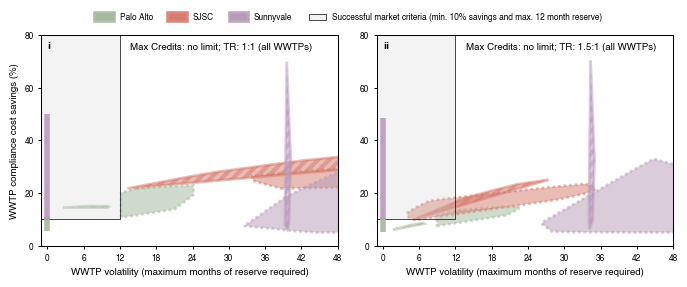

In [76]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull, QhullError
from collections import OrderedDict
import matplotlib.patheffects as pe
from matplotlib.patches import Polygon
import matplotlib as mpl
import matplotlib.colors as mcolors

mpl.rcParams['hatch.linewidth'] = 3 


colors_mad = ['#1b9e77', '#7570b3', '#e7298a']
color_markets = {'Clearinghouse': '#4E79A7', 'Exchange Market': '#C97C5D', 'Bilateral Contract': '#1b9e77'}
linestyles_WWTPs = {'Palo Alto': 'solid', 'SJSC': 'dashed', 'Sunnyvale': 'dotted'}
linestyles_markets = {'Clearinghouse': 'solid', 'Exchange Market': (0, (1, 1)), 'Bilateral Contract': (0, (1, 4))}


# plot ratepayer mad_markets vs total_cost_savings
WWTPs = ['Palo Alto', 'SJSC', 'Sunnyvale']
hatches_WWTPs = {'Palo Alto': '///////', 'SJSC': '...', 'Sunnyvale': '*****'}
hatches_markets = {'Clearinghouse': '///', 'Exchange Market': '', 'Bilateral Contract': ''}
alpha_markets = {'Clearinghouse': 0.5, 'Exchange Market': 0.5, 'Bilateral Contract': 0.7}
colors_WWTP = {'Sunnyvale': '#B79BB8', 'SJSC': '#D57A6E', 'Palo Alto': '#A3B89C'}
lw_WWTPs = {'Palo Alto': 2, 'SJSC': 2, 'Sunnyvale': 2}
WWTPs_list = ['Palo Alto']

#TR_HP_tuples = [(1.0, 300), (2.0, 300), (1.0, 0.25)]
TR_HP_tuples = [(1.0, 300), (1.5, 300)]
#TR_HP_tuples = [(1.0, 300), (2.0, 300)]
fig, ax = plt.subplots(1, len(TR_HP_tuples), figsize=(180/25.4, 70/25.4))
fig_labels = ['i', 'ii', 'iii', 'iv']

for i, tuple in enumerate(TR_HP_tuples):
    axs = ax[i] 
    total_cost_savings = total_cost_savings_all[tuple]
    dfs_markets = dfs_markets_all[tuple]
    
    for w in WWTPs:    
        reserve_months = reserve_markets_all[tuple][w]

        # check if any of the markets have less than 0% cost savings,
        market_list_OPERATIONAL = []
        for market in total_cost_savings.keys():
            if not any(total_cost_savings[market][WWTP] < 5 for WWTP in WWTPs):
                market_list_OPERATIONAL.append(market)
            elif 'BT' in market:
                market_list_OPERATIONAL.append(market)

        print(f'Operational markets for {tuple[0]} and HP {tuple[1]}: {market_list_OPERATIONAL}')
        market_list_names = {'Clearinghouse': [], 'Exchange Market': [], 'Bilateral Contract': []}
        reserve_months_markets = {'Clearinghouse': [], 'Exchange Market': [], 'Bilateral Contract': []}
        total_cost_savings_markets = {'Clearinghouse': [], 'Exchange Market': [], 'Bilateral Contract': []}


        # plot basecase
        markers_markets = {'Clearinghouse': 'o', 'Exchange Market': '*', 'Bilateral Contract': 'D'}
        
        for j, market in enumerate(market_list_OPERATIONAL):
            markers = ['o', 's', 'v', 'D', '^', 'P', '*', 'X', '<', '>']
            
            """
            if 'AC' in market:
                axs.scatter(mad_markets_norm[market], total_cost_savings[market][w], color=colors_WWTP[w], marker='o', s=60, label = 'AC', zorder = 3)
            
            elif 'NM' in market:
                continue
                axs[i].scatter(mad_markets_norm[market], total_cost_savings[market][w], color='black', marker='^', s=60, label = '', zorder = 2)
            elif 'EM50' in market:
                axs.scatter(mad_markets_norm[market], total_cost_savings[market][w], color=colors_WWTP[w], marker='*', s=100, label = 'EM50', zorder = 3)
            elif 'BT50' in market:
                if w == 'SJSC':
                    continue
                axs.scatter(mad_markets_norm[market], total_cost_savings[market][w], color=colors_WWTP[w], marker='D', s=60, label = 'BT50', zorder = 3)
            """
            if any(tag in market for tag in ('AC', 'CW', 'OW')):
                market_list_names['Clearinghouse'].append(market)
                reserve_months_markets['Clearinghouse'].append(reserve_months[market])
                total_cost_savings_markets['Clearinghouse'].append(total_cost_savings[market][w])
            elif 'EM' in market:
                market_list_names['Exchange Market'].append(market)
                reserve_months_markets['Exchange Market'].append(reserve_months[market])
                total_cost_savings_markets['Exchange Market'].append(total_cost_savings[market][w])
            elif 'BT' in market:
                market_list_names['Bilateral Contract'].append(market)
                reserve_months_markets['Bilateral Contract'].append(reserve_months[market])
                total_cost_savings_markets['Bilateral Contract'].append(total_cost_savings[market][w])
            
            #"""
        
        market_list_short = ['Clearinghouse', 'Exchange Market']
        #for j, market in enumerate(market_list_short):
        for j, market in enumerate(market_list_names.keys()):
            x = np.asarray(reserve_months_markets[market])
            y = np.asarray(total_cost_savings_markets[market])
            
            pts = np.column_stack([x, y])
            if market in market_list_short:
                try:
                    hull = ConvexHull(pts)
                    poly = pts[hull.vertices]
                    #axs.fill(poly[:,0], poly[:,1], alpha=alpha_markets[market], edgecolor=colors_WWTP[w], facecolor=colors_WWTP[w], lw=lw_WWTPs[w], zorder = 0, label = '', linestyle = linestyles_markets[market], hatch = hatches_markets[market])

                    patch = Polygon(
                        poly, closed=True,
                        facecolor=colors_WWTP[w],
                        edgecolor=colors_WWTP[w],   # hatch commonly uses edgecolor in SVG
                        linewidth=lw_WWTPs[w],
                        linestyle=linestyles_markets[market],
                        hatch=hatches_markets[market],
                        alpha=alpha_markets[market],
                        zorder=0
                    )
                    axs.add_patch(patch)
                    patch.set_rasterized(True)
                    try:
                        patch.set_hatchcolor(colors_WWTP[w])
                    except Exception:
                        pass
                except:
                    i_min = np.argmin(pts[:,0])
                    i_max = np.argmax(pts[:,0])
                    seg = pts[[i_min, i_max]]
                    patch = Polygon(seg, closed=True, fill=False, edgecolor=colors_WWTP[w], lw=3, linestyle=linestyles_markets[market], alpha = 1)
                    axs.add_patch(patch)
            else:
                i_min = 0
                i_max = len(pts) - 1
                seg = pts[[i_min, i_max]]
                patch = Polygon(seg, closed=True, fill=colors_WWTP[w], edgecolor=colors_WWTP[w], lw=4, linestyle='solid', alpha = 0.9, label = w, facecolor=colors_WWTP[w], zorder = 5)
                # larger polygon thickness
                axs.add_patch(patch)

        
    axs.set_ylabel(f'WWTP compliance cost savings (%)', **hfont)
    axs.set_xlabel(f'WWTP volatility (maximum months of reserve required)', **hfont)
    
    
    if i == 0:
        #axs.legend(loc='upper center', frameon=False, prop={'family':'Helvetica', 'size':leg_size}, ncol=3, bbox_to_anchor=(0.5, 0.88))
        #axs.legend(loc='center', frameon=False, prop={'family':'Helvetica', 'size':leg_size}, ncol=4, bbox_to_anchor=(1.1, 1.1), labelspacing=0.8)
        pass
    else:
        axs.set_ylabel('')
    
    
    axs.tick_params(axis="both", width=line_wid, length=bord_wid, labelsize=leg_size)
    for spine in axs.spines.values():
        spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)
    #TR = 'Trading ratio: ' + str(int(tuple[0])) + ':1'
    if tuple[0] == int(tuple[0]):
        TR = 'TR: ' + str(int(tuple[0])) + ':1'
    else:
        TR = 'TR: ' + str(round(tuple[0], 1)) + ':1'
    min_treatment = 'Max Credits: ' + str(round(tuple[1]*100)) + '%'
    #if tuple[1] == 300:
    #    min_treatment = 'No limit on max credits'
    if tuple[1] == 300:
        min_treatment = 'Max Credits: no limit'
    
    #axs.set_title(f'{min_treatment}; {TR} (all WWTPs)', **hfont)
    #axs.text(0.3, 0.88, f'{min_treatment}; {TR}\n(all WWTPs)', **hfont, color='black', ha = 'center', va = 'bottom', transform=axs.transAxes)
    #axs.text(0.2, 0.88, f'{TR}\n(all WWTPs)', **hfont, color='black', ha = 'center', va = 'bottom', transform=axs.transAxes)
    axs.text(0.3, 0.92, f'{min_treatment}; {TR} (all WWTPs)', **hfont, color='black', ha = 'left', va = 'bottom', transform=axs.transAxes)
    
    # check if any of the markets are successful:
    savings_markets = []
    min_sav = 10
    max_vol = 12
    max_diff = 20
    savings_markets_within_N = []
    volatility_markets = []
    successful_markets = []
    successful_markets_2 = []
    print('Successful markets:')
    #WWTPs = ['Palo Alto', 'SJSC']
    for market in total_cost_savings.keys():
        #all WWTPs have at least 10% cost savings
        if 'BT' not in market:
            if all(total_cost_savings[market][WWTP] >= min_sav for WWTP in WWTPs):
                savings_markets.append(market)
                if max(total_cost_savings[market][WWTP] for WWTP in WWTPs) - min(total_cost_savings[market][WWTP] for WWTP in WWTPs) <= max_diff:
                    savings_markets_within_N.append(market)
        else:
            # only two WWTPs should have at least 10% cost savings since BT only applies to two WWTPs
            if sum(total_cost_savings[market][WWTP] >= min_sav for WWTP in WWTPs) >= 2:
                WWTP_in_BT = [WWTP for WWTP in WWTPs if total_cost_savings[market][WWTP] >= min_sav]
                savings_markets.append(market)
                if max(total_cost_savings[market][WWTP] for WWTP in WWTP_in_BT) - min(total_cost_savings[market][WWTP] for WWTP in WWTP_in_BT) <= max_diff:
                    savings_markets_within_N.append(market)
                
        if all(reserve_markets_all[tuple][w][market] <= max_vol for w in ['Palo Alto', 'SJSC']):
                volatility_markets.append(market)

        
        if market in savings_markets and market in volatility_markets:
            successful_markets.append(market)
        
        if market in savings_markets_within_N and market in volatility_markets:
            successful_markets_2.append(market)

    
    print(f'    Successful markets for min savings of {min_sav}%: {tuple[0]} and HP {tuple[1]}: {savings_markets}')
    for market in savings_markets:
        print(f'        {market}: {", ".join([f"{WWTP}: {round(total_cost_savings[market][WWTP])}%" for WWTP in WWTPs])}')
        print(f'        {market}: {", ".join([f"{WWTP}: {round(reserve_markets_all[tuple][WWTP][market])} months" for WWTP in WWTPs])}')
    print(f'    Successful markets for max volatility of {max_vol} months: {tuple[0]} and HP {tuple[1]}: {volatility_markets}')
    print(f'    Successful markets for both savings and volatility: {tuple[0]} and HP {tuple[1]}: {len(successful_markets)}, {successful_markets}')
    #print(f'    Successful markets and savings within {N}%: {tuple[0]} and HP {tuple[1]}: {successful_markets_2}: {WWTP + str([total_cost_savings[market][WWTP] for WWTP in WWTPs for market in successful_markets_2])}')
    print(f'    Successful markets and savings within {max_diff}%: {tuple[0]} and HP {tuple[1]}, {len(successful_markets_2)}, {successful_markets_2}')
    for market in successful_markets_2:
        print(f'        {market}: {", ".join([f"{WWTP}: {round(total_cost_savings[market][WWTP])}%" for WWTP in WWTPs])}')
    
    
    #add rectangular box from y=10 and x=0 to y=100 and x=50
    axs.add_patch(Polygon(
    [[-1, min_sav], [max_vol, min_sav], [max_vol, 100], [-1, 100]],
    closed=True,
    fill=True,
    facecolor=mcolors.to_rgba('lightgray', 0.25),
    edgecolor=(0, 0, 0, 1),                        # opaque edge, no alpha
    lw=0.5,
    linestyle='-',
    zorder=1,
    #label = 'Successful market criteria (volatility ≤ 40% and savings ≥ 10%)'
    label = f'Successful market criteria (min. {min_sav}% savings and max. {max_vol} month reserve)'
    ))
    
    #axs.legend(loc='upper center', frameon=False, prop={'family':'Helvetica', 'size':leg_size}, ncol=3, bbox_to_anchor=(0.5, 0.88))
    
    x_max_all = 48
    x_max_ticks_all = 6
    y_max_all = 80
    y_max_ticks_all = 20
    
    axs.set_xlim(-1, x_max_all)
    axs.set_xticks(np.arange(0, x_max_all + 1, x_max_ticks_all))
    axs.set_ylim(0, y_max_all)
    axs.set_yticks(np.arange(0, y_max_all + 1, y_max_ticks_all))
    axs.set_xticklabels(axs.get_xticks(), **hfont_ticks)
    axs.set_yticklabels(axs.get_yticks(), **hfont_ticks)
    

#t= fig.supxlabel(f'WWTP standard deviation of ratepayer bill (%)', **hfont)
#t.set_y(0.05)   # increase -> closer to the y-axis; decrease -> farther left

# add legend for above the figure
handles, labels = ax[0].get_legend_handles_labels()
by_label = OrderedDict(zip(labels, handles))
fig.legend(by_label.values(), by_label.keys(), loc='upper center', frameon=False, prop={'family':'Helvetica', 'size':leg_size}, ncol=4, bbox_to_anchor=(0.5, 1.04), labelspacing=0.8)

#fig_labels = ['i', 'ii', 'iii', 'iv']
for i,axs in enumerate(ax):
    axs.text(0.02, 0.97, fig_labels[i], transform=axs.transAxes, fontsize=lab_size, fontweight='bold', va='top', ha='left')
#make sure legend does not get cropped out in final savefig
fig.tight_layout()

plt.savefig(file + f'/Fig_4c_1pt5.svg', format='svg', dpi=300, bbox_inches='tight')
#plt.savefig(file + f'/{name}.png', format='png', dpi=300)

In [77]:
markets = ['EM70', 'EMSJ70SV70PA65', 'EMSJ70SV65PA70', 'EMSJ70SV65PA65', 'EMSJ70SV65PA60', 'EMSJ70SV60PA70', 'EMSJ70SV60PA65', 'EMSJ70SV60PA60', 'EMSJ70SV60PA55', 'EMSJ70SV55PA70', 'EMSJ70SV55PA65', 'EMSJ70SV55PA60', 'EMSJ70SV55PA55', 'EMSJ70SV55PA50', 'EMSJ70SV50PA70', 'EMSJ70SV50PA65', 'EMSJ70SV50PA60', 'EMSJ70SV50PA55', 'EMSJ70SV50PA50', 'EMSJ70SV50PA45', 'EMSJ70SV45PA70', 'EMSJ70SV45PA65', 'EMSJ70SV45PA60', 'EMSJ70SV45PA55', 'EMSJ70SV45PA50', 'EMSJ70SV45PA45', 'EMSJ70SV45PA40', 'EMSJ70SV40PA70', 'EMSJ70SV40PA65', 'EMSJ70SV40PA60', 'EMSJ70SV40PA55', 'EMSJ70SV40PA50', 'EMSJ70SV40PA45', 'EMSJ70SV40PA40', 'EMSJ70SV40PA35', 'EMSJ70SV35PA70', 'EMSJ70SV35PA65', 'EMSJ70SV35PA60', 'EMSJ70SV35PA55', 'EMSJ70SV35PA50', 'EMSJ70SV35PA45', 'EMSJ70SV35PA40', 'EMSJ70SV35PA35', 'EMSJ65SV70PA70', 'EMSJ65SV70PA65', 'EMSJ65SV70PA60', 'EMSJ65SV70PA55', 'EMSJ65SV65PA70', 'EM65', 'EMSJ65SV65PA60', 'EMSJ65SV65PA55', 'EMSJ65SV65PA50', 'EMSJ65SV60PA70', 'EMSJ65SV60PA65', 'EMSJ65SV60PA60', 'EMSJ65SV60PA55', 'EMSJ65SV60PA50', 'EMSJ65SV60PA45', 'EMSJ65SV55PA70', 'EMSJ65SV55PA65', 'EMSJ65SV55PA60', 'EMSJ65SV55PA55', 'EMSJ65SV55PA50', 'EMSJ65SV55PA45', 'EMSJ65SV55PA40', 'EMSJ65SV50PA70', 'EMSJ65SV50PA65', 'EMSJ65SV50PA60', 'EMSJ65SV50PA55', 'EMSJ65SV50PA50', 'EMSJ65SV50PA45', 'EMSJ65SV50PA40', 'EMSJ65SV50PA35', 'EMSJ65SV45PA70', 'EMSJ65SV45PA65', 'EMSJ65SV45PA60', 'EMSJ65SV45PA55', 'EMSJ65SV45PA50', 'EMSJ65SV45PA45', 'EMSJ65SV45PA40', 'EMSJ65SV45PA35', 'EMSJ65SV45PA30', 'EMSJ65SV40PA70', 'EMSJ65SV40PA65', 'EMSJ65SV40PA60', 'EMSJ65SV40PA55', 'EMSJ65SV40PA50', 'EMSJ60SV70PA70', 'EMSJ60SV70PA65', 'EMSJ60SV70PA60', 'EMSJ60SV70PA55', 'EMSJ60SV70PA50', 'EMSJ60SV70PA45', 'EMSJ60SV65PA70', 'EMSJ60SV65PA65', 'EMSJ60SV65PA60', 'EMSJ60SV65PA55', 'EMSJ60SV65PA50', 'EMSJ60SV65PA45', 'EMSJ60SV65PA40', 'EMSJ60SV60PA70', 'EMSJ60SV60PA65', 'EM60', 'EMSJ60SV60PA55', 'EMSJ60SV60PA50', 'EMSJ60SV60PA45', 'EMSJ60SV60PA40', 'EMSJ60SV60PA35', 'EMSJ60SV55PA70', 'EMSJ60SV55PA65', 'EMSJ60SV55PA60', 'EMSJ60SV55PA55', 'EMSJ60SV55PA50', 'EMSJ60SV55PA45', 'EMSJ60SV55PA40', 'EMSJ60SV55PA35', 'EMSJ60SV55PA30', 'EMSJ60SV50PA70', 'EMSJ60SV50PA65', 'EMSJ60SV50PA60', 'EMSJ60SV50PA55', 'EMSJ60SV50PA50', 'EMSJ60SV50PA45', 'EMSJ60SV50PA40', 'EMSJ60SV50PA35', 'EMSJ60SV50PA30', 'EMSJ60SV50PA25', 'EMSJ60SV45PA70', 'EMSJ60SV45PA65', 'EMSJ60SV45PA60', 'EMSJ55SV70PA70', 'EMSJ55SV70PA65', 'EMSJ55SV70PA60', 'EMSJ55SV70PA55', 'EMSJ55SV70PA50', 'EMSJ55SV70PA45', 'EMSJ55SV70PA40', 'EMSJ55SV70PA35', 'EMSJ55SV70PA30', 'EMSJ55SV65PA70', 'EMSJ55SV65PA65', 'EMSJ55SV65PA60', 'EMSJ55SV65PA55', 'EMSJ55SV65PA50', 'EMSJ55SV65PA45', 'EMSJ55SV65PA40', 'EMSJ55SV65PA35', 'EMSJ55SV65PA30', 'EMSJ55SV65PA25', 'EMSJ55SV60PA70', 'EMSJ55SV60PA65', 'EMSJ55SV60PA60', 'EMSJ55SV60PA55', 'EMSJ55SV60PA50', 'EMSJ55SV60PA45', 'EMSJ55SV60PA40', 'EMSJ55SV60PA35', 'EMSJ55SV60PA30', 'EMSJ55SV60PA25', 'EMSJ55SV60PA20', 'EMSJ55SV55PA70', 'EMSJ55SV55PA65', 'EMSJ55SV55PA60', 'EM55', 'EMSJ55SV55PA50', 'EMSJ55SV55PA45', 'EMSJ55SV55PA40', 'EMSJ55SV55PA35', 'EMSJ55SV55PA30', 'EMSJ50SV70PA70', 'EMSJ50SV70PA65', 'EMSJ50SV70PA60', 'EMSJ50SV70PA55', 'EMSJ50SV70PA50', 'EMSJ50SV70PA45', 'EMSJ50SV70PA40', 'EMSJ50SV70PA35', 'EMSJ50SV70PA30', 'EMSJ50SV70PA25', 'EMSJ50SV70PA20', 'EMSJ50SV70PA15', 'EMSJ50SV70PA10', 'EMSJ50SV65PA70', 'EMSJ50SV65PA65', 'EMSJ50SV65PA60', 'EMSJ50SV65PA55', 'EMSJ50SV65PA50', 'EMSJ50SV65PA45', 'EMSJ50SV65PA40', 'EMSJ50SV65PA35', 'EMSJ50SV65PA30', 'EMSJ50SV65PA25', 'EMSJ50SV65PA20', 'EMSJ50SV65PA15', 'EMSJ50SV65PA10', 'EMSJ50SV60PA70', 'EMSJ50SV60PA65', 'EMSJ50SV60PA60', 'EMSJ50SV60PA55', 'EMSJ50SV60PA50', 'EMSJ50SV60PA45', 'EMSJ45SV70PA70', 'EMSJ45SV70PA65', 'EMSJ45SV70PA60', 'EMSJ45SV70PA55', 'EMSJ45SV70PA50', 'EMSJ45SV70PA45', 'EMSJ45SV70PA40', 'EMSJ45SV70PA35', 'EMSJ45SV70PA30', 'EMSJ45SV70PA25', 'EMSJ45SV70PA20', 'EMSJ45SV70PA15', 'EMSJ45SV70PA10', 'EMSJ45SV65PA70', 'EMSJ45SV65PA65', 'EMSJ45SV65PA60', 'EMSJ45SV65PA55', 'EMSJ40SV70PA70', 'BT12', 'BT11']
markets = ['EM70', 'EMSJ70SV70PA65', 'EMSJ70SV65PA70', 'EMSJ70SV65PA65', 'EMSJ70SV65PA60', 'EMSJ70SV60PA70', 'EMSJ70SV60PA65', 'EMSJ70SV60PA60', 'EMSJ70SV60PA55', 'EMSJ70SV55PA70', 'EMSJ70SV55PA65', 'EMSJ70SV55PA60', 'EMSJ70SV55PA55', 'EMSJ70SV50PA70', 'EMSJ70SV50PA65', 'EMSJ70SV50PA60', 'EMSJ70SV50PA55', 'EMSJ70SV50PA50', 'EMSJ70SV45PA70', 'EMSJ70SV45PA65', 'EMSJ70SV45PA60', 'EMSJ70SV45PA55', 'EMSJ70SV45PA50', 'EMSJ70SV40PA70', 'EMSJ70SV40PA65', 'EMSJ70SV40PA60', 'EMSJ70SV40PA55', 'EMSJ70SV40PA50', 'EMSJ70SV35PA70', 'EMSJ70SV35PA65', 'EMSJ70SV35PA60', 'EMSJ70SV35PA55', 'EMSJ70SV35PA50', 'EMSJ70SV30PA70', 'EMSJ70SV30PA65', 'EMSJ70SV30PA60', 'EMSJ70SV30PA55', 'EMSJ70SV30PA50', 'EMSJ70SV25PA70', 'EMSJ70SV25PA65', 'EMSJ70SV25PA60', 'EMSJ70SV25PA55', 'EMSJ70SV25PA50', 'EMSJ70SV20PA70', 'EMSJ70SV20PA65', 'EMSJ70SV20PA60', 'EMSJ70SV20PA55', 'EMSJ70SV20PA50', 'EMSJ70SV20PA45', 'EMSJ65SV70PA70', 'EMSJ65SV70PA65', 'EMSJ65SV70PA60', 'EMSJ65SV70PA55', 'EMSJ65SV65PA70', 'EM65', 'EMSJ65SV65PA60', 'EMSJ65SV65PA55', 'EMSJ65SV60PA70', 'EMSJ65SV60PA65', 'EMSJ65SV60PA60', 'EMSJ65SV60PA55', 'EMSJ65SV55PA70', 'EMSJ65SV55PA65', 'EMSJ65SV55PA60', 'EMSJ65SV55PA55', 'EMSJ65SV50PA70', 'EMSJ65SV50PA65', 'EMSJ65SV50PA60', 'EMSJ65SV50PA55', 'EMSJ65SV50PA50', 'EMSJ65SV45PA70', 'EMSJ65SV45PA65', 'EMSJ65SV45PA60', 'EMSJ65SV45PA55', 'EMSJ65SV45PA50', 'EMSJ65SV40PA70', 'EMSJ65SV40PA65', 'EMSJ65SV40PA60', 'EMSJ65SV40PA55', 'EMSJ65SV40PA50', 'EMSJ65SV35PA70', 'EMSJ65SV35PA65', 'EMSJ65SV35PA60', 'EMSJ65SV35PA55', 'EMSJ65SV35PA50', 'EMSJ65SV30PA70', 'EMSJ65SV30PA65', 'EMSJ65SV30PA60', 'EMSJ65SV30PA55', 'EMSJ65SV30PA50']
len(markets)
markets_EM = [market for market in markets if 'EM' in market]
markest_BT = [market for market in markets if 'BT' in market]
print(f'Number of markets: {len(markets)}', f'Number of EM markets: {len(markets_EM)}', f'Number of BT markets: {len(markest_BT)}')

Number of markets: 90 Number of EM markets: 90 Number of BT markets: 0


Operational markets for 1.0 and HP 300: ['CH-AC', 'CH-CW1.5OW1.5', 'CH-CW1.5OW2.0', 'CH-CW1.5OW2.5', 'CH-CW1.5OW3.0', 'CH-CW1.5OW3.5', 'CH-CW1.5OW4.0', 'CH-CW1.5OW4.5', 'CH-CW1.5OW5.0', 'CH-CW2.0OW1.5', 'CH-CW2.0OW2.0', 'CH-CW2.0OW2.5', 'CH-CW2.0OW3.0', 'CH-CW2.0OW3.5', 'CH-CW2.0OW4.0', 'CH-CW2.0OW4.5', 'CH-CW2.0OW5.0', 'CH-CW2.5OW1.5', 'CH-CW2.5OW2.0', 'CH-CW2.5OW2.5', 'CH-CW2.5OW3.0', 'CH-CW2.5OW3.5', 'CH-CW2.5OW4.0', 'CH-CW2.5OW4.5', 'CH-CW3.0OW1.5', 'CH-CW3.0OW2.0', 'CH-CW3.0OW2.5', 'EM70', 'EMSJ70SV70PA65', 'EMSJ70SV70PA60', 'EMSJ70SV70PA55', 'EMSJ70SV70PA50', 'EMSJ70SV70PA45', 'EMSJ70SV70PA40', 'EMSJ70SV70PA35', 'EMSJ70SV70PA30', 'EMSJ70SV70PA25', 'EMSJ70SV70PA20', 'EMSJ70SV70PA15', 'EMSJ70SV70PA10', 'EMSJ70SV65PA70', 'EMSJ70SV65PA65', 'EMSJ70SV65PA60', 'EMSJ70SV65PA55', 'EMSJ70SV65PA50', 'EMSJ70SV65PA45', 'EMSJ70SV65PA40', 'EMSJ70SV65PA35', 'EMSJ70SV65PA30', 'EMSJ70SV65PA25', 'EMSJ70SV65PA20', 'EMSJ70SV65PA15', 'EMSJ70SV65PA10', 'EMSJ70SV60PA70', 'EMSJ70SV60PA65', 'EMSJ70SV60PA6

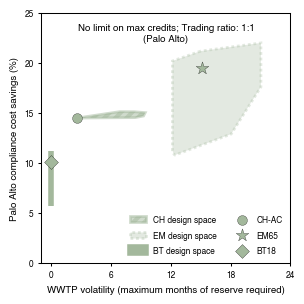

In [78]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull, QhullError
from collections import OrderedDict
import matplotlib.patheffects as pe
from matplotlib.patches import Polygon
import matplotlib as mpl

mpl.rcParams['hatch.linewidth'] = 3 


colors_mad = ['#1b9e77', '#7570b3', '#e7298a']
color_markets = {'Clearinghouse': '#4E79A7', 'Exchange Market': '#C97C5D', 'Bilateral Contract': '#1b9e77'}
linestyles_WWTPs = {'Palo Alto': 'solid', 'SJSC': 'dashed', 'Sunnyvale': 'dotted'}
linestyles_markets = {'Clearinghouse': 'solid', 'Exchange Market': (0, (1, 1)), 'Bilateral Contract': (0, (1, 4))}


# plot ratepayer mad_markets vs total_cost_savings
WWTPs = ['Palo Alto', 'SJSC', 'Sunnyvale']
hatches_WWTPs = {'Palo Alto': '///////', 'SJSC': '...', 'Sunnyvale': '*****'}
hatches_markets = {'Clearinghouse': '///', 'Exchange Market': '', 'Bilateral Contract': ''}
alpha_markets = {'Clearinghouse': 0.5, 'Exchange Market': 0.3, 'Bilateral Contract': 0.7}
colors_WWTP = {'Sunnyvale': '#B79BB8', 'SJSC': '#D57A6E', 'Palo Alto': '#A3B89C'}
lw_WWTPs = {'Palo Alto': 2, 'SJSC': 2, 'Sunnyvale': 2}
WWTPs_list = ['Palo Alto']

TR_HP_tuples = [(1.0, 300)]
EM_market = 'EM65'
BT_market = 'BT18'

for i, tuple in enumerate(TR_HP_tuples):
    fig, axs = plt.subplots(1, 1, figsize=(80/25.4, 80/25.4))
    total_cost_savings = total_cost_savings_all[tuple]
    dfs_markets = dfs_markets_all[tuple]

    
    for w in WWTPs_list:    
        reserve_months = reserve_markets_all[tuple][w]

        # check if any of the markets have less than 0% cost savings,
        market_list_OPERATIONAL = []
        for market in total_cost_savings.keys():
            if not any(total_cost_savings[market][WWTP] < 10 for WWTP in WWTPs):
                market_list_OPERATIONAL.append(market)
            elif 'BT' in market:
                market_list_OPERATIONAL.append(market)

        print(f'Operational markets for {tuple[0]} and HP {tuple[1]}: {market_list_OPERATIONAL}')
        market_list_names = {'Clearinghouse': [], 'Exchange Market': [], 'Bilateral Contract': []}
        reserve_markets_markets = {'Clearinghouse': [], 'Exchange Market': [], 'Bilateral Contract': []}
        total_cost_savings_markets = {'Clearinghouse': [], 'Exchange Market': [], 'Bilateral Contract': []}


        
        # plot basecase
        markers_markets = {'Clearinghouse': 'o', 'Exchange Market': '*', 'Bilateral Contract': 'D'}
        for j, market in enumerate(market_list_OPERATIONAL):
            markers = ['o', 's', 'v', 'D', '^', 'P', '*', 'X', '<', '>']
            
            if 'CH-AC' in market:
                axs.scatter(reserve_months[market], total_cost_savings[market][w], color=colors_WWTP[w], marker='o', s=50, edgecolors='black', linewidth=0.2, label = 'CH-AC', zorder = 5)
            #"""
            elif 'NM' in market:
                continue
                axs[i].scatter(mad_markets_norm[market], total_cost_savings[market][w], color='black', marker='^', s=60, label = '', zorder = 2)
            elif EM_market in market:
                axs.scatter(reserve_months[market], total_cost_savings[market][w], color=colors_WWTP[w], marker='*', s=90, edgecolors='black', linewidth=0.2,label = EM_market, zorder = 5)
            elif BT_market in market:
                if w == 'SJSC':
                    continue
                axs.scatter(reserve_months[market], total_cost_savings[market][w], color=colors_WWTP[w], marker='D', s=50, edgecolors='black', linewidth=0.2, label = BT_market, zorder = 5)
            #"""
            if any(tag in market for tag in ('CH-AC', 'CW', 'OW')):
                market_list_names['Clearinghouse'].append(market)
                reserve_markets_markets['Clearinghouse'].append(reserve_months[market])
                total_cost_savings_markets['Clearinghouse'].append(total_cost_savings[market][w])
            elif 'EM' in market:
                market_list_names['Exchange Market'].append(market)
                reserve_markets_markets['Exchange Market'].append(reserve_months[market])
                total_cost_savings_markets['Exchange Market'].append(total_cost_savings[market][w])
            elif 'BT' in market:
                market_list_names['Bilateral Contract'].append(market)
                reserve_markets_markets['Bilateral Contract'].append(reserve_months[market])
                total_cost_savings_markets['Bilateral Contract'].append(total_cost_savings[market][w])
            
            #"""
        
        
        market_list_short = ['Clearinghouse', 'Exchange Market']
        market_label = {'Clearinghouse': 'CH', 'Exchange Market': 'EM', 'Bilateral Contract': 'BT'}
        #for j, market in enumerate(market_list_short):
        
        for j, market in enumerate(market_list_names.keys()):    

            x = np.asarray(reserve_markets_markets[market])
            y = np.asarray(total_cost_savings_markets[market])
            print(f'    {market}: min x={np.round(min(x))}, max x={np.round(max(x))}, min y={np.round(min(y))}, max y={np.round(max(y))}')
            
            
            pts = np.column_stack([x, y])

            if market in market_list_short:
                try:
                    hull = ConvexHull(pts)
                    poly = pts[hull.vertices]
                    #axs.fill(poly[:,0], poly[:,1], alpha=alpha_markets[market], edgecolor=colors_WWTP[w], facecolor=colors_WWTP[w], lw=lw_WWTPs[w], zorder = 0, label = f'{market_label[market]} design space', linestyle = linestyles_markets[market], hatch = hatches_markets[market])

                    patch = Polygon(
                        poly, closed=True,
                        facecolor=colors_WWTP[w],
                        edgecolor=colors_WWTP[w],   # hatch commonly uses edgecolor in SVG
                        linewidth=lw_WWTPs[w],
                        linestyle=linestyles_markets[market],
                        hatch=hatches_markets[market],
                        alpha=alpha_markets[market],
                        zorder=0,
                        label = f'{market_label[market]} design space'
                    )
                    axs.add_patch(patch)
                    patch.set_rasterized(True)
                    try:
                        patch.set_hatchcolor(colors_WWTP[w])
                    except Exception:
                        pass
                
                except:
                    i_min = np.argmin(pts[:,0])
                    i_max = np.argmax(pts[:,0])
                    seg = pts[[i_min, i_max]]
                    patch = Polygon(seg, closed=True, fill=False, edgecolor=colors_WWTP[w], lw=3, linestyle=linestyles_markets[market], alpha = 1)
                    axs.add_patch(patch)

            else:
                i_min = 0
                i_max = len(pts) - 1
                seg = pts[[i_min, i_max]]
                #patch = Polygon(seg, closed=True, fill=colors_WWTP[w], edgecolor=colors_WWTP[w], lw=4, linestyle='solid', alpha = 0.9, label = w, facecolor=colors_WWTP[w], zorder = 5)
                patch = Polygon(seg, closed=True, fill=colors_WWTP[w], edgecolor=colors_WWTP[w], lw=4, linestyle='solid', alpha = 1, label = f'{market_label[market]} design space', facecolor=colors_WWTP[w])
                # larger polygon thickness
                axs.add_patch(patch)
                """
            else:
                i_min = np.argmin(pts[:,0])
                i_max = np.argmax(pts[:,0])
                seg = pts[[i_min, i_max]]
                patch = Polygon(seg, closed=True, fill=colors_WWTP[w], edgecolor=colors_WWTP[w], lw=4, linestyle='solid', alpha = 1, label = f'{market_label[market]} design space', facecolor=colors_WWTP[w])
                # larger polygon thickness
                axs.add_patch(patch)
                """
            


        
    axs.set_ylabel(f'{w} compliance cost savings (%)', **hfont)
    axs.set_xlabel(f'WWTP volatility (maximum months of reserve required)', **hfont)
    
    axs.tick_params(axis="both", width=line_wid, length=bord_wid, labelsize=leg_size)
    for spine in axs.spines.values():
        spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)
    
    x_max_all = 24
    x_max_ticks_all = 6
    y_max_all = 25
    y_max_ticks_all = 5
    axs.set_xlim(-1, x_max_all)
    axs.set_xticks(np.arange(0, x_max_all + 1, x_max_ticks_all))
    axs.set_ylim(0, y_max_all)
    axs.set_yticks(np.arange(0, y_max_all + 1, y_max_ticks_all))
    axs.set_xticklabels(axs.get_xticks(), **hfont_ticks)
    axs.set_yticklabels(axs.get_yticks(), **hfont_ticks)

    min_sav = 10
    max_vol = 30
    #add rectangular box from y=10 and x=0 to y=100 and x=50
    """
    axs.add_patch(Polygon(
    [[0, min_sav], [max_vol, min_sav], [max_vol, 100], [0, 100]],
    closed=True,
    fill=True,
    facecolor=mcolors.to_rgba('lightgray', 0.25),
    edgecolor=(0, 0, 0, 1),                        # opaque edge, no alpha
    lw=0.5,
    linestyle='-',
    zorder=1,
    #label = 'Successful market criteria (volatility ≤ 40% and savings ≥ 10%)'
    label = f'Successful market criteria (min. {min_sav}% savings and max. {max_vol}% volatility)'
    ))
    """
    
    #xtick labels are integers
    handles, labels = axs.get_legend_handles_labels()

    # de-duplicate while preserving order
    uniq = OrderedDict((l, h) for h, l in zip(handles, labels) if l != "_nolegend_")
    #left  = ['Clearinghouse', 'Exchange Market', 'Bilateral Contract']
    left = ['CH design space', 'EM design space', 'BT design space']
    right = ['CH-AC', EM_market, BT_market]
    
    order = left + right  # column-wise fill

    axs.legend([uniq[l] for l in order], order, loc='lower right', frameon=False, prop={'family':'Helvetica', 'size':leg_size}, ncol=2, labelspacing=0.8)
    #axs.legend(loc='lower right', frameon=False, prop={'family':'Helvetica', 'size':leg_size}, ncol=2)

    TR = 'Trading ratio: ' + str(int(tuple[0])) + ':1'
    min_treatment = 'Max Credits: ' + str(round(tuple[1]*100)) + '%'
    if tuple[1] == 300:
        min_treatment = 'No limit on max credits'
    
    #axs.set_title(f'{min_treatment}; {TR} (all WWTPs)', **hfont)
    axs.text(0.5, 0.88, f'{min_treatment}; {TR}\n(Palo Alto)', **hfont, color='black', ha = 'center', va = 'bottom', transform=axs.transAxes)
    
    plt.tight_layout()
    plt.savefig(file + f'/Fig_4b.svg', format='svg', dpi=300)
